In [71]:
import pandas as pd

input_path = "EMBER_2016_2024.csv"
df_analysis = pd.read_csv(input_path, sep=";", encoding="latin1")

print("Veri seti boyutu:", df_analysis.shape)
print("\nDeğişkenler:", df_analysis.columns.tolist())
print("\nİlk 5 gözlem:")
print(df_analysis.head())

Veri seti boyutu: (1863, 14)

Değişkenler: ['Area', 'Year', 'Carbon_Intensity', 'Solar', 'Wind', 'Hydro', 'Bioenergy', 'Other renewables', 'Nuclear', 'Coal', 'Gas', 'Other fossil', 'Share_Sum', 'Complete_Composition']

İlk 5 gözlem:
          Area  Year  Carbon_Intensity  Solar  Wind   Hydro  Bioenergy  Other renewables  Nuclear    Coal  Gas  Other fossil  Share_Sum  Complete_Composition
0  Afghanistan  2016           122.314  3.306   0.0  84.298        0.0               0.0      0.0   7.438  0.0         4.959    100.001                  True
1  Afghanistan  2017           132.540  3.175   0.0  83.333        0.0               0.0      0.0   8.730  0.0         4.762    100.000                  True
2  Afghanistan  2018           158.974  3.419   0.0  79.487        0.0               0.0      0.0  10.256  0.0         6.838    100.000                  True
3  Afghanistan  2019           117.123  4.110   0.0  83.562        0.0               0.0      0.0   5.479  0.0         6.849    100.000


SAMPLE VALIDATION
Observations: 1775
Reporting units: 199
Period: 2016–2024

PEARSON CORRELATION MATRIX
                  Solar   Wind  Hydro  Bioenergy  Other renewables  Nuclear   Coal    Gas  Other fossil  Carbon_Intensity
Solar             1.000  0.167 -0.175      0.058            -0.059    0.030 -0.051 -0.108         0.062            -0.096
Wind              0.167  1.000 -0.118      0.376             0.078    0.084  0.015 -0.076        -0.180            -0.260
Hydro            -0.175 -0.118  1.000      0.008             0.090   -0.118 -0.160 -0.289        -0.418            -0.765
Bioenergy         0.058  0.376  0.008      1.000             0.038    0.078 -0.040 -0.097        -0.184            -0.282
Other renewables -0.059  0.078  0.090      0.038             1.000   -0.054 -0.036 -0.096        -0.090            -0.195
Nuclear           0.030  0.084 -0.118      0.078            -0.054    1.000  0.066 -0.034        -0.233            -0.236
Coal             -0.051  0.015 -0.160    

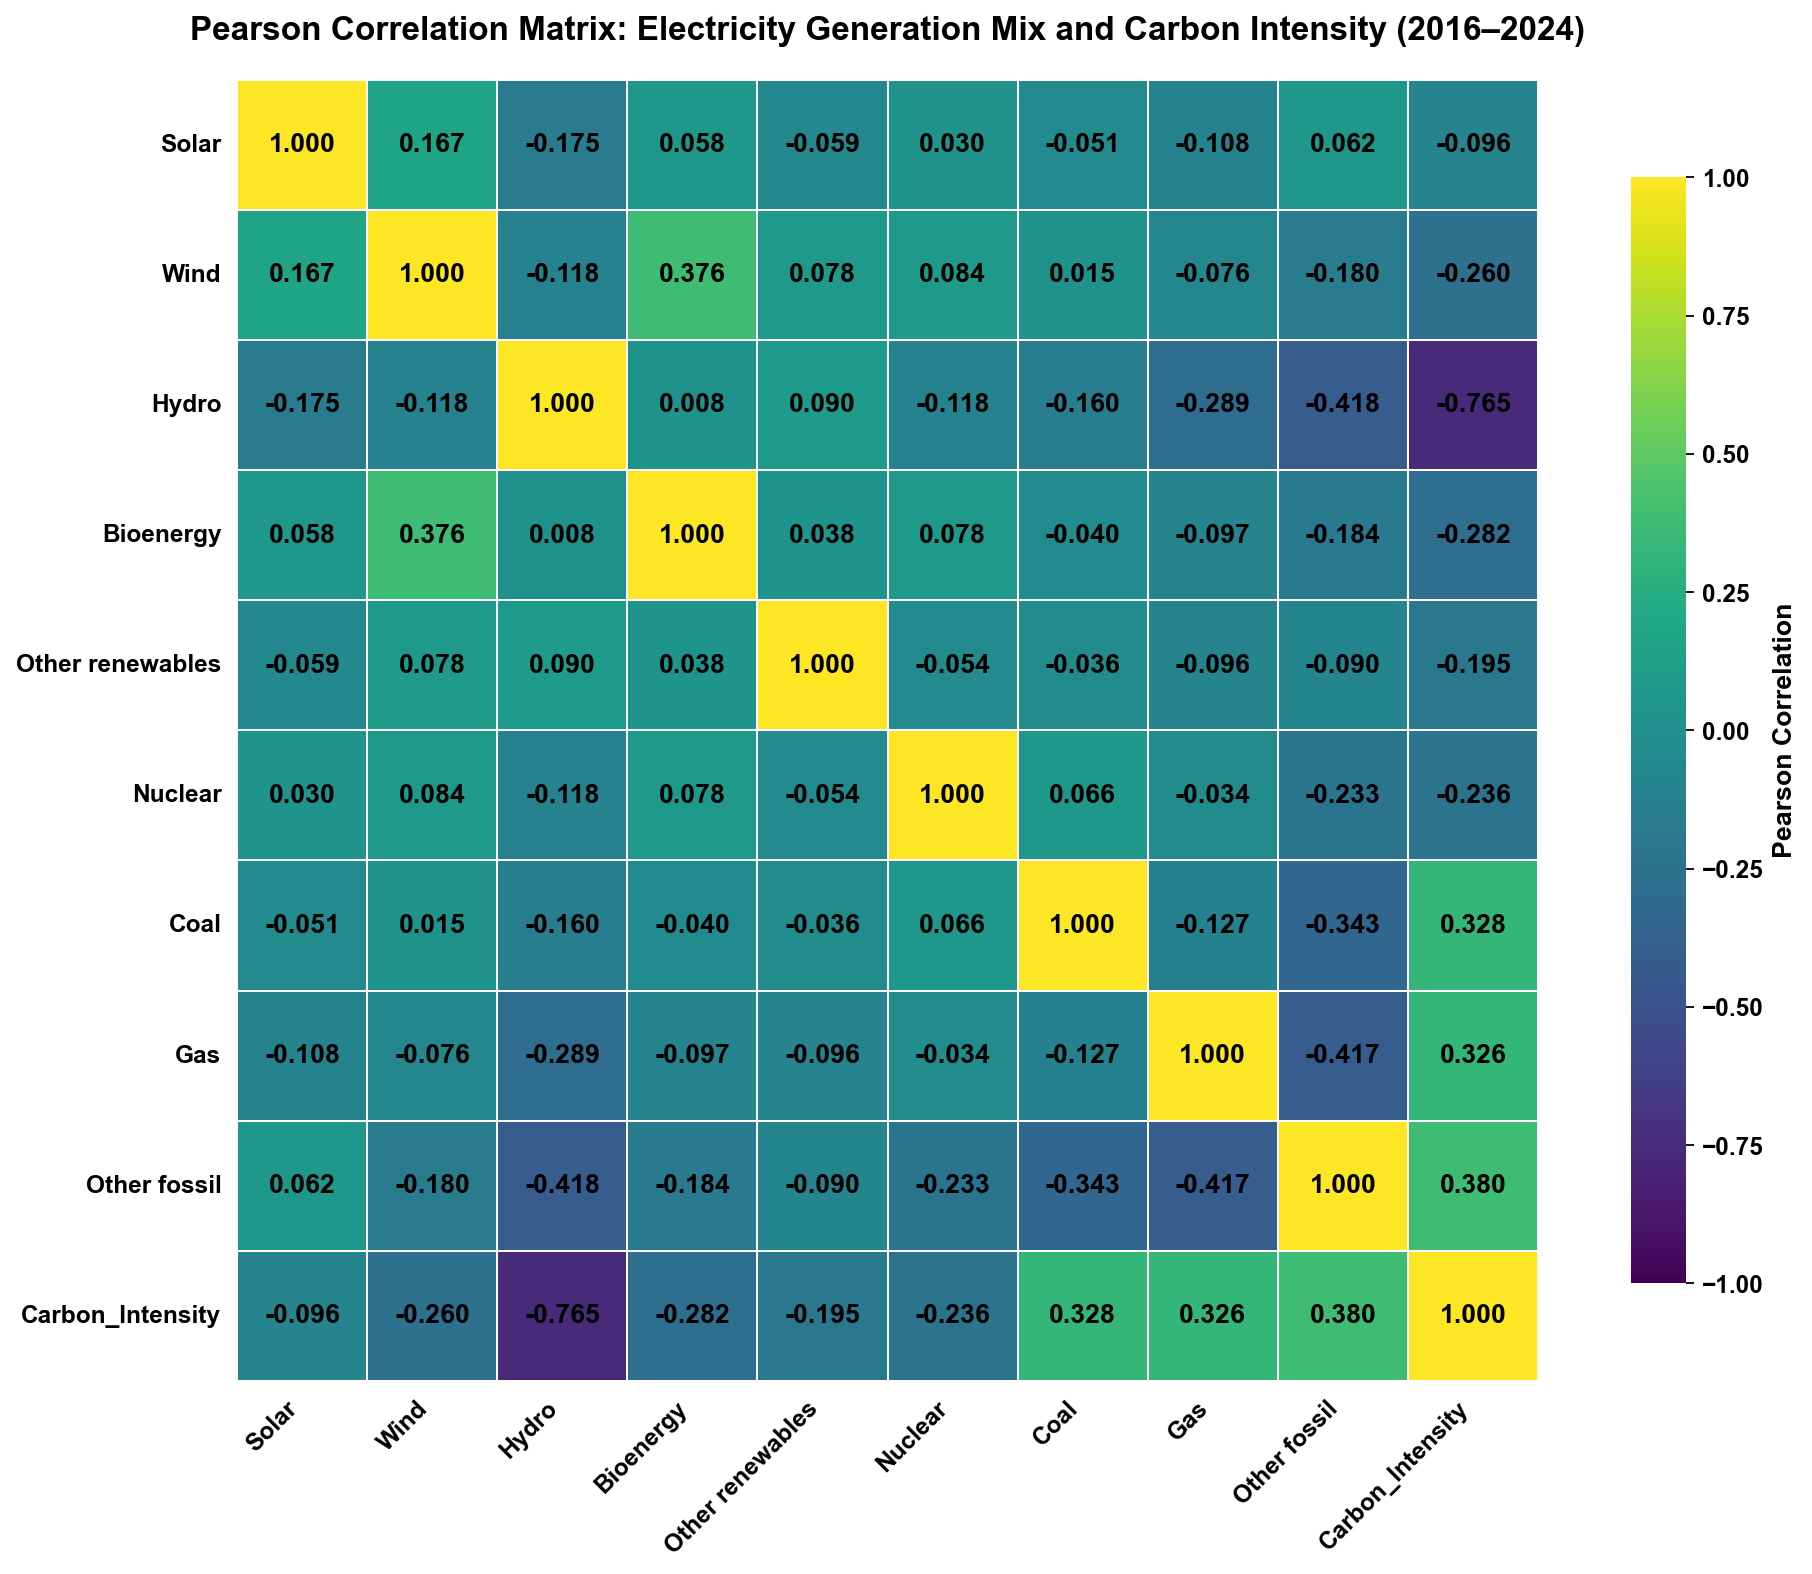

In [76]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr
from statsmodels.stats.multitest import multipletests

sources=["Solar","Wind","Hydro","Bioenergy","Other renewables","Nuclear","Coal","Gas","Other fossil"]
required=sources+["Carbon_Intensity","Year","Area"]

missing=[c for c in required if c not in df_analysis.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")

df_corr=df_analysis.loc[df_analysis["Year"].between(2016,2024),required].copy()
df_corr=df_corr.replace([np.inf,-np.inf],np.nan).dropna(subset=sources+["Carbon_Intensity"])
if len(df_corr)<3:
    raise ValueError("Insufficient complete observations for correlation analysis.")

variables=sources+["Carbon_Intensity"]
corr_matrix=df_corr[variables].corr(method="pearson")
p_matrix=pd.DataFrame(np.nan,index=variables,columns=variables)

for i in variables:
    for j in variables:
        if i==j:
            p_matrix.loc[i,j]=0.0
        else:
            valid=df_corr[[i,j]].dropna()
            if len(valid)>=3 and valid[i].nunique()>1 and valid[j].nunique()>1:
                p_matrix.loc[i,j]=pearsonr(valid[i],valid[j]).pvalue

corr_results=pd.DataFrame([
    {"Variable":v,"N":len(df_corr),"Pearson_r":corr_matrix.loc[v,"Carbon_Intensity"],
     "p_value":p_matrix.loc[v,"Carbon_Intensity"]}
    for v in sources
])
corr_results["p_BH"]=multipletests(corr_results["p_value"],method="fdr_bh")[1]
corr_results["Significant_BH_05"]=corr_results["p_BH"]<0.05

print("\nSAMPLE VALIDATION")
print("Observations:",len(df_corr))
print("Reporting units:",df_corr["Area"].nunique())
print("Period: 2016–2024")

print("\nPEARSON CORRELATION MATRIX")
print(corr_matrix.round(3).to_string())

print("\nP-VALUE MATRIX")
print(p_matrix.round(6).to_string())

print("\nCARBON INTENSITY CORRELATIONS (BH-ADJUSTED)")
print(corr_results.round(5).to_string(index=False))

corr_matrix.to_csv("Pearson_Correlation_Matrix_2016_2024.csv",encoding="utf-8-sig")
p_matrix.to_csv("Pearson_P_Value_Matrix_2016_2024.csv",encoding="utf-8-sig")
corr_results.to_csv("Carbon_Intensity_Correlations_2016_2024.csv",index=False,encoding="utf-8-sig")

plt.rcParams.update({
    "font.family":"Arial","font.size":12,"font.weight":"bold",
    "figure.facecolor":"white","axes.facecolor":"white"
})
fig,ax=plt.subplots(figsize=(13,10))
sns.heatmap(
    corr_matrix,annot=True,fmt=".3f",cmap="viridis",center=0,
    vmin=-1,vmax=1,square=True,linewidths=.8,linecolor="white",
    annot_kws={"size":12,"weight":"bold","color":"black"},
    cbar_kws={"label":"Pearson Correlation","shrink":.85},ax=ax
)
ax.set_title(
    "Pearson Correlation Matrix: Electricity Generation Mix and Carbon Intensity (2016–2024)",
    fontsize=15,fontweight="bold",pad=18
)
ax.set_xticklabels(ax.get_xticklabels(),rotation=45,ha="right",fontsize=11,fontweight="bold")
ax.set_yticklabels(ax.get_yticklabels(),rotation=0,fontsize=11,fontweight="bold")
ax.set_xlabel("")
ax.set_ylabel("")
ax.collections[0].colorbar.set_label("Pearson Correlation",fontsize=12,fontweight="bold")
plt.tight_layout()
plt.savefig("Figure_1_Pearson_Correlation_Heatmap.png",dpi=900,bbox_inches="tight",facecolor="white")
plt.savefig("Figure_1_Pearson_Correlation_Heatmap.svg",bbox_inches="tight",facecolor="white")
plt.show()

In [7]:

import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from sklearn.mixture import GaussianMixture

# 1. DATA VALIDATION
sources = ["Solar","Wind","Hydro","Bioenergy","Other renewables","Nuclear","Coal","Gas","Other fossil"]
required = ["Area","Year","Carbon_Intensity"] + sources
d = df_analysis[required].copy()
d["Year"] = pd.to_numeric(d["Year"],errors="coerce")
d[["Carbon_Intensity"]+sources] = d[["Carbon_Intensity"]+sources].apply(pd.to_numeric,errors="coerce")
d["Area"] = d["Area"].astype(str).str.strip()
d = d[d["Year"].between(2016,2024)].dropna(subset=required).copy()

if (d[sources] < 0).any().any() or (d[sources].sum(axis=1) <= 0).any():
    raise ValueError("Üretim paylarında negatif veya geçersiz toplam bulundu.")
if d.duplicated(["Area","Year"]).any():
    raise ValueError("Area-Year mükerrer kayıt içeriyor.")

# 2. ZERO-PRESERVING HELLINGER TRANSFORMATION
shares = d[sources].to_numpy(dtype=float)
P = shares / shares.sum(axis=1,keepdims=True)
X = np.sqrt(P)

if not np.allclose((X**2).sum(axis=1),1,atol=1e-10):
    raise ValueError("Hellinger dönüşümü doğrulanamadı.")

print("Observations:",len(d))
print("Reporting units:",d["Area"].nunique())
print("Period:",d["Year"].min(),"-",d["Year"].max())
print("Hellinger row norm:",np.round((X**2).sum(axis=1).mean(),10))

# 3. SEVEN-REGIME GMM
gm7 = GaussianMixture(
    n_components=7,
    covariance_type="diag",
    n_init=10,
    reg_covar=1e-5,
    max_iter=1000,
    random_state=42
)
d["Regime"] = gm7.fit_predict(X)+1
d["Regime"] = d["Regime"].astype("category")

print("\nGMM MODEL")
print("Converged:",gm7.converged_)
print("BIC:",round(gm7.bic(X),4))
print("AIC:",round(gm7.aic(X),4))
print("\nREGIME COUNTS")
print(d["Regime"].value_counts().sort_index())

# 4. REGIME PROFILES
profile = d.groupby("Regime",observed=True).agg(
    N=("Carbon_Intensity","size"),
    Areas=("Area","nunique"),
    Carbon_Mean=("Carbon_Intensity","mean"),
    Carbon_Median=("Carbon_Intensity","median"),
    Carbon_SD=("Carbon_Intensity","std"),
    Carbon_Min=("Carbon_Intensity","min"),
    Carbon_Max=("Carbon_Intensity","max")
)
composition_profile = d.groupby("Regime",observed=True)[sources].mean()
profile = profile.join(composition_profile)
profile["Share_%"] = 100*profile["N"]/len(d)

print("\nSEVEN-REGIME PROFILES")
print(profile.round(4).to_string())

# 5. REGIME FIXED-EFFECTS MODEL
d["Log_CI"] = np.log1p(d["Carbon_Intensity"])
model = smf.ols(
    "Log_CI ~ C(Regime) + C(Area) + C(Year)",
    data=d
).fit(
    cov_type="cluster",
    cov_kwds={"groups":d["Area"],"use_correction":True}
)

ci = model.conf_int()
fe_results = pd.DataFrame({
    "Coefficient":model.params,
    "Clustered_SE":model.bse,
    "t_statistic":model.tvalues,
    "P_value":model.pvalues,
    "CI_95_Lower":ci[0],
    "CI_95_Upper":ci[1]
})
fe_results = fe_results.loc[[x for x in fe_results.index if "Regime" in x]]

fe_results["Significance"] = np.select(
    [fe_results["P_value"]<0.01,fe_results["P_value"]<0.05,fe_results["P_value"]<0.10],
    ["***","**","*"],default=""
)

print("\nREGIME FIXED-EFFECTS RESULTS")
print(fe_results.round(5).to_string())
print("\nMODEL SUMMARY")
print("N:",int(model.nobs))
print("Areas:",d["Area"].nunique())
print("R-squared:",round(model.rsquared,5))
print("Adjusted R-squared:",round(model.rsquared_adj,5))

# 6. JOINT SIGNIFICANCE OF REGIMES
regime_terms = [x for x in model.params.index if "C(Regime)" in x]
if regime_terms:
    restriction = ",".join(f"{term} = 0" for term in regime_terms)
    wald = model.wald_test(restriction,scalar=True)
    print("\nJOINT REGIME TEST")
    print("Wald statistic:",round(float(wald.statistic),5))
    print("P-value:",round(float(wald.pvalue),6))
    print("Degrees of freedom:",len(regime_terms))

# 7. ANNUAL REGIME DISTRIBUTION
annual = pd.crosstab(d["Year"],d["Regime"],normalize="index")*100
print("\nANNUAL REGIME DISTRIBUTION (%)")
print(annual.round(2).to_string())

# 8. EXPORT RESULTS
profile.to_csv("GMM_K7_Regime_Profiles_2016_2024.csv",encoding="utf-8-sig")
fe_results.to_csv("GMM_K7_Fixed_Effects_Results_2016_2024.csv",encoding="utf-8-sig")
annual.to_csv("GMM_K7_Annual_Regime_Shares_2016_2024.csv",encoding="utf-8-sig")
d.to_csv("GMM_K7_Regime_Assignments_2016_2024.csv",index=False,encoding="utf-8-sig")

with open("GMM_K7_Fixed_Effects_Summary.txt","w",encoding="utf-8") as f:
    f.write(model.summary().as_text())

print("\nAll K=7 results exported successfully.")


Observations: 1775
Reporting units: 199
Period: 2016 - 2024
Hellinger row norm: 1.0


C:\Users\sadul\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=7.
  warnings.warn(
C:\Users\sadul\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=7.
  warnings.warn(
C:\Users\sadul\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=7.
  warnings.warn(
C:\Users\sadul\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window


GMM MODEL
Converged: True
BIC: -47336.5004
AIC: -48060.0657

REGIME COUNTS
Regime
1    214
2     56
3    330
4     77
5    422
6    399
7    277
Name: count, dtype: int64

SEVEN-REGIME PROFILES
          N  Areas  Carbon_Mean  Carbon_Median  Carbon_SD  Carbon_Min  Carbon_Max   Solar    Wind    Hydro  Bioenergy  Other renewables  Nuclear     Coal      Gas  Other fossil  Share_%
Regime                                                                                                                                                                                   
1       214     28     173.1647       138.5545   139.2053      21.429     488.285  1.7333  0.0000  74.0136     4.3636            0.0000   0.0000   6.2920   0.0000       13.5975  12.0563
2        56      7     202.1133       114.3640   178.9171      23.492     532.462  1.9281  7.1940  42.4417     4.6108           17.5895   0.0000   0.0550   3.0201       23.1608   3.1549
3       330     42     535.6750       582.0870   240.9229    

C:\Users\sadul\anaconda3\Lib\site-packages\statsmodels\base\model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 212, but rank is 14
  warnings.warn('covariance of constraints does not have full '


In [8]:

import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy.stats import gmean

sources = ["Solar","Wind","Hydro","Bioenergy","Other renewables","Nuclear","Coal","Gas","Other fossil"]
balances = {
    "ILR1":(sources[:6],sources[6:]),
    "ILR2":(sources[:5],["Nuclear"]),
    "ILR3":(["Solar","Wind"],["Hydro","Bioenergy","Other renewables"]),
    "ILR4":(["Solar"],["Wind"]),
    "ILR5":(["Hydro"],["Bioenergy","Other renewables"]),
    "ILR6":(["Bioenergy"],["Other renewables"]),
    "ILR7":(["Coal"],["Gas","Other fossil"])
}

d = df_analysis[["Area","Year","Carbon_Intensity"]+sources].copy()
d["Year"] = pd.to_numeric(d["Year"],errors="coerce")
d[["Carbon_Intensity"]+sources] = d[["Carbon_Intensity"]+sources].apply(pd.to_numeric,errors="coerce")
d = d[d["Year"].between(2016,2024)].dropna().copy()
d["Area"] = d["Area"].astype(str).str.strip()

if d.duplicated(["Area","Year"]).any() or (d[sources]<0).any().any():
    raise ValueError("Mükerrer kayıt veya negatif bileşen bulundu.")

x = d[sources].to_numpy(float)
delta = 0.001
for i in range(len(x)):
    z = x[i]==0
    if z.any():
        if z.sum()*delta >= x[i].sum():
            raise ValueError("Sıfır değiştirme değeri toplamı aşıyor.")
        x[i,z] = delta
        x[i,~z] *= (x[i].sum()-z.sum()*delta)/x[i,~z].sum()

comp = pd.DataFrame(x,columns=sources,index=d.index)
for name,(a,b) in balances.items():
    d[name] = np.sqrt(len(a)*len(b)/(len(a)+len(b)))*(np.log(gmean(comp[a].to_numpy(),axis=1))-np.log(gmean(comp[b].to_numpy(),axis=1)))

v = list(balances.keys())

def fit(formula):
    return smf.ols(formula,data=d).fit(cov_type="cluster",cov_kwds={"groups":d["Area"],"use_correction":True},use_t=True)

m0 = fit("Carbon_Intensity ~ C(Area) + C(Year)")
m1 = fit("Carbon_Intensity ~ "+" + ".join(v)+" + C(Area) + C(Year)")

R = np.zeros((len(v),len(m1.params)))
for i,name in enumerate(v):
    R[i,list(m1.params.index).index(name)] = 1
w = m1.wald_test(R,use_f=True)
ci = m1.conf_int()

coef = pd.DataFrame({
    "Balance":v,
    "Coefficient":[m1.params[z] for z in v],
    "Clustered_SE":[m1.bse[z] for z in v],
    "P_value":[m1.pvalues[z] for z in v],
    "CI_Lower":[ci.loc[z,0] for z in v],
    "CI_Upper":[ci.loc[z,1] for z in v]
})
coef["Significance"] = np.select([coef.P_value<.01,coef.P_value<.05,coef.P_value<.10],["***","**","*"],"")

comparison = pd.DataFrame({
    "Model":["Area + Year FE","Area + Year FE + 7 ILR"],
    "Observations":[m0.nobs,m1.nobs],
    "R_squared":[m0.rsquared,m1.rsquared],
    "Adjusted_R2":[m0.rsquared_adj,m1.rsquared_adj]
})
partial_r2 = (m1.rsquared-m0.rsquared)/(1-m0.rsquared)
within = d.groupby("Area")[v].std()
variation = pd.DataFrame({
    "Balance":v,
    "Areas_with_variation":[int((within[z]>1e-10).sum()) for z in v],
    "Areas_without_variation":[int((within[z]<=1e-10).sum()) for z in v]
})

print("\nSAMPLE:",len(d),"observations |",d.Area.nunique(),"units |",d.Year.nunique(),"years")
print("\nMODEL COMPARISON\n",comparison.round(5).to_string(index=False))
print("\nPARTIAL R-SQUARED:",round(partial_r2,5))
print("\nJOINT WALD TEST: F =",round(float(np.asarray(w.statistic).squeeze()),5),"P =",f"{float(np.asarray(w.pvalue).squeeze()):.8g}")
print("\n7 ILR COEFFICIENTS\n",coef.round(5).to_string(index=False))
print("\nWITHIN-AREA VARIATION\n",variation.to_string(index=False))

comparison.to_csv("ILR7_Model_Comparison.csv",index=False,encoding="utf-8-sig")
coef.to_csv("ILR7_Coefficients.csv",index=False,encoding="utf-8-sig")
variation.to_csv("ILR7_Within_Area.csv",index=False,encoding="utf-8-sig")
d.to_csv("ILR7_Analysis_Dataset.csv",index=False,encoding="utf-8-sig")
print("\nAll 7-ILR outputs exported.")



SAMPLE: 1775 observations | 199 units | 9 years

MODEL COMPARISON
                  Model  Observations  R_squared  Adjusted_R2
        Area + Year FE        1775.0    0.97872      0.97592
Area + Year FE + 7 ILR        1775.0    0.98238      0.97998

PARTIAL R-SQUARED: 0.17216

JOINT WALD TEST: F = 6.87442 P = 2.5448811e-07

7 ILR COEFFICIENTS
 Balance  Coefficient  Clustered_SE  P_value  CI_Lower  CI_Upper Significance
   ILR1    -16.54058       2.80191  0.00000 -22.06599 -11.01516          ***
   ILR2     -0.79040       4.55566  0.86244  -9.77423   8.19344             
   ILR3     -0.37291       2.48538  0.88088  -5.27412   4.52830             
   ILR4      2.51686       2.52759  0.32058  -2.46758   7.50130             
   ILR5    -11.33221       2.92820  0.00015 -17.10666  -5.55775          ***
   ILR6      1.02623       1.28905  0.42692  -1.51580   3.56825             
   ILR7      4.26927       3.03837  0.16155  -1.72245  10.26099             

WITHIN-AREA VARIATION
 Balance  Are

C:\Users\sadul\anaconda3\Lib\site-packages\statsmodels\base\model.py:1912: FutureWarning: The behavior of wald_test will change after 0.14 to returning scalar test statistic values. To get the future behavior now, set scalar to True. To silence this message while retaining the legacy behavior, set scalar to False.
  warnings.warn(


In [9]:

import numpy as np
import pandas as pd

sources = ["Solar","Wind","Hydro","Bioenergy","Other renewables","Nuclear","Coal"]

d = df_analysis.loc[
    pd.to_numeric(df_analysis["Year"],errors="coerce").between(2016,2024),
    ["Area","Year"]+sources
].copy()

d["Year"] = pd.to_numeric(d["Year"],errors="coerce")
d[sources] = d[sources].apply(pd.to_numeric,errors="coerce")
d = d.dropna(subset=sources).copy()

X = d[sources]
Z = X.eq(0)

print("TOTAL ZERO CELLS:",int(Z.to_numpy().sum()))
print("OBSERVATIONS WITH ZERO:",int(Z.any(axis=1).sum()))
print("OBSERVATIONS WITHOUT ZERO:",int((~Z.any(axis=1)).sum()))
print("OBSERVATIONS WITH 6+ ZEROS:",int((Z.sum(axis=1)>=6).sum()))

d["Zero_Count"] = Z.sum(axis=1)
d["Positive_Count"] = (X>0).sum(axis=1)
d["Share_Sum"] = X.sum(axis=1)

print("\nZERO COUNT DISTRIBUTION\n",d["Zero_Count"].value_counts().sort_index())
print("\nOBSERVATIONS WITH 6+ ZEROS\n",d.loc[d.Zero_Count>=6,["Area","Year","Zero_Count","Positive_Count","Share_Sum"]].to_string(index=False))

print("\nPOSITIVE SHARE COUNTS BY SOURCE\n",(X>0).sum())
print("\nZERO FREQUENCY BY SOURCE AND YEAR\n",d.groupby("Year")[sources].apply(lambda q:(q==0).mean()*100).round(1))

print("\nSHARE SUM DIAGNOSTICS\n",d["Share_Sum"].describe().round(4))
print("\nZERO PATTERN FREQUENCIES\n",Z.astype(int).astype(str).agg("".join,axis=1).value_counts().head(20))

d.to_csv("Zero_Diagnostic_7Sources.csv",index=False,encoding="utf-8-sig")


TOTAL ZERO CELLS: 6540
OBSERVATIONS WITH ZERO: 1682
OBSERVATIONS WITHOUT ZERO: 93
OBSERVATIONS WITH 6+ ZEROS: 425

ZERO COUNT DISTRIBUTION
 Zero_Count
0     93
1    243
2    233
3    219
4    323
5    239
6    288
7    137
Name: count, dtype: int64

OBSERVATIONS WITH 6+ ZEROS
                             Area  Year  Zero_Count  Positive_Count  Share_Sum
                         Albania  2016           6               1    100.000
                         Albania  2017           6               1    100.000
                         Albania  2018           6               1    100.000
                  American Samoa  2016           7               0      0.000
                  American Samoa  2017           7               0      0.000
                  American Samoa  2018           7               0      0.000
                  American Samoa  2019           7               0      0.000
                  American Samoa  2020           7               0      0.000
                  Am

INITIAL SAMPLE: 1775
GEOGRAPHICAL UNITS: 199
YEAR RANGE: 2016 - 2024
SHARE SUM MIN: 99.982
SHARE SUM MAX: 100.014
SHARE SUM MEAN: 100.000027

FINAL SAMPLE: 1775 observations
AREAS: 199
YEARS: 9
HELLINGER DIMENSIONS: 9


C:\Users\sadul\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=7.
  warnings.warn(
C:\Users\sadul\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=7.
  warnings.warn(
C:\Users\sadul\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=7.
  warnings.warn(
C:\Users\sadul\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window


GMM CONVERGED: True
GMM BIC: -47336.5004
GMM AIC: -48060.0657

REGIME COUNTS:
Regime
1    214
2     56
3    330
4     77
5    422
6    399
7    277
Name: count, dtype: int64

REGIME PROFILES:
        Observations  Areas  Mean_Carbon_Intensity  Median_Carbon_Intensity  SD_Carbon_Intensity  Mean_Solar  Mean_Wind  Mean_Hydro  Mean_Bioenergy  Mean_Other renewables  Mean_Nuclear  Mean_Coal  Mean_Gas  Mean_Other fossil
Regime                                                                                                                                                                                                                          
1                214     28                173.165                  138.555              139.205       1.733      0.000      74.014           4.364                  0.000         0.000      6.292     0.000             13.597
2                 56      7                202.113                  114.364              178.917       1.928      7.194      42.442 

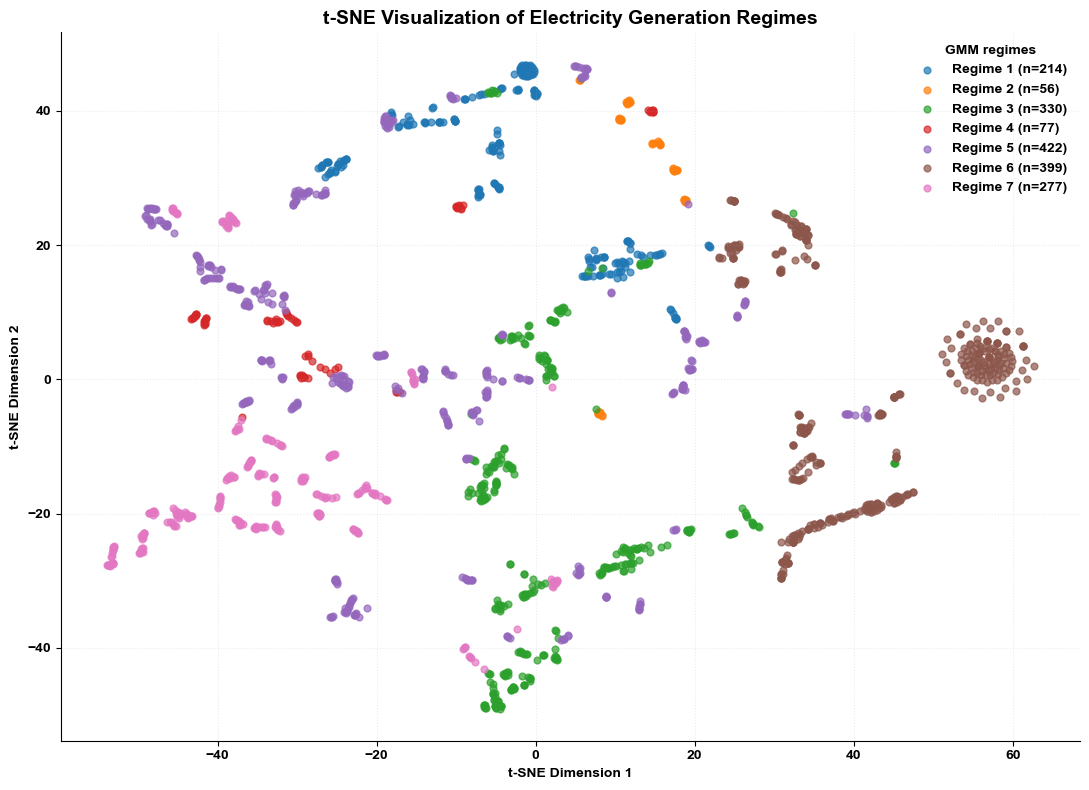


ALL ANALYSES AND EXPORTS COMPLETED.


In [10]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture
from sklearn.manifold import TSNE

# 1. DATA PREPARATION
sources = [
    "Solar", "Wind", "Hydro", "Bioenergy", "Other renewables",
    "Nuclear", "Coal", "Gas", "Other fossil"
]
required = ["Area", "Year", "Carbon_Intensity"] + sources

missing = [c for c in required if c not in df_analysis.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")

d = df_analysis.loc[
    pd.to_numeric(df_analysis["Year"], errors="coerce").between(2016, 2024),
    required
].copy()

d["Year"] = pd.to_numeric(d["Year"], errors="coerce")
d["Area"] = d["Area"].astype(str).str.strip()

numeric_cols = ["Carbon_Intensity"] + sources
d[numeric_cols] = d[numeric_cols].apply(pd.to_numeric, errors="coerce")

if d[required].isna().any().any():
    raise ValueError("Missing or non-numeric values found. Resolve them before analysis.")

if d["Area"].eq("").any():
    raise ValueError("Empty geographical-unit names found.")

# Explicitly exclude aggregate reporting units
aggregates = {
    "World", "European Union", "European Union (27)",
    "EU", "G7", "G20", "OECD"
}
d = d.loc[~d["Area"].isin(aggregates)].copy()

if d.duplicated(["Area", "Year"]).any():
    raise ValueError("Duplicate Area-Year observations found.")

if not np.isfinite(d[numeric_cols].to_numpy(dtype=float)).all():
    raise ValueError("Infinite or non-finite numeric values found.")

if (d[sources].to_numpy(dtype=float) < 0).any():
    raise ValueError("Negative generation shares found.")

if (d["Carbon_Intensity"] < 0).any():
    raise ValueError("Negative carbon intensity values found.")

# 2. COMPOSITIONAL VALIDATION
x = d[sources].to_numpy(dtype=float)
row_sum = x.sum(axis=1)

zero_total = row_sum <= 0
if zero_total.any():
    print("ZERO-TOTAL OBSERVATIONS:")
    print(d.loc[zero_total, ["Area", "Year"]].to_string(index=False))
    raise ValueError(
        "All nine generation shares are zero for some observations. "
        "Investigate these records before proceeding."
    )

share_sum = pd.Series(row_sum, index=d.index)
print("INITIAL SAMPLE:", len(d))
print("GEOGRAPHICAL UNITS:", d["Area"].nunique())
print("YEAR RANGE:", int(d["Year"].min()), "-", int(d["Year"].max()))
print("SHARE SUM MIN:", round(share_sum.min(), 6))
print("SHARE SUM MAX:", round(share_sum.max(), 6))
print("SHARE SUM MEAN:", round(share_sum.mean(), 6))

# Check the expected sample before estimating the model
if len(d) != 1775 or d["Area"].nunique() != 199:
    raise ValueError(
        f"Sample differs from the manuscript: "
        f"{len(d)} observations and {d['Area'].nunique()} geographical units. "
        "Check aggregate exclusions and data construction."
    )

# 3. HELLINGER TRANSFORMATION
P = x / row_sum[:, None]
H = np.sqrt(P)

if not np.allclose((H ** 2).sum(axis=1), 1, atol=1e-10):
    raise ValueError("Hellinger transformation validation failed.")

if H.shape[1] != 9:
    raise ValueError("The analysis must contain all nine generation sources.")

print("\nFINAL SAMPLE:", len(d), "observations")
print("AREAS:", d["Area"].nunique())
print("YEARS:", d["Year"].nunique())
print("HELLINGER DIMENSIONS:", H.shape[1])

# 4. SEVEN-REGIME GMM
gmm = GaussianMixture(
    n_components=7,
    covariance_type="diag",
    n_init=10,
    reg_covar=1e-5,
    max_iter=1000,
    random_state=42
)

d["Regime"] = gmm.fit_predict(H) + 1

print("\nGMM CONVERGED:", gmm.converged_)
print("GMM BIC:", round(gmm.bic(H), 4))
print("GMM AIC:", round(gmm.aic(H), 4))
print("\nREGIME COUNTS:")
print(d["Regime"].value_counts().sort_index())

# 5. REGIME PROFILES
profile = d.groupby("Regime").agg(
    Observations=("Area", "size"),
    Areas=("Area", "nunique"),
    Mean_Carbon_Intensity=("Carbon_Intensity", "mean"),
    Median_Carbon_Intensity=("Carbon_Intensity", "median"),
    SD_Carbon_Intensity=("Carbon_Intensity", "std")
)

source_means = d.groupby("Regime")[sources].mean()
profile = profile.join(source_means.add_prefix("Mean_"))
profile.index.name = "Regime"

print("\nREGIME PROFILES:")
print(profile.round(3).to_string())

# 6. ANNUAL REGIME DISTRIBUTION
annual_counts = pd.crosstab(d["Year"], d["Regime"])
annual_counts = annual_counts.reindex(columns=range(1, 8), fill_value=0)

annual_shares = annual_counts.div(
    annual_counts.sum(axis=1), axis=0
) * 100

print("\nANNUAL REGIME DISTRIBUTION (%):")
print(annual_shares.round(2).to_string())

# 7. COUNTRY-LEVEL REGIME DISTRIBUTION
country_counts = pd.crosstab(d["Area"], d["Regime"])
country_counts = country_counts.reindex(columns=range(1, 8), fill_value=0)
country_counts.columns = [f"Regime_{k}_Count" for k in range(1, 8)]

regime_cols = list(country_counts.columns)
country_distribution = country_counts.copy()

country_distribution["Years_Observed"] = (
    d.groupby("Area")["Year"].nunique()
)

country_distribution["Regime_Count"] = (
    (country_counts > 0).sum(axis=1)
)

country_distribution["Dominant_Count"] = country_counts.max(axis=1)

country_distribution["Dominant_Regime"] = country_counts.apply(
    lambda r: ", ".join(
        str(i + 1) for i, value in enumerate(r)
        if value == r.max()
    ),
    axis=1
)

country_distribution["Dominant_Regime_Share"] = (
    country_distribution["Dominant_Count"] /
    country_distribution["Years_Observed"] * 100
)

print("\nCOUNTRY-LEVEL REGIME DISTRIBUTION:")
print(country_distribution.round(2).to_string())

# 8. t-SNE VISUALIZATION
perplexity = min(30, max(5, (len(d) - 1) // 3))

tsne = TSNE(
    n_components=2,
    perplexity=perplexity,
    init="pca",
    learning_rate="auto",
    max_iter=1500,
    random_state=42
)

coordinates = tsne.fit_transform(H)
d["TSNE1"] = coordinates[:, 0]
d["TSNE2"] = coordinates[:, 1]

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 10,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelweight": "bold",
    "figure.facecolor": "white",
    "axes.facecolor": "white"
})

fig, ax = plt.subplots(figsize=(11, 8))

for k in range(1, 8):
    q = d.loc[d["Regime"] == k]
    ax.scatter(
        q["TSNE1"], q["TSNE2"],
        s=24, alpha=0.70,
        label=f"Regime {k} (n={len(q)})"
    )

ax.set_title("t-SNE Visualization of Electricity Generation Regimes")
ax.set_xlabel("t-SNE Dimension 1")
ax.set_ylabel("t-SNE Dimension 2")
ax.legend(title="GMM regimes", frameon=False)
ax.grid(linestyle=":", alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(
    "Figure_4_tSNE_Nine_Source_Regimes.png",
    dpi=900,
    bbox_inches="tight",
    facecolor="white"
)
plt.show()

# 9. EXPORT RESULTS
d.to_csv(
    "Nine_Source_GMM_Country_Year_Regimes.csv",
    index=False, encoding="utf-8-sig"
)

profile.to_csv(
    "Nine_Source_GMM_Regime_Profiles.csv",
    encoding="utf-8-sig"
)

annual_shares.to_csv(
    "Nine_Source_GMM_Annual_Regime_Shares.csv",
    encoding="utf-8-sig"
)

country_distribution.to_csv(
    "Nine_Source_GMM_Country_Regime_Distribution.csv",
    encoding="utf-8-sig"
)

print("\nALL ANALYSES AND EXPORTS COMPLETED.")


In [11]:

import numpy as np
import pandas as pd

sources = ["Solar","Wind","Hydro","Bioenergy","Other renewables","Nuclear","Coal","Gas","Other fossil"]

d = df_analysis.loc[
    pd.to_numeric(df_analysis["Year"],errors="coerce").between(2016,2024),
    ["Area","Year","Carbon_Intensity"]+sources
].copy()

d["Year"] = pd.to_numeric(d["Year"],errors="coerce")
d[["Carbon_Intensity"]+sources] = d[["Carbon_Intensity"]+sources].apply(pd.to_numeric,errors="coerce")
d["Area"] = d["Area"].astype(str).str.strip()
d = d.dropna(subset=["Area","Year"]+sources).copy()
d = d[d["Area"].ne("")].copy()

if (d[sources]<0).any().any():
    raise ValueError("Negatif enerji üretim payı bulundu.")

X = d[sources].copy()
P = X.gt(0)
n_positive = P.sum(axis=1)

d["Positive_Count"] = n_positive
d["Dominant_Source"] = X.idxmax(axis=1)
d["Dominant_Share"] = X.max(axis=1)

# SINGLE-SOURCE OBSERVATIONS
single_data = d.loc[n_positive==1].copy()
single = single_data.groupby("Dominant_Source").agg(
    Observations=("Area","size"),
    Areas=("Area","nunique"),
    Mean_Carbon_Intensity=("Carbon_Intensity","mean"),
    Median_Carbon_Intensity=("Carbon_Intensity","median")
).sort_values("Observations",ascending=False)

# POSITIVE SHARE DISTRIBUTION
positive_stats = pd.DataFrame({
    "Positive_N":P.sum(),
    "Zero_N":X.eq(0).sum(),
    "Zero_Percent":X.eq(0).mean()*100,
    "Min_Positive":X.where(P).min(),
    "P01":X.where(P).quantile(.01),
    "P05":X.where(P).quantile(.05),
    "Median_Positive":X.where(P).median(),
    "P95":X.where(P).quantile(.95),
    "Max_Positive":X.where(P).max()
}).round(5)

# COMPOSITIONAL DIVERSITY
diversity = d.groupby("Positive_Count").agg(
    Observations=("Area","size"),
    Areas=("Area","nunique"),
    Mean_Dominant_Share=("Dominant_Share","mean"),
    Median_Dominant_Share=("Dominant_Share","median"),
    Mean_Carbon_Intensity=("Carbon_Intensity","mean")
).round(3)

# SINGLE-SOURCE OBSERVATIONS BY YEAR
single_year = pd.crosstab(single_data["Year"],single_data["Dominant_Source"])

# AREAS WITH SINGLE-SOURCE OBSERVATIONS
single_areas = single_data.groupby("Area").agg(
    Single_Source_Years=("Year","nunique"),
    Dominant_Source=("Dominant_Source",lambda x:x.mode().iloc[0]),
    First_Year=("Year","min"),
    Last_Year=("Year","max")
).sort_values("Single_Source_Years",ascending=False)

print("\nSAMPLE:",len(d),"observations |",d["Area"].nunique(),"Areas |",d["Year"].nunique(),"years")
print("\nSINGLE-SOURCE OBSERVATIONS\n",single.to_string())
print("\nPOSITIVE SHARE DISTRIBUTION\n",positive_stats.to_string())
print("\nCOMPOSITIONAL DIVERSITY\n",diversity.to_string())
print("\nSINGLE-SOURCE OBSERVATIONS BY YEAR\n",single_year.to_string())
print("\nAREAS WITH SINGLE-SOURCE OBSERVATIONS\n",single_areas.head(30).to_string())

single.to_csv("Single_Source_Profiles.csv",encoding="utf-8-sig")
positive_stats.to_csv("Positive_Share_Distribution.csv",encoding="utf-8-sig")
diversity.to_csv("Composition_Diversity.csv",encoding="utf-8-sig")
single_year.to_csv("Single_Source_By_Year.csv",encoding="utf-8-sig")
single_areas.to_csv("Single_Source_By_Area.csv",encoding="utf-8-sig")



SAMPLE: 1775 observations | 199 Areas | 9 years

SINGLE-SOURCE OBSERVATIONS
                  Observations  Areas  Mean_Carbon_Intensity  Median_Carbon_Intensity
Dominant_Source                                                                     
Other fossil              125     26             663.707096                  658.824
Hydro                      27      4              24.036037                   23.752
Gas                         5      1            1306.547800                 1306.546

POSITIVE SHARE DISTRIBUTION
                   Positive_N  Zero_N  Zero_Percent  Min_Positive      P01      P05  Median_Positive        P95  Max_Positive
Solar                   1378     397      22.36620         0.002  0.01200  0.05785           1.9255   14.66115        50.000
Wind                     908     867      48.84507         0.002  0.01300  0.05200           3.6930   27.87020        58.378
Hydro                   1314     461      25.97183         0.012  0.03578  0.29200          

C:\Users\sadul\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=7.
  warnings.warn(
C:\Users\sadul\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=7.
  warnings.warn(
C:\Users\sadul\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=7.
  warnings.warn(
C:\Users\sadul\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window


GMM STABILITY RESULTS

 K Covariance         BIC         AIC  Silhouette  Min_N   Min_%  Mean_ARI  Converged
 8       diag -49341.4837 -50169.1986      0.1520     56  3.1549    0.7122       True
 7       full -48717.0581 -50821.9755      0.1172     45  2.5352    0.6599       True
 6       full -47620.0313 -49423.4631      0.1421     54  3.0423    0.6502       True
 7       diag -47336.5004 -48060.0657      0.1805     56  3.1549    0.9050       True
 8       full -46920.8791 -49327.2821      0.1377     49  2.7606    0.5540       True
 6       diag -45180.8841 -45800.2999      0.1616     58  3.2676    0.7376       True
 5       diag -44780.5914 -45295.8576      0.1677    133  7.4930    0.9663       True
 5       full -43593.3437 -45095.2900      0.1623    162  9.1268    0.7215       True
 4       diag -41012.3307 -41423.4474      0.1607    265 14.9296    1.0000       True
 3       full -38646.7863 -39545.7614      0.1197    379 21.3521    0.4764       True
 4       full -36140.9057 -373

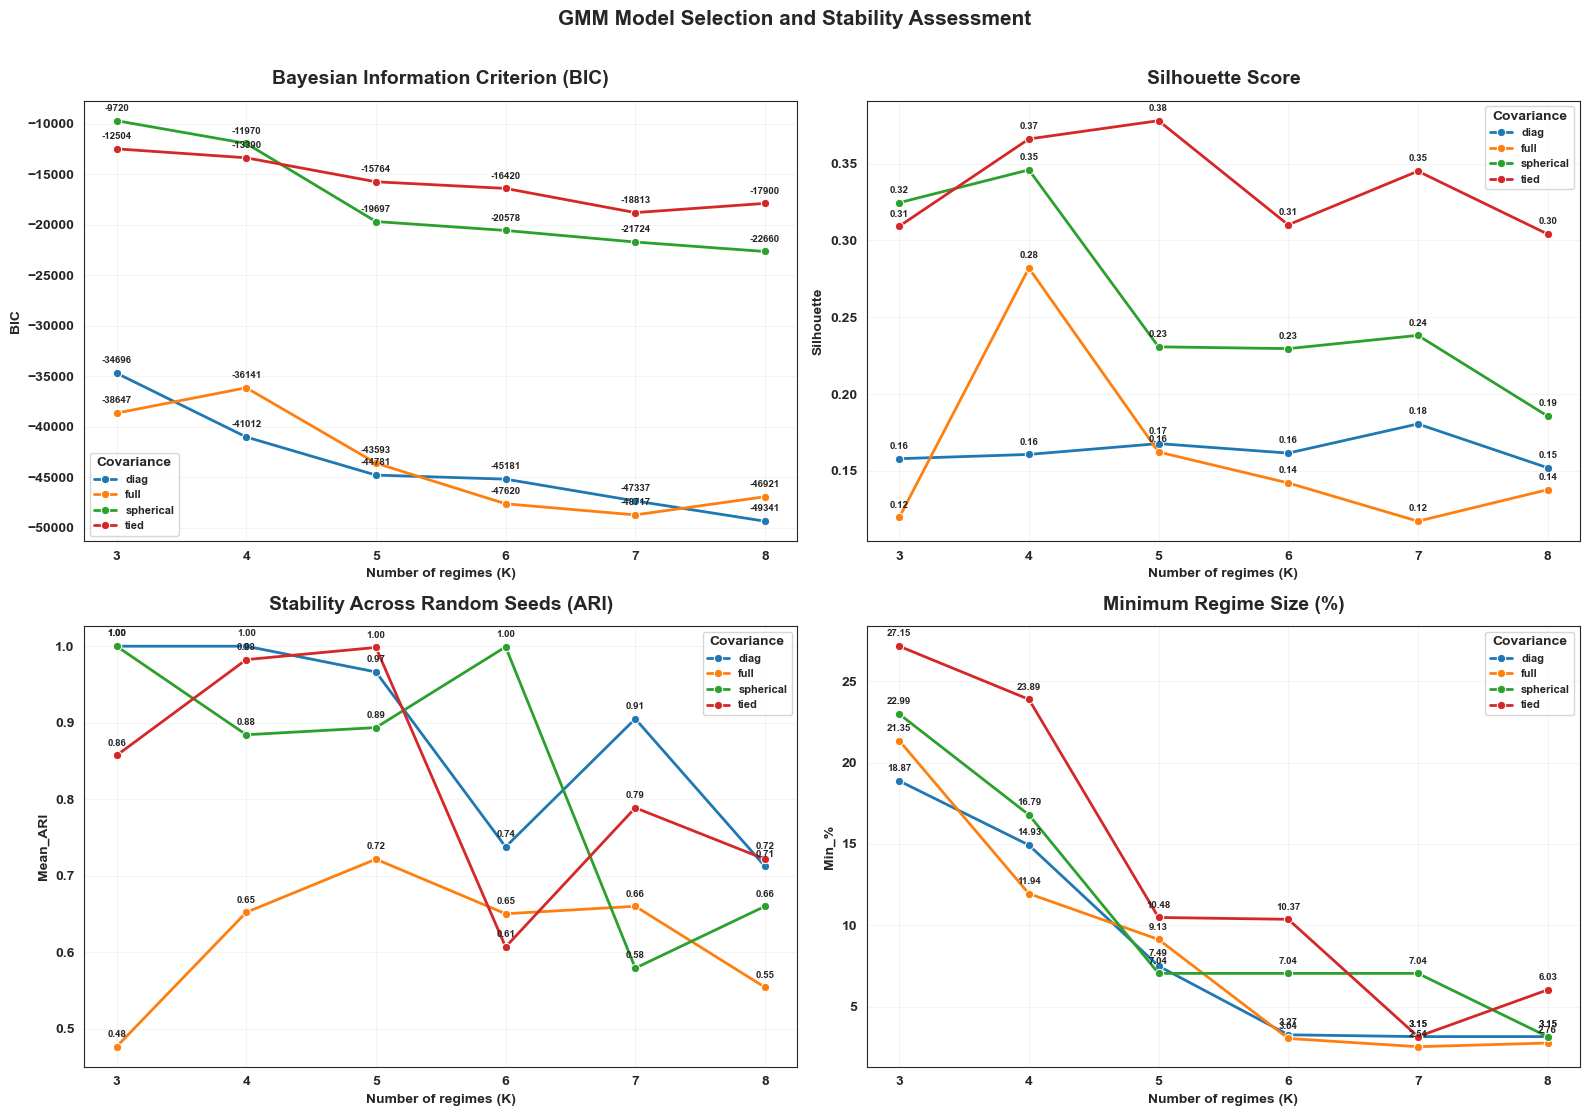


BEST BIC MODEL

K                        8
Covariance            diag
BIC          -49341.483668
AIC          -50169.198579
Silhouette        0.152021
Min_N                   56
Min_%              3.15493
Mean_ARI          0.712152
Converged             True

Dosyalar kaydedildi:
GMM_Regime_Stability.xlsx
Figure_GMM_Stability_Comparison.png
Figure_GMM_Stability_Comparison.svg


In [24]:

import numpy as np,pandas as pd,matplotlib.pyplot as plt,seaborn as sns
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score,silhouette_score

# Hellinger dönüşümlü veri
X_hellinger=np.asarray(X)
assert X_hellinger.ndim==2 and X_hellinger.shape[1]==9
assert np.isfinite(X_hellinger).all()

results=[]
seeds=[21,42,63,84,105]

for cov in ["full","tied","diag","spherical"]:
    for k in range(3,9):
        fitted=[]
        for seed in seeds:
            gm=GaussianMixture(n_components=k,covariance_type=cov,n_init=10,
                               reg_covar=1e-5,max_iter=1000,random_state=seed)
            labels=gm.fit_predict(X_hellinger)
            fitted.append((gm,labels))

        gm,labels=fitted[1]
        ari=[adjusted_rand_score(labels,m[1]) for i,m in enumerate(fitted) if i!=1]
        counts=np.bincount(labels,minlength=k)

        results.append({
            "K":k,
            "Covariance":cov,
            "BIC":gm.bic(X_hellinger),
            "AIC":gm.aic(X_hellinger),
            "Silhouette":silhouette_score(X_hellinger,labels),
            "Min_N":counts.min(),
            "Min_%":counts.min()/len(labels)*100,
            "Mean_ARI":np.mean(ari),
            "Converged":gm.converged_
        })

stability=pd.DataFrame(results).sort_values("BIC").reset_index(drop=True)
stability.to_excel("GMM_Regime_Stability.xlsx",index=False)

print("\nGMM STABILITY RESULTS\n")
print(stability.round(4).to_string(index=False))

# Grafikler
plt.rcParams.update({
    "font.family":"Arial","font.size":10,
    "font.weight":"bold","axes.titleweight":"bold"
})

metrics=["BIC","Silhouette","Mean_ARI","Min_%"]
titles=[
    "Bayesian Information Criterion (BIC)",
    "Silhouette Score",
    "Stability Across Random Seeds (ARI)",
    "Minimum Regime Size (%)"
]

fig,axes=plt.subplots(2,2,figsize=(16,11),facecolor="white")

for ax,metric,title in zip(axes.flat,metrics,titles):
    sns.lineplot(data=stability,x="K",y=metric,hue="Covariance",
                 marker="o",linewidth=2,ax=ax)
    for _,r in stability.iterrows():
        ax.annotate(f"{r[metric]:.2f}" if metric!="BIC" else f"{r[metric]:.0f}",
                    (r["K"],r[metric]),xytext=(0,7),
                    textcoords="offset points",ha="center",fontsize=7)
    ax.set_title(title,pad=12)
    ax.set_xlabel("Number of regimes (K)")
    ax.set_ylabel(metric)
    ax.set_xticks(range(3,9))
    ax.grid(alpha=.2)
    ax.legend(title="Covariance",fontsize=8)

fig.suptitle("GMM Model Selection and Stability Assessment",
             fontsize=15,fontweight="bold",y=1.01)
fig.tight_layout()
fig.savefig("Figure_GMM_Stability_Comparison.png",dpi=900,
            bbox_inches="tight",facecolor="white")
fig.savefig("Figure_GMM_Stability_Comparison.svg",
            bbox_inches="tight",facecolor="white")
plt.show()

best=stability.loc[stability["BIC"].idxmin()]
print("\nBEST BIC MODEL\n")
print(best.to_string())

print("\nDosyalar kaydedildi:")
print("GMM_Regime_Stability.xlsx")
print("Figure_GMM_Stability_Comparison.png")
print("Figure_GMM_Stability_Comparison.svg")


# K 7 için burda bulunud asagıdakı kısmı dıkkate al bundan sonra 

Analiz örneklemi: 1775
Reporting units: 199
Dönem: 2016 - 2024


C:\Users\sadul\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=7.
  warnings.warn(
C:\Users\sadul\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=7.
  warnings.warn(
C:\Users\sadul\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=7.
  warnings.warn(
C:\Users\sadul\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

K=7: başarılı bootstrap=500/500


C:\Users\sadul\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=7.
  warnings.warn(
C:\Users\sadul\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=7.
  warnings.warn(
C:\Users\sadul\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=7.
  warnings.warn(
C:\Users\sadul\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

K=8: başarılı bootstrap=500/500

REGIME-LEVEL BOOTSTRAP STABILITY

 K  Regime  Bootstrap_N  Jaccard_Mean  Jaccard_Median  Jaccard_SD  Jaccard_P05  Jaccard_P95  Composition_MAE  Composition_RMSE  Mean_Size
 7       1          500        0.4112          0.3783      0.2922       0.0000       0.9694           6.4910           10.9459    12.4921
 7       2          500        0.2857          0.2751      0.2537       0.0000       0.7397           9.2008           13.6633     6.5040
 7       3          500        0.5656          0.5645      0.2122       0.1434       0.9038           4.7888            8.4878    19.9007
 7       4          500        0.3803          0.3740      0.2730       0.0000       0.8659           6.5368            9.8197     7.3960
 7       5          500        0.4969          0.5038      0.2005       0.1673       0.8197           4.6562            6.9911    19.7239
 7       6          500        0.8435          0.8775      0.1419       0.6036       1.0000           0.9

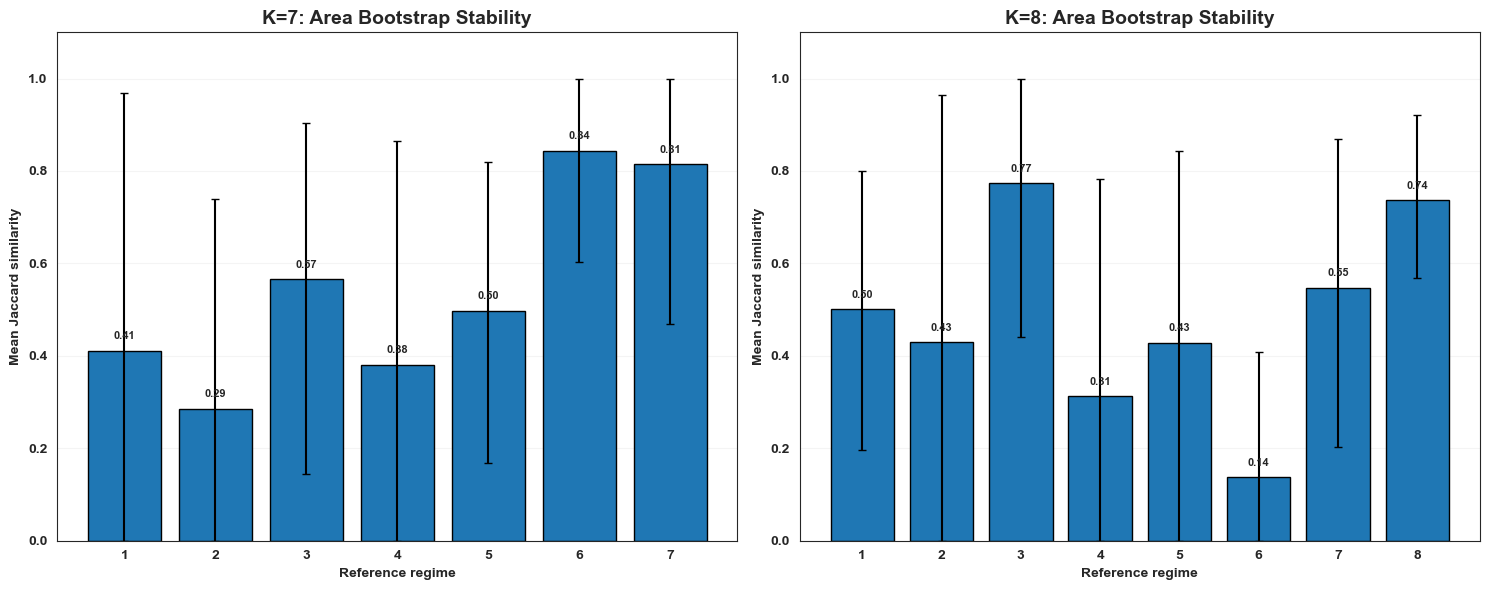

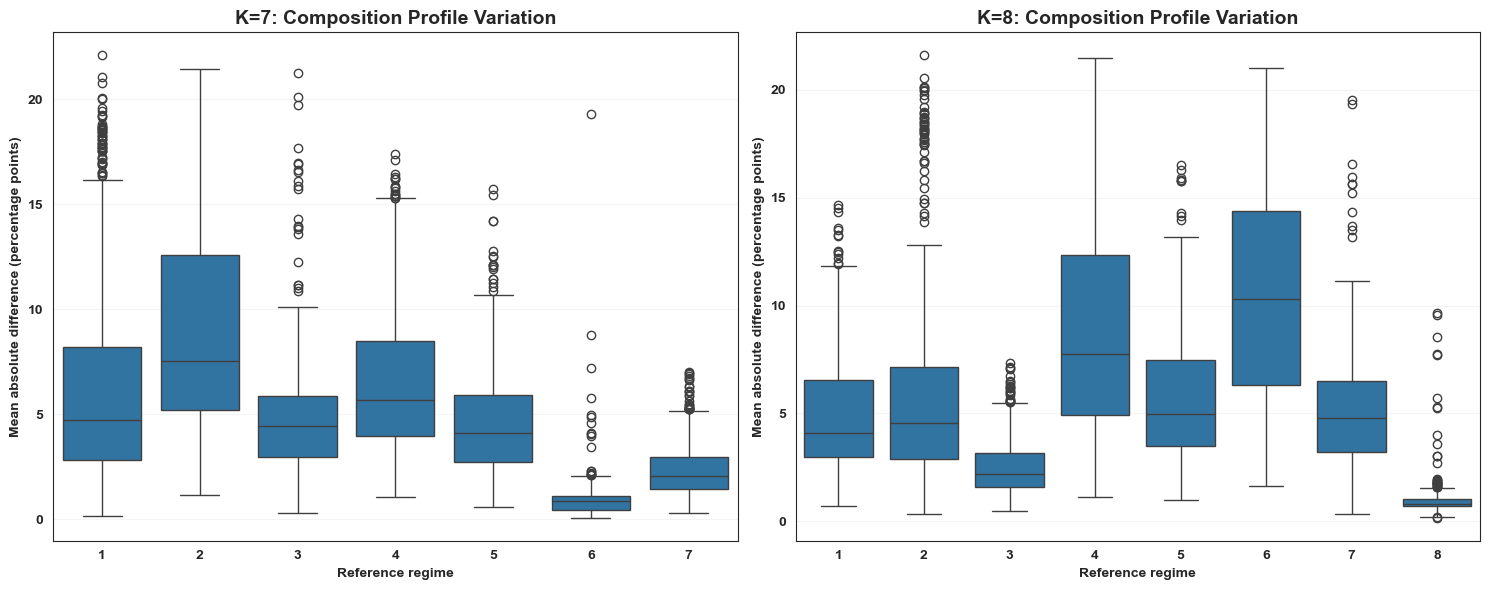


ANALİZ TAMAMLANDI.
Başarılı bootstrap sayıları: {7: 500, 8: 500}
Excel: K7_K8_Corrected_Area_Bootstrap.xlsx


In [27]:

import numpy as np,pandas as pd,matplotlib.pyplot as plt,seaborn as sns
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score
from scipy.optimize import linear_sum_assignment

parts=["Solar","Wind","Hydro","Bioenergy","Other renewables","Nuclear","Coal","Gas","Other fossil"]
B=500
rng=np.random.default_rng(42)

# 1. VERİLERİ 2016-2024 DÖNEMİNE GÖRE EŞLEŞTİR
base0=df_analysis.reset_index(drop=True).copy()
base0["Year"]=pd.to_numeric(base0["Year"],errors="coerce")
X0=np.asarray(X_hellinger,dtype=float)

if len(X0)==len(base0):
    mask=base0["Year"].between(2016,2024).to_numpy()
    base=base0.loc[mask].reset_index(drop=True)
    X=X0[mask]
elif len(X0)==1775:
    base=base0.loc[base0["Year"].between(2016,2024)].reset_index(drop=True)
    if len(base)!=len(X0): raise ValueError("Filtrelenmiş veri ile X_hellinger sırası veya gözlem sayısı uyuşmuyor.")
    X=X0
else:
    raise ValueError(f"Veri boyutları uyuşmuyor: df_analysis={len(base0)}, X_hellinger={len(X0)}. X matrisinin hangi örnekleme ait olduğunu kontrol et.")

valid=base["Area"].notna().to_numpy()&np.isfinite(X).all(axis=1)
base=base.loc[valid].reset_index(drop=True)
X=X[valid]

assert len(base)==len(X)
assert base["Year"].min()==2016 and base["Year"].max()==2024
assert base["Area"].nunique()==199
assert X.shape[1]==9
assert np.isfinite(X).all()

print("Analiz örneklemi:",len(base))
print("Reporting units:",base["Area"].nunique())
print("Dönem:",base["Year"].min(),"-",base["Year"].max())

# 2. AREA-BASED BOOTSTRAP ÖRNEKLERİ
areas=base["Area"].unique()
area_values=base["Area"].to_numpy()
area_indices={a:np.flatnonzero(area_values==a) for a in areas}
bootstrap_samples=[rng.choice(areas,size=len(areas),replace=True) for _ in range(B)]
all_results=[]
success_counts={}

# 3. K=7 VE K=8 MODELLERİ
for k in [7,8]:
    ref_model=GaussianMixture(n_components=k,covariance_type="diag",n_init=10,reg_covar=1e-5,max_iter=1000,random_state=42).fit(X)
    ref=ref_model.predict(X)
    ref_profiles=np.array([base.loc[ref==r,parts].mean().to_numpy() for r in range(k)])
    results=[]
    successful=0

    for b,sampled in enumerate(bootstrap_samples):
        idx=np.concatenate([area_indices[a] for a in sampled])
        xb=X[idx]
        refb=ref[idx]
        gm=GaussianMixture(n_components=k,covariance_type="diag",n_init=5,reg_covar=1e-5,max_iter=1000,random_state=1000+b)
        gm.fit(xb)
        if not gm.converged_: continue

        lab=gm.predict(xb)
        overlap=np.zeros((k,k),dtype=int)
        for i in range(k):
            for j in range(k):
                overlap[i,j]=np.sum((refb==i)&(lab==j))

        rows,cols=linear_sum_assignment(-overlap)
        successful+=1
        ari=adjusted_rand_score(refb,lab)

        for i,j in zip(rows,cols):
            ref_mask=refb==i
            boot_mask=lab==j
            inter=overlap[i,j]
            union=ref_mask.sum()+boot_mask.sum()-inter
            jac=inter/union if union else 0
            comp=xb[boot_mask]**2
            row_sums=comp.sum(axis=1,keepdims=True)
            comp=np.divide(comp,row_sums,out=np.zeros_like(comp),where=row_sums>0)
            boot_profile=100*comp.mean(axis=0)
            results.append({"K":k,"Bootstrap":b+1,"Regime":i+1,"Jaccard":jac,"ARI_Global":ari,"N_Reference":int(ref_mask.sum()),"N_Bootstrap":int(boot_mask.sum()),"Share_Boot_%":boot_mask.mean()*100,"Composition_MAE":np.mean(np.abs(boot_profile-ref_profiles[i])),"Composition_RMSE":np.sqrt(np.mean((boot_profile-ref_profiles[i])**2))})

    all_results.extend(results)
    success_counts[k]=successful
    print(f"K={k}: başarılı bootstrap={successful}/{B}")

# 4. ÖZET TABLOLAR
res=pd.DataFrame(all_results)
if res.empty: raise ValueError("Hiçbir bootstrap modeli başarıyla tamamlanmadı.")

summary=res.groupby(["K","Regime"]).agg(Bootstrap_N=("Bootstrap","count"),Jaccard_Mean=("Jaccard","mean"),Jaccard_Median=("Jaccard","median"),Jaccard_SD=("Jaccard","std"),Jaccard_P05=("Jaccard",lambda x:x.quantile(.05)),Jaccard_P95=("Jaccard",lambda x:x.quantile(.95)),Composition_MAE=("Composition_MAE","mean"),Composition_RMSE=("Composition_RMSE","mean"),Mean_Size=("Share_Boot_%","mean")).reset_index()

global_ari=res.groupby(["K","Bootstrap"])["ARI_Global"].first().reset_index()
ari_summary=global_ari.groupby("K")["ARI_Global"].agg(Mean="mean",Median="median",SD="std").reset_index()
quantiles=global_ari.groupby("K")["ARI_Global"].quantile([.05,.95]).unstack()
ari_summary["P05"]=ari_summary["K"].map(quantiles[.05])
ari_summary["P95"]=ari_summary["K"].map(quantiles[.95])

print("\nREGIME-LEVEL BOOTSTRAP STABILITY\n")
print(summary.round(4).to_string(index=False))
print("\nGLOBAL ARI SUMMARY\n")
print(ari_summary.round(4).to_string(index=False))

# 5. EXCEL
with pd.ExcelWriter("K7_K8_Corrected_Area_Bootstrap.xlsx") as w:
    summary.to_excel(w,sheet_name="Regime_Stability",index=False)
    ari_summary.to_excel(w,sheet_name="Global_ARI",index=False)
    res.to_excel(w,sheet_name="Bootstrap_Details",index=False)

# 6. JACCARD GRAFİĞİ
plt.rcParams.update({"font.family":"Arial","font.size":10,"font.weight":"bold","axes.titleweight":"bold"})
fig,axes=plt.subplots(1,2,figsize=(15,6),facecolor="white")

for ax,k in zip(axes,[7,8]):
    s=summary[summary["K"]==k].sort_values("Regime")
    xloc=np.arange(len(s))
    bars=ax.bar(xloc,s["Jaccard_Mean"],edgecolor="black")
    lower=s["Jaccard_Mean"]-s["Jaccard_P05"]
    upper=s["Jaccard_P95"]-s["Jaccard_Mean"]
    ax.errorbar(xloc,s["Jaccard_Mean"],yerr=[lower,upper],fmt="none",ecolor="black",capsize=3)
    for bar,v in zip(bars,s["Jaccard_Mean"]):
        ax.text(bar.get_x()+bar.get_width()/2,v+.025,f"{v:.2f}",ha="center",fontsize=8,fontweight="bold")
    ax.set_title(f"K={k}: Area Bootstrap Stability")
    ax.set_xlabel("Reference regime")
    ax.set_ylabel("Mean Jaccard similarity")
    ax.set_xticks(xloc,s["Regime"].astype(str))
    ax.set_ylim(0,1.1)
    ax.grid(axis="y",alpha=.2)

fig.tight_layout()
fig.savefig("Figure_K7_K8_Bootstrap_Jaccard.png",dpi=900,bbox_inches="tight",facecolor="white")
fig.savefig("Figure_K7_K8_Bootstrap_Jaccard.svg",bbox_inches="tight",facecolor="white")
plt.show()

# 7. KOMPOZİSYON PROFİLİ DAYANIKLILIK GRAFİĞİ
fig,axes=plt.subplots(1,2,figsize=(15,6),facecolor="white")

for ax,k in zip(axes,[7,8]):
    s=res[res["K"]==k]
    sns.boxplot(data=s,x="Regime",y="Composition_MAE",ax=ax)
    ax.set_title(f"K={k}: Composition Profile Variation")
    ax.set_xlabel("Reference regime")
    ax.set_ylabel("Mean absolute difference (percentage points)")
    ax.grid(axis="y",alpha=.2)

fig.tight_layout()
fig.savefig("Figure_K7_K8_Composition_Robustness.png",dpi=900,bbox_inches="tight",facecolor="white")
plt.show()

print("\nANALİZ TAMAMLANDI.")
print("Başarılı bootstrap sayıları:",success_counts)
print("Excel: K7_K8_Corrected_Area_Bootstrap.xlsx")


Sample: 1775 Areas: 199 Years: 9
Original share-sum: 99.982 - 100.01400000000001


C:\Users\sadul\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=7.
  warnings.warn(
C:\Users\sadul\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=7.
  warnings.warn(
C:\Users\sadul\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=7.
  warnings.warn(
C:\Users\sadul\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

K=7 | BIC: -47336.5 AIC: -48060.066 | Converged: True


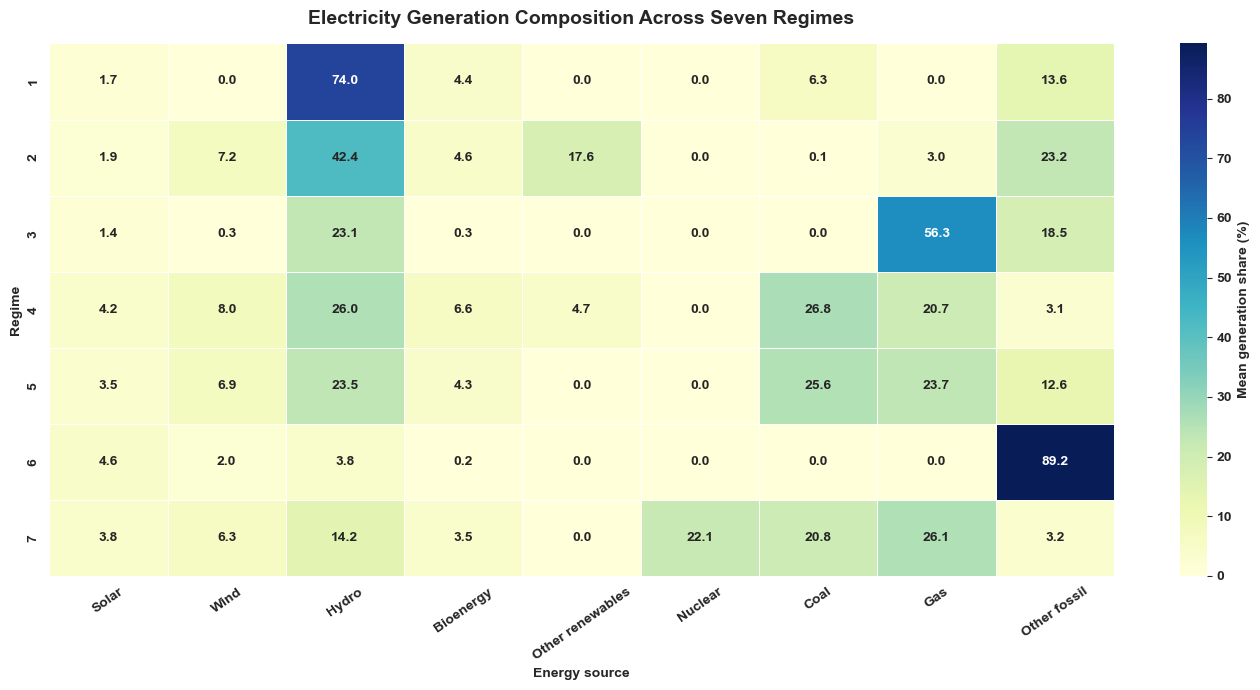

C:\Users\sadul\AppData\Local\Temp\ipykernel_20600\88612043.py:191: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  ax.grid(axis="y",alpha=.2); fig.tight_layout()
C:\Users\sadul\AppData\Local\Temp\ipykernel_20600\88612043.py:192: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.savefig("Figure_K7_Carbon_2016_2024.png",dpi=900,bbox_inches="tight",facecolor="white")
C:\Users\sadul\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


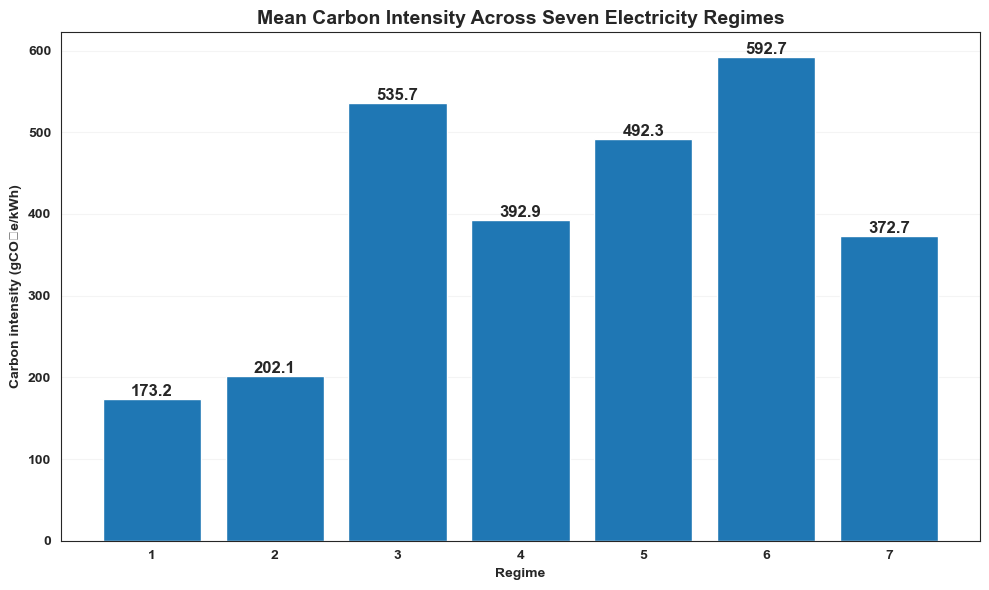

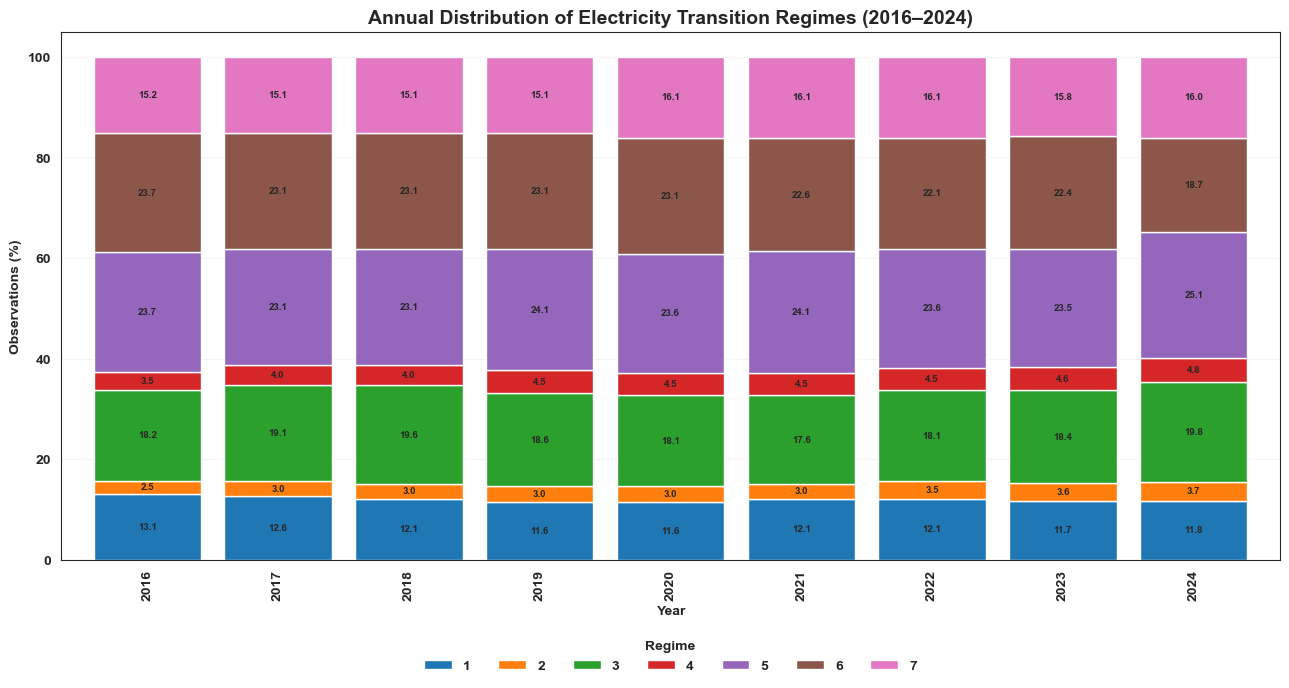

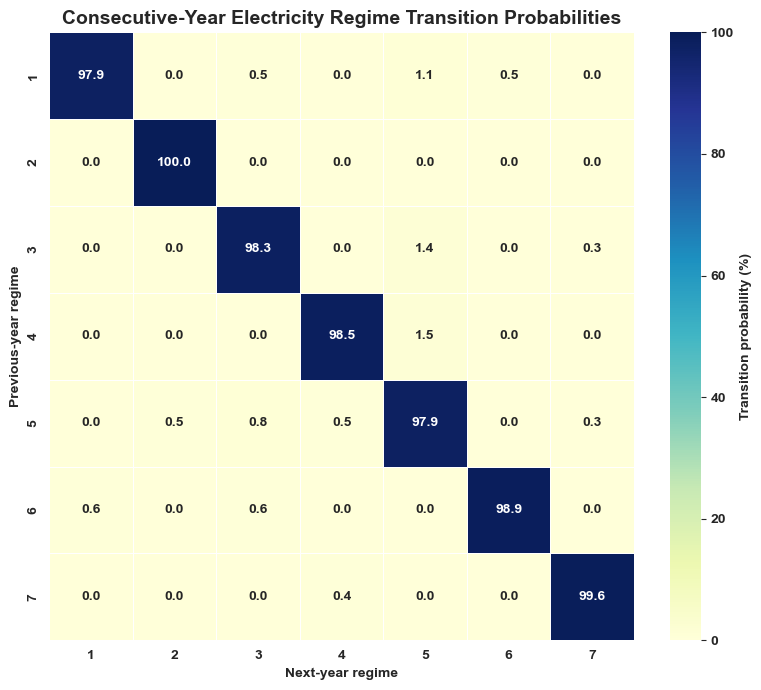


REGIME PROFILES
    Regime    N  Areas  Share_%  Carbon_Mean  Carbon_Median  Carbon_SD  Carbon_Q25  Carbon_Q75   Solar    Wind    Hydro  Bioenergy  Other renewables  Nuclear     Coal      Gas  Other fossil
0       1  214     28  12.0563     173.1647       138.5545   139.2053     47.9100    277.4298  1.7333  0.0000  74.0136     4.3636            0.0000   0.0000   6.2920   0.0000       13.5975
1       2   56      7   3.1549     202.1133       114.3640   178.9171     28.0320    328.0575  1.9281  7.1940  42.4417     4.6108           17.5895   0.0000   0.0550   3.0201       23.1608
2       3  330     42  18.5915     535.6750       582.0870   240.9229    401.1660    656.3052  1.4271  0.2669  23.1170     0.3318            0.0000   0.0000   0.0000  56.3427       18.5147
3       4   77     10   4.3380     392.9284       366.8600   182.8344    248.1610    535.1340  4.1585  7.9614  26.0268     6.5508            4.6784   0.0000  26.7626  20.7392        3.1224
4       5  422     53  23.7746     49

In [28]:
import os
os.environ["OMP_NUM_THREADS"]="7"

import numpy as np,pandas as pd,matplotlib.pyplot as plt,seaborn as sns
import statsmodels.formula.api as smf
from sklearn.mixture import GaussianMixture

# 1. DATA AND HELLINGER TRANSFORMATION
parts=["Solar","Wind","Hydro","Bioenergy","Other renewables","Nuclear","Coal","Gas","Other fossil"]
d=df_analysis.copy()
d["Year"]=pd.to_numeric(d["Year"],errors="coerce")
d=d[d["Year"].between(2016,2024)].copy()
for c in parts+["Carbon_Intensity"]:
    d[c]=pd.to_numeric(d[c],errors="coerce")
d=d.dropna(subset=["Area","Year"]+parts).reset_index(drop=True)

shares=d[parts].to_numpy(dtype=float)
if not np.isfinite(shares).all() or (shares<0).any():
    raise ValueError("Üretim paylarında negatif veya eksik değer var.")
row_sums=shares.sum(axis=1,keepdims=True)
if (row_sums<=0).any():
    raise ValueError("Sıfır toplamlı kompozisyon bulundu.")

P=shares/row_sums
X=np.sqrt(P)

assert X.shape==(len(d),9)
assert np.allclose((X**2).sum(axis=1),1,atol=1e-10)
assert len(d)==1775 and d["Area"].nunique()==199
assert d["Year"].nunique()==9 and d["Year"].min()==2016 and d["Year"].max()==2024

d["Log_CI"]=np.log1p(d["Carbon_Intensity"])
print("Sample:",len(d),"Areas:",d["Area"].nunique(),"Years:",d["Year"].nunique())
print("Original share-sum:",row_sums.min(),"-",row_sums.max())

# 2. FINAL K=7 GMM
gm7=GaussianMixture(n_components=7,covariance_type="diag",n_init=10,
                    reg_covar=1e-5,max_iter=1000,random_state=42)
d["Regime"]=gm7.fit_predict(X)+1
d["Regime"]=d["Regime"].astype(int)
if d["Regime"].nunique()!=7:
    raise ValueError("GMM yedi rejimin tamamını oluşturmadı.")
print("K=7 | BIC:",round(gm7.bic(X),3),"AIC:",round(gm7.aic(X),3),
      "| Converged:",gm7.converged_)

# 3. REGIME PROFILES
profile=[]
for r,g in d.groupby("Regime"):
    row={"Regime":r,"N":len(g),"Areas":g["Area"].nunique(),
         "Share_%":len(g)/len(d)*100,
         "Carbon_Mean":g["Carbon_Intensity"].mean(),
         "Carbon_Median":g["Carbon_Intensity"].median(),
         "Carbon_SD":g["Carbon_Intensity"].std(),
         "Carbon_Q25":g["Carbon_Intensity"].quantile(.25),
         "Carbon_Q75":g["Carbon_Intensity"].quantile(.75)}
    row.update(g[parts].mean().to_dict())
    profile.append(row)
profiles=pd.DataFrame(profile).sort_values("Regime")

# 4. CARBON INTENSITY MODELS
dc=d.dropna(subset=["Area","Year","Regime","Carbon_Intensity","Log_CI"]).copy()
dc["Area"]=dc["Area"].astype(str)
dc["Year"]=dc["Year"].astype(int)

m_year=smf.ols("Log_CI ~ C(Year)",data=dc).fit()
m_regime=smf.ols("Log_CI ~ C(Regime)+C(Year)",data=dc).fit(
    cov_type="cluster",cov_kwds={"groups":dc["Area"]})
m_area=smf.ols("Log_CI ~ C(Area)+C(Year)",data=dc).fit(
    cov_type="cluster",cov_kwds={"groups":dc["Area"]})
m_full=smf.ols("Log_CI ~ C(Area)+C(Year)+C(Regime)",data=dc).fit(
    cov_type="cluster",cov_kwds={"groups":dc["Area"]})

def joint_test(m):
    names=list(m.params.index)
    ix=[i for i,n in enumerate(names) if n.startswith("C(Regime)")]
    if not ix:
        raise ValueError("Modelde rejim katsayısı bulunamadı.")
    return m.wald_test(np.eye(len(names))[ix],scalar=True)

def model_row(name,m):
    return {"Model":name,"N":int(m.nobs),"R2":m.rsquared,"Adj_R2":m.rsquared_adj}

model_table=pd.DataFrame([
    model_row("Year FE",m_year),
    model_row("Regime + Year FE",m_regime),
    model_row("Area + Year FE",m_area),
    model_row("Area + Year + Regime FE",m_full)
])

wt_full,wt_regime=joint_test(m_full),joint_test(m_regime)
partial_r2=(m_full.rsquared-m_area.rsquared)/(1-m_area.rsquared)

def regime_coefs(m):
    z=pd.DataFrame({"Coefficient":m.params,"SE_Clustered":m.bse,
                    "P_Value":m.pvalues,"CI_Lower":m.conf_int()[0],
                    "CI_Upper":m.conf_int()[1]})
    z=z.loc[z.index.str.startswith("C(Regime)")].copy()
    z["Percent_Difference"]=(np.exp(z["Coefficient"])-1)*100
    return z

coef=regime_coefs(m_full)
carbon_tests=pd.DataFrame([
    {"Model":"Regime + Year FE","Wald_Chi2":float(np.asarray(wt_regime.statistic).squeeze()),
     "P_Value":float(wt_regime.pvalue),"Partial_R2":np.nan},
    {"Model":"Area + Year + Regime FE","Wald_Chi2":float(np.asarray(wt_full.statistic).squeeze()),
     "P_Value":float(wt_full.pvalue),"Partial_R2":partial_r2}
])

# 5. ANNUAL REGIME DISTRIBUTION
annual=pd.crosstab(d["Year"],d["Regime"],normalize="index").mul(100).reindex(
    index=range(2016,2025),columns=range(1,8),fill_value=0)
annual_n=pd.crosstab(d["Year"],d["Regime"]).reindex(
    index=range(2016,2025),columns=range(1,8),fill_value=0)

# 6. CONSECUTIVE-YEAR TRANSITIONS
trans=d[["Area","Year","Regime"]].sort_values(["Area","Year"]).copy()
trans["Next_Year"]=trans.groupby("Area")["Year"].shift(-1)
trans["Next_Regime"]=trans.groupby("Area")["Regime"].shift(-1)
pairs=trans[(trans["Next_Year"]-trans["Year"])==1].copy()
pairs["Next_Regime"]=pairs["Next_Regime"].astype(int)

transition_counts=pd.crosstab(pairs["Regime"],pairs["Next_Regime"]).reindex(
    index=range(1,8),columns=range(1,8),fill_value=0)
transition_prob=transition_counts.div(
    transition_counts.sum(axis=1).replace(0,np.nan),axis=0)*100

# 7. AREA-LEVEL STABILITY AND SWITCHERS
area_regimes=d.groupby("Area").agg(
    N_Years=("Year","nunique"),N_Regimes=("Regime","nunique"),
    First_Year=("Year","min"),Last_Year=("Year","max")
).reset_index()

switcher_areas=area_regimes.loc[area_regimes["N_Regimes"]>1,"Area"]
switcher_summary=area_regimes[area_regimes["Area"].isin(switcher_areas)].copy()
switchers_model_data=dc[dc["Area"].isin(switcher_areas)].copy()

if switchers_model_data["Area"].nunique()>=2:
    m_switch=smf.ols("Log_CI ~ C(Area)+C(Year)+C(Regime)",
                     data=switchers_model_data).fit(
        cov_type="cluster",cov_kwds={"groups":switchers_model_data["Area"]})
    wt_switch=joint_test(m_switch)
    switch_coef=regime_coefs(m_switch)
    switch_test=pd.DataFrame([{
        "N":int(m_switch.nobs),"Areas":switchers_model_data["Area"].nunique(),
        "Wald_Chi2":float(np.asarray(wt_switch.statistic).squeeze()),
        "P_Value":float(wt_switch.pvalue),"R2":m_switch.rsquared
    }])
else:
    switch_coef=pd.DataFrame()
    switch_test=pd.DataFrame()

# 8. EXPORT TABLES
tables=[
    (profiles,"Regime_Profiles",False),(model_table,"Carbon_Models",False),
    (coef,"Carbon_FE_Coefficients",True),(carbon_tests,"Carbon_Joint_Tests",False),
    (annual,"Annual_Regime_Share",True),(annual_n,"Annual_Regime_Counts",True),
    (transition_counts,"Transition_Counts",True),
    (transition_prob,"Transition_Probabilities",True),
    (area_regimes,"Area_Regime_History",False),
    (switcher_summary,"Switcher_Areas",False),
    (switch_coef,"Switcher_FE_Coefficients",True),
    (switch_test,"Switcher_Joint_Test",False)
]
with pd.ExcelWriter("K7_Final_Analysis_2016_2024.xlsx") as w:
    for obj,sheet,keep_index in tables:
        obj.to_excel(w,sheet_name=sheet,index=keep_index)
d.to_csv("K7_Final_Country_Year_Regimes_2016_2024.csv",index=False)

# 9. PUBLICATION FIGURES
plt.rcParams.update({"font.family":"Arial","font.size":10,"font.weight":"bold",
                     "axes.titleweight":"bold","axes.labelweight":"bold"})
sns.set_style("white")

fig,ax=plt.subplots(figsize=(14,7),facecolor="white")
sns.heatmap(profiles.set_index("Regime")[parts],annot=True,fmt=".1f",
            cmap="YlGnBu",linewidths=.5,
            cbar_kws={"label":"Mean generation share (%)"},ax=ax)
ax.set_title("Electricity Generation Composition Across Seven Regimes",pad=14)
ax.set_xlabel("Energy source"); ax.set_ylabel("Regime")
ax.tick_params(axis="x",rotation=35)
fig.tight_layout()
fig.savefig("Figure_K7_Composition_2016_2024.png",dpi=900,bbox_inches="tight",facecolor="white")
plt.show()

fig,ax=plt.subplots(figsize=(10,6),facecolor="white")
bars=ax.bar(profiles["Regime"].astype(str),profiles["Carbon_Mean"])
for b,v in zip(bars,profiles["Carbon_Mean"]):
    ax.text(b.get_x()+b.get_width()/2,v,f"{v:.1f}",ha="center",va="bottom",fontsize=12)
ax.set_title("Mean Carbon Intensity Across Seven Electricity Regimes")
ax.set_xlabel("Regime"); ax.set_ylabel("Carbon intensity (gCO₂e/kWh)")
ax.grid(axis="y",alpha=.2); fig.tight_layout()
fig.savefig("Figure_K7_Carbon_2016_2024.png",dpi=900,bbox_inches="tight",facecolor="white")
plt.show()

fig,ax=plt.subplots(figsize=(13,7),facecolor="white")
annual.plot(kind="bar",stacked=True,ax=ax,width=.82)
for i,year in enumerate(annual.index):
    bottom=0
    for r in range(1,8):
        val=annual.loc[year,r]
        if val>0:
            ax.text(i,bottom+val/2,f"{val:.1f}",ha="center",va="center",fontsize=7)
            bottom+=val
ax.set_title("Annual Distribution of Electricity Transition Regimes (2016–2024)")
ax.set_xlabel("Year"); ax.set_ylabel("Observations (%)")
ax.legend(title="Regime",ncol=7,loc="upper center",bbox_to_anchor=(.5,-.13),frameon=False)
ax.grid(axis="y",alpha=.2); fig.tight_layout()
fig.savefig("Figure_K7_Annual_2016_2024.png",dpi=900,bbox_inches="tight",facecolor="white")
plt.show()

fig,ax=plt.subplots(figsize=(8,7),facecolor="white")
sns.heatmap(transition_prob,annot=True,fmt=".1f",cmap="YlGnBu",vmin=0,vmax=100,
            linewidths=.5,cbar_kws={"label":"Transition probability (%)"},ax=ax)
ax.set_title("Consecutive-Year Electricity Regime Transition Probabilities")
ax.set_xlabel("Next-year regime"); ax.set_ylabel("Previous-year regime")
fig.tight_layout()
fig.savefig("Figure_K7_Transitions_2016_2024.png",dpi=900,bbox_inches="tight",facecolor="white")
plt.show()

# 10. FINAL OUTPUT
assert len(d)==1775 and d["Year"].max()==2024
assert annual.shape==(9,7) and area_regimes["Last_Year"].max()<=2024

for title,table in [
    ("REGIME PROFILES",profiles),("CARBON MODEL COMPARISON",model_table),
    ("CARBON JOINT TESTS",carbon_tests),("FULL-SAMPLE REGIME COEFFICIENTS",coef),
    ("ANNUAL REGIME SHARES (%)",annual),("ANNUAL REGIME COUNTS",annual_n),
    ("TRANSITION COUNTS",transition_counts),
    ("TRANSITION PROBABILITIES (%)",transition_prob),
    ("SWITCHER SUMMARY",switcher_summary),("SWITCHER MODEL TEST",switch_test),
    ("SWITCHER REGIME COEFFICIENTS",switch_coef)
]:
    print(f"\n{title}\n",table.round(4).to_string())

print("\nSWITCHER AREAS:",len(switcher_areas),"/",d["Area"].nunique())
print("\nFILES SAVED: Excel, CSV and 4 PNG figures.")
print("ANALYSIS COMPLETED.")

Sample: 1775 Areas: 199 Years: 9
Original share-sum: 99.982 - 100.01400000000001


C:\Users\sadul\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=7.
  warnings.warn(
C:\Users\sadul\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=7.
  warnings.warn(
C:\Users\sadul\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=7.
  warnings.warn(
C:\Users\sadul\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

K=7 | BIC: -47336.5 AIC: -48060.066 | Converged: True


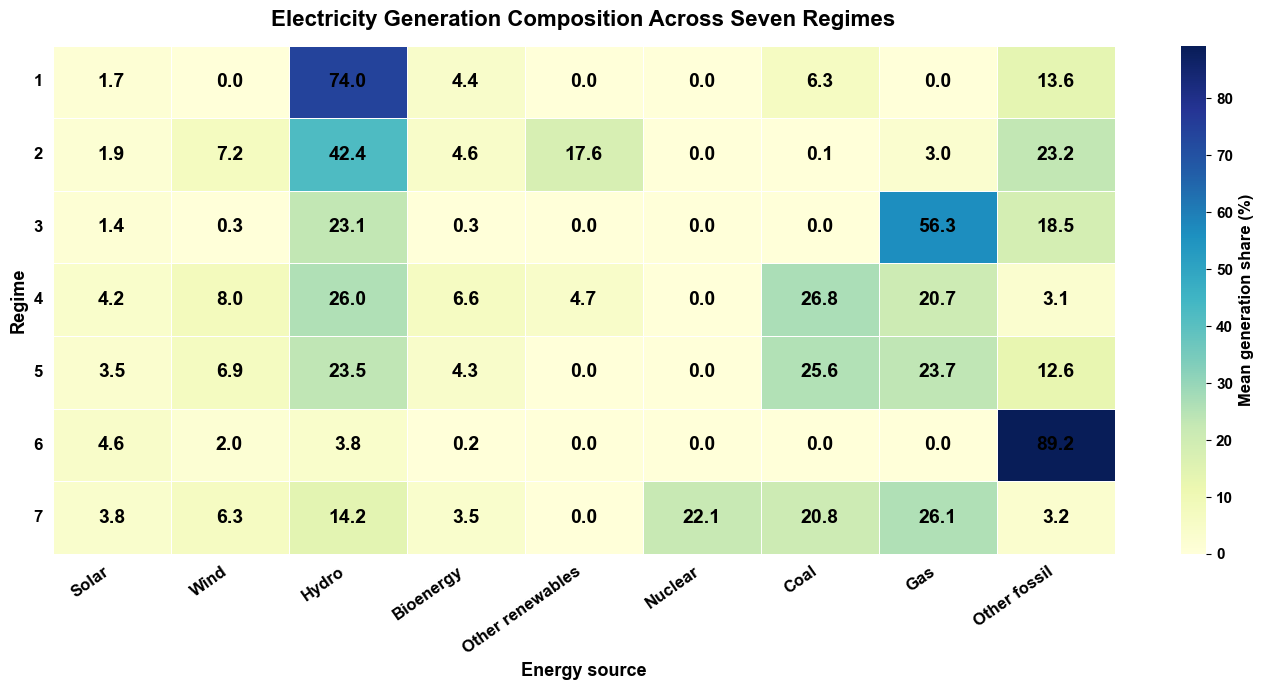

C:\Users\sadul\AppData\Local\Temp\ipykernel_20600\73555563.py:233: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.tight_layout()
C:\Users\sadul\AppData\Local\Temp\ipykernel_20600\73555563.py:234: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.savefig("Figure_K7_Carbon_2016_2024.png",dpi=900,
C:\Users\sadul\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


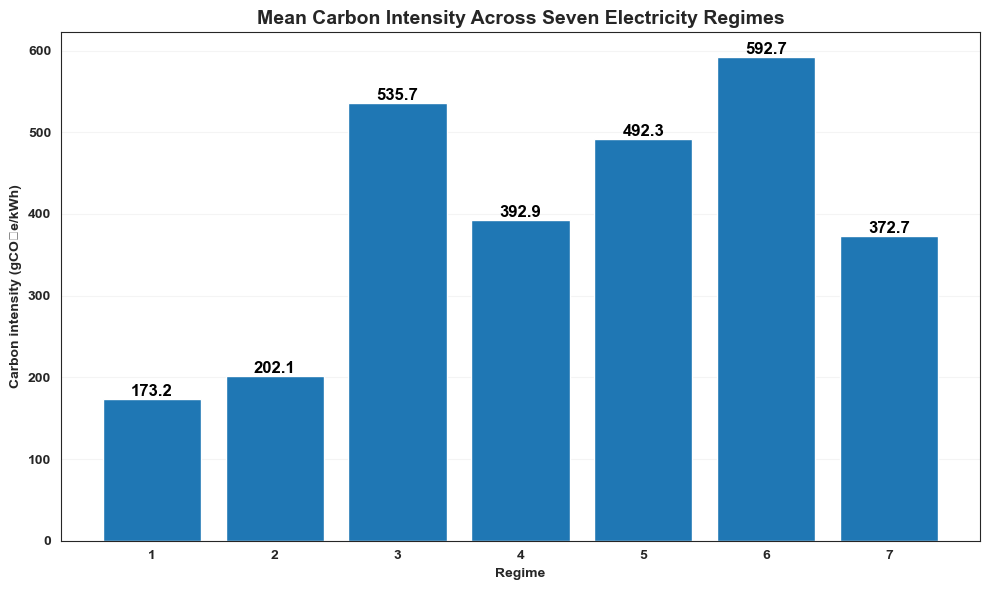

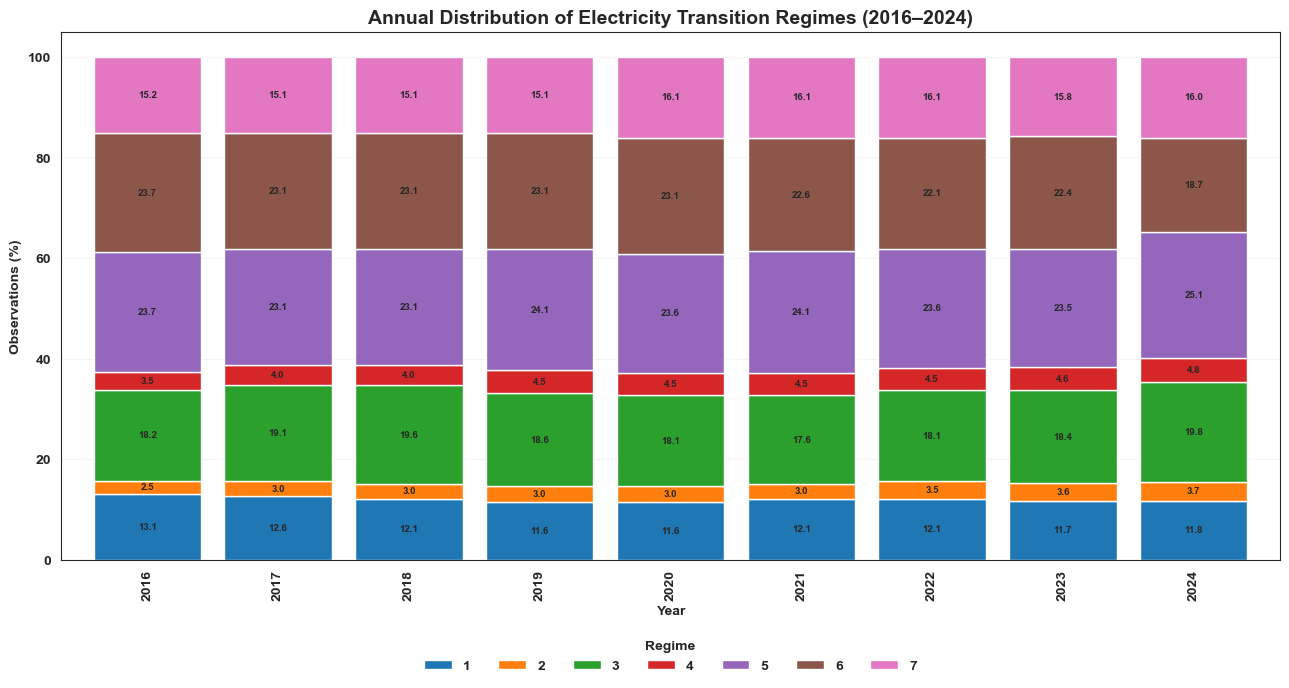

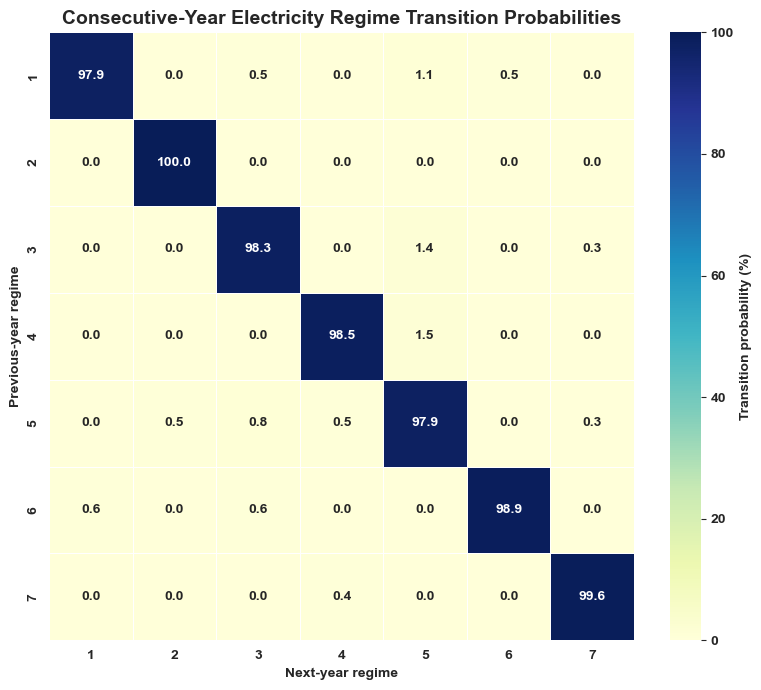


REGIME PROFILES
    Regime    N  Areas  Share_%  Carbon_Mean  Carbon_Median  Carbon_SD  Carbon_Q25  Carbon_Q75   Solar    Wind    Hydro  Bioenergy  Other renewables  Nuclear     Coal      Gas  Other fossil
0       1  214     28  12.0563     173.1647       138.5545   139.2053     47.9100    277.4298  1.7333  0.0000  74.0136     4.3636            0.0000   0.0000   6.2920   0.0000       13.5975
1       2   56      7   3.1549     202.1133       114.3640   178.9171     28.0320    328.0575  1.9281  7.1940  42.4417     4.6108           17.5895   0.0000   0.0550   3.0201       23.1608
2       3  330     42  18.5915     535.6750       582.0870   240.9229    401.1660    656.3052  1.4271  0.2669  23.1170     0.3318            0.0000   0.0000   0.0000  56.3427       18.5147
3       4   77     10   4.3380     392.9284       366.8600   182.8344    248.1610    535.1340  4.1585  7.9614  26.0268     6.5508            4.6784   0.0000  26.7626  20.7392        3.1224
4       5  422     53  23.7746     49

In [30]:

import os
os.environ["OMP_NUM_THREADS"]="7"

import numpy as np,pandas as pd,matplotlib.pyplot as plt,seaborn as sns
import statsmodels.formula.api as smf
from sklearn.mixture import GaussianMixture

# 1. DATA AND HELLINGER TRANSFORMATION
parts=["Solar","Wind","Hydro","Bioenergy","Other renewables","Nuclear","Coal","Gas","Other fossil"]
d=df_analysis.copy()
d["Year"]=pd.to_numeric(d["Year"],errors="coerce")
d=d[d["Year"].between(2016,2024)].copy()
for c in parts+["Carbon_Intensity"]:
    d[c]=pd.to_numeric(d[c],errors="coerce")
d=d.dropna(subset=["Area","Year"]+parts).reset_index(drop=True)

shares=d[parts].to_numpy(dtype=float)
if not np.isfinite(shares).all() or (shares<0).any():
    raise ValueError("Üretim paylarında negatif veya eksik değer var.")
row_sums=shares.sum(axis=1,keepdims=True)
if (row_sums<=0).any():
    raise ValueError("Sıfır toplamlı kompozisyon bulundu.")

P=shares/row_sums
X=np.sqrt(P)

assert X.shape==(len(d),9)
assert np.allclose((X**2).sum(axis=1),1,atol=1e-10)
assert len(d)==1775 and d["Area"].nunique()==199
assert d["Year"].nunique()==9 and d["Year"].min()==2016 and d["Year"].max()==2024

d["Log_CI"]=np.log1p(d["Carbon_Intensity"])
print("Sample:",len(d),"Areas:",d["Area"].nunique(),"Years:",d["Year"].nunique())
print("Original share-sum:",row_sums.min(),"-",row_sums.max())

# 2. FINAL K=7 GMM
gm7=GaussianMixture(n_components=7,covariance_type="diag",n_init=10,
                    reg_covar=1e-5,max_iter=1000,random_state=42)
d["Regime"]=gm7.fit_predict(X)+1
d["Regime"]=d["Regime"].astype(int)
if d["Regime"].nunique()!=7:
    raise ValueError("GMM yedi rejimin tamamını oluşturmadı.")
print("K=7 | BIC:",round(gm7.bic(X),3),"AIC:",round(gm7.aic(X),3),
      "| Converged:",gm7.converged_)

# 3. REGIME PROFILES
profile=[]
for r,g in d.groupby("Regime"):
    row={"Regime":r,"N":len(g),"Areas":g["Area"].nunique(),
         "Share_%":len(g)/len(d)*100,
         "Carbon_Mean":g["Carbon_Intensity"].mean(),
         "Carbon_Median":g["Carbon_Intensity"].median(),
         "Carbon_SD":g["Carbon_Intensity"].std(),
         "Carbon_Q25":g["Carbon_Intensity"].quantile(.25),
         "Carbon_Q75":g["Carbon_Intensity"].quantile(.75)}
    row.update(g[parts].mean().to_dict())
    profile.append(row)
profiles=pd.DataFrame(profile).sort_values("Regime")

# 4. CARBON INTENSITY MODELS
dc=d.dropna(subset=["Area","Year","Regime","Carbon_Intensity","Log_CI"]).copy()
dc["Area"]=dc["Area"].astype(str)
dc["Year"]=dc["Year"].astype(int)

m_year=smf.ols("Log_CI ~ C(Year)",data=dc).fit()
m_regime=smf.ols("Log_CI ~ C(Regime)+C(Year)",data=dc).fit(
    cov_type="cluster",cov_kwds={"groups":dc["Area"]})
m_area=smf.ols("Log_CI ~ C(Area)+C(Year)",data=dc).fit(
    cov_type="cluster",cov_kwds={"groups":dc["Area"]})
m_full=smf.ols("Log_CI ~ C(Area)+C(Year)+C(Regime)",data=dc).fit(
    cov_type="cluster",cov_kwds={"groups":dc["Area"]})

def joint_test(m):
    names=list(m.params.index)
    ix=[i for i,n in enumerate(names) if n.startswith("C(Regime)")]
    if not ix:
        raise ValueError("Modelde rejim katsayısı bulunamadı.")
    return m.wald_test(np.eye(len(names))[ix],scalar=True)

def model_row(name,m):
    return {"Model":name,"N":int(m.nobs),"R2":m.rsquared,"Adj_R2":m.rsquared_adj}

model_table=pd.DataFrame([
    model_row("Year FE",m_year),
    model_row("Regime + Year FE",m_regime),
    model_row("Area + Year FE",m_area),
    model_row("Area + Year + Regime FE",m_full)
])

wt_full,wt_regime=joint_test(m_full),joint_test(m_regime)
partial_r2=(m_full.rsquared-m_area.rsquared)/(1-m_area.rsquared)

def regime_coefs(m):
    z=pd.DataFrame({"Coefficient":m.params,"SE_Clustered":m.bse,
                    "P_Value":m.pvalues,"CI_Lower":m.conf_int()[0],
                    "CI_Upper":m.conf_int()[1]})
    z=z.loc[z.index.str.startswith("C(Regime)")].copy()
    z["Percent_Difference"]=(np.exp(z["Coefficient"])-1)*100
    return z

coef=regime_coefs(m_full)
carbon_tests=pd.DataFrame([
    {"Model":"Regime + Year FE","Wald_Chi2":float(np.asarray(wt_regime.statistic).squeeze()),
     "P_Value":float(wt_regime.pvalue),"Partial_R2":np.nan},
    {"Model":"Area + Year + Regime FE","Wald_Chi2":float(np.asarray(wt_full.statistic).squeeze()),
     "P_Value":float(wt_full.pvalue),"Partial_R2":partial_r2}
])

# 5. ANNUAL REGIME DISTRIBUTION
annual=pd.crosstab(d["Year"],d["Regime"],normalize="index").mul(100).reindex(
    index=range(2016,2025),columns=range(1,8),fill_value=0)
annual_n=pd.crosstab(d["Year"],d["Regime"]).reindex(
    index=range(2016,2025),columns=range(1,8),fill_value=0)

# 6. CONSECUTIVE-YEAR TRANSITIONS
trans=d[["Area","Year","Regime"]].sort_values(["Area","Year"]).copy()
trans["Next_Year"]=trans.groupby("Area")["Year"].shift(-1)
trans["Next_Regime"]=trans.groupby("Area")["Regime"].shift(-1)
pairs=trans[(trans["Next_Year"]-trans["Year"])==1].copy()
pairs["Next_Regime"]=pairs["Next_Regime"].astype(int)

transition_counts=pd.crosstab(pairs["Regime"],pairs["Next_Regime"]).reindex(
    index=range(1,8),columns=range(1,8),fill_value=0)
transition_prob=transition_counts.div(
    transition_counts.sum(axis=1).replace(0,np.nan),axis=0)*100

# 7. AREA-LEVEL STABILITY AND SWITCHERS
area_regimes=d.groupby("Area").agg(
    N_Years=("Year","nunique"),N_Regimes=("Regime","nunique"),
    First_Year=("Year","min"),Last_Year=("Year","max")
).reset_index()

switcher_areas=area_regimes.loc[area_regimes["N_Regimes"]>1,"Area"]
switcher_summary=area_regimes[area_regimes["Area"].isin(switcher_areas)].copy()
switchers_model_data=dc[dc["Area"].isin(switcher_areas)].copy()

if switchers_model_data["Area"].nunique()>=2:
    m_switch=smf.ols("Log_CI ~ C(Area)+C(Year)+C(Regime)",
                     data=switchers_model_data).fit(
        cov_type="cluster",cov_kwds={"groups":switchers_model_data["Area"]})
    wt_switch=joint_test(m_switch)
    switch_coef=regime_coefs(m_switch)
    switch_test=pd.DataFrame([{
        "N":int(m_switch.nobs),"Areas":switchers_model_data["Area"].nunique(),
        "Wald_Chi2":float(np.asarray(wt_switch.statistic).squeeze()),
        "P_Value":float(wt_switch.pvalue),"R2":m_switch.rsquared
    }])
else:
    switch_coef=pd.DataFrame()
    switch_test=pd.DataFrame()

# 8. GEOGRAPHICAL UNIT DOMINANT REGIME
area_regime_counts=pd.crosstab(d["Area"],d["Regime"]).reindex(
    columns=range(1,8),fill_value=0)
area_regime_summary=area_regime_counts.copy()
area_regime_summary["Total_Observations"]=area_regime_counts.sum(axis=1)
area_regime_summary["Dominant_Regime"]=area_regime_counts.idxmax(axis=1)
area_regime_summary["Dominant_Regime_N"]=area_regime_counts.max(axis=1)
area_regime_summary["Dominant_Regime_Share_%"]=(
    area_regime_summary["Dominant_Regime_N"]/
    area_regime_summary["Total_Observations"]*100
)
area_regime_summary["Tied_Dominant_Regimes"]=area_regime_counts.apply(
    lambda row:", ".join(map(str,row.index[row==row.max()])),axis=1
)
area_regime_summary=area_regime_summary.reset_index()
area_regime_summary=area_regime_summary.sort_values(
    ["Dominant_Regime","Area"]
)

# 9. EXPORT TABLES
tables=[
    (profiles,"Regime_Profiles",False),(model_table,"Carbon_Models",False),
    (coef,"Carbon_FE_Coefficients",True),(carbon_tests,"Carbon_Joint_Tests",False),
    (annual,"Annual_Regime_Share",True),(annual_n,"Annual_Regime_Counts",True),
    (transition_counts,"Transition_Counts",True),
    (transition_prob,"Transition_Probabilities",True),
    (area_regimes,"Area_Regime_History",False),
    (area_regime_summary,"Area_Dominant_Regime",False),
    (switcher_summary,"Switcher_Areas",False),
    (switch_coef,"Switcher_FE_Coefficients",True),
    (switch_test,"Switcher_Joint_Test",False)
]
with pd.ExcelWriter("K7_Final_Analysis_2016_2024.xlsx") as w:
    for obj,sheet,keep_index in tables:
        obj.to_excel(w,sheet_name=sheet,index=keep_index)
d.to_csv("K7_Final_Country_Year_Regimes_2016_2024.csv",index=False)
area_regime_summary.to_csv("K7_Area_Dominant_Regimes_2016_2024.csv",index=False)

# 10. PUBLICATION FIGURES
plt.rcParams.update({"font.family":"Arial","font.size":10,"font.weight":"bold",
                     "axes.titleweight":"bold","axes.labelweight":"bold"})
sns.set_style("white")

# FIGURE 3: REGIME COMPOSITION HEATMAP
fig,ax=plt.subplots(figsize=(14,7),facecolor="white")
sns.heatmap(
    profiles.set_index("Regime")[parts],
    annot=True,fmt=".1f",cmap="YlGnBu",linewidths=.5,
    annot_kws={"fontsize":14,"fontweight":"bold","color":"black"},
    cbar_kws={"label":"Mean generation share (%)"},ax=ax
)
ax.set_title("Electricity Generation Composition Across Seven Regimes",
             fontsize=16,fontweight="bold",color="black",pad=14)
ax.set_xlabel("Energy source",fontsize=13,fontweight="bold",color="black")
ax.set_ylabel("Regime",fontsize=13,fontweight="bold",color="black")
ax.set_xticklabels(ax.get_xticklabels(),rotation=35,ha="right",
                   fontsize=12,fontweight="bold",color="black")
ax.set_yticklabels(ax.get_yticklabels(),rotation=0,
                   fontsize=12,fontweight="bold",color="black")
ax.tick_params(axis="both",colors="black")
cbar=ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=11,colors="black")
cbar.set_label("Mean generation share (%)",fontsize=12,
               fontweight="bold",color="black")
for label in cbar.ax.get_yticklabels():
    label.set_fontweight("bold")
    label.set_color("black")
fig.tight_layout()
fig.savefig("Figure_K7_Composition_2016_2024.png",dpi=900,
            bbox_inches="tight",facecolor="white")
plt.show()

# FIGURE 4: CARBON INTENSITY BY REGIME
fig,ax=plt.subplots(figsize=(10,6),facecolor="white")
bars=ax.bar(profiles["Regime"].astype(str),profiles["Carbon_Mean"])
for b,v in zip(bars,profiles["Carbon_Mean"]):
    ax.text(b.get_x()+b.get_width()/2,v,f"{v:.1f}",
            ha="center",va="bottom",fontsize=12,color="black")
ax.set_title("Mean Carbon Intensity Across Seven Electricity Regimes")
ax.set_xlabel("Regime"); ax.set_ylabel("Carbon intensity (gCO₂e/kWh)")
ax.grid(axis="y",alpha=.2)
fig.tight_layout()
fig.savefig("Figure_K7_Carbon_2016_2024.png",dpi=900,
            bbox_inches="tight",facecolor="white")
plt.show()

# FIGURE 5: ANNUAL REGIME DISTRIBUTION
fig,ax=plt.subplots(figsize=(13,7),facecolor="white")
annual.plot(kind="bar",stacked=True,ax=ax,width=.82)
for i,year in enumerate(annual.index):
    bottom=0
    for r in range(1,8):
        val=annual.loc[year,r]
        if val>0:
            ax.text(i,bottom+val/2,f"{val:.1f}",
                    ha="center",va="center",fontsize=7)
            bottom+=val
ax.set_title("Annual Distribution of Electricity Transition Regimes (2016–2024)")
ax.set_xlabel("Year"); ax.set_ylabel("Observations (%)")
ax.legend(title="Regime",ncol=7,loc="upper center",
          bbox_to_anchor=(.5,-.13),frameon=False)
ax.grid(axis="y",alpha=.2)
fig.tight_layout()
fig.savefig("Figure_K7_Annual_2016_2024.png",dpi=900,
            bbox_inches="tight",facecolor="white")
plt.show()

# FIGURE 6: CONSECUTIVE-YEAR TRANSITIONS
fig,ax=plt.subplots(figsize=(8,7),facecolor="white")
sns.heatmap(transition_prob,annot=True,fmt=".1f",cmap="YlGnBu",
            vmin=0,vmax=100,linewidths=.5,
            cbar_kws={"label":"Transition probability (%)"},ax=ax)
ax.set_title("Consecutive-Year Electricity Regime Transition Probabilities")
ax.set_xlabel("Next-year regime"); ax.set_ylabel("Previous-year regime")
fig.tight_layout()
fig.savefig("Figure_K7_Transitions_2016_2024.png",dpi=900,
            bbox_inches="tight",facecolor="white")
plt.show()

# 11. FINAL OUTPUT
assert len(d)==1775 and d["Year"].max()==2024
assert annual.shape==(9,7) and area_regimes["Last_Year"].max()<=2024
assert area_regime_summary["Area"].nunique()==199

for title,table in [
    ("REGIME PROFILES",profiles),("CARBON MODEL COMPARISON",model_table),
    ("CARBON JOINT TESTS",carbon_tests),("FULL-SAMPLE REGIME COEFFICIENTS",coef),
    ("ANNUAL REGIME SHARES (%)",annual),("ANNUAL REGIME COUNTS",annual_n),
    ("TRANSITION COUNTS",transition_counts),
    ("TRANSITION PROBABILITIES (%)",transition_prob),
    ("AREA DOMINANT REGIMES",area_regime_summary),
    ("SWITCHER SUMMARY",switcher_summary),("SWITCHER MODEL TEST",switch_test),
    ("SWITCHER REGIME COEFFICIENTS",switch_coef)
]:
    print(f"\n{title}\n",table.round(4).to_string())

print("\nSWITCHER AREAS:",len(switcher_areas),"/",d["Area"].nunique())
print("\nFILES SAVED: Excel, CSV and 4 PNG figures.")
print("ANALYSIS COMPLETED.")


Sample: 1775 Areas: 199 Years: 9
Original share-sum: 99.982 - 100.01400000000001


C:\Users\sadul\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=7.
  warnings.warn(
C:\Users\sadul\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=7.
  warnings.warn(
C:\Users\sadul\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=7.
  warnings.warn(
C:\Users\sadul\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

K=7 | BIC: -47336.5 AIC: -48060.066 | Converged: True


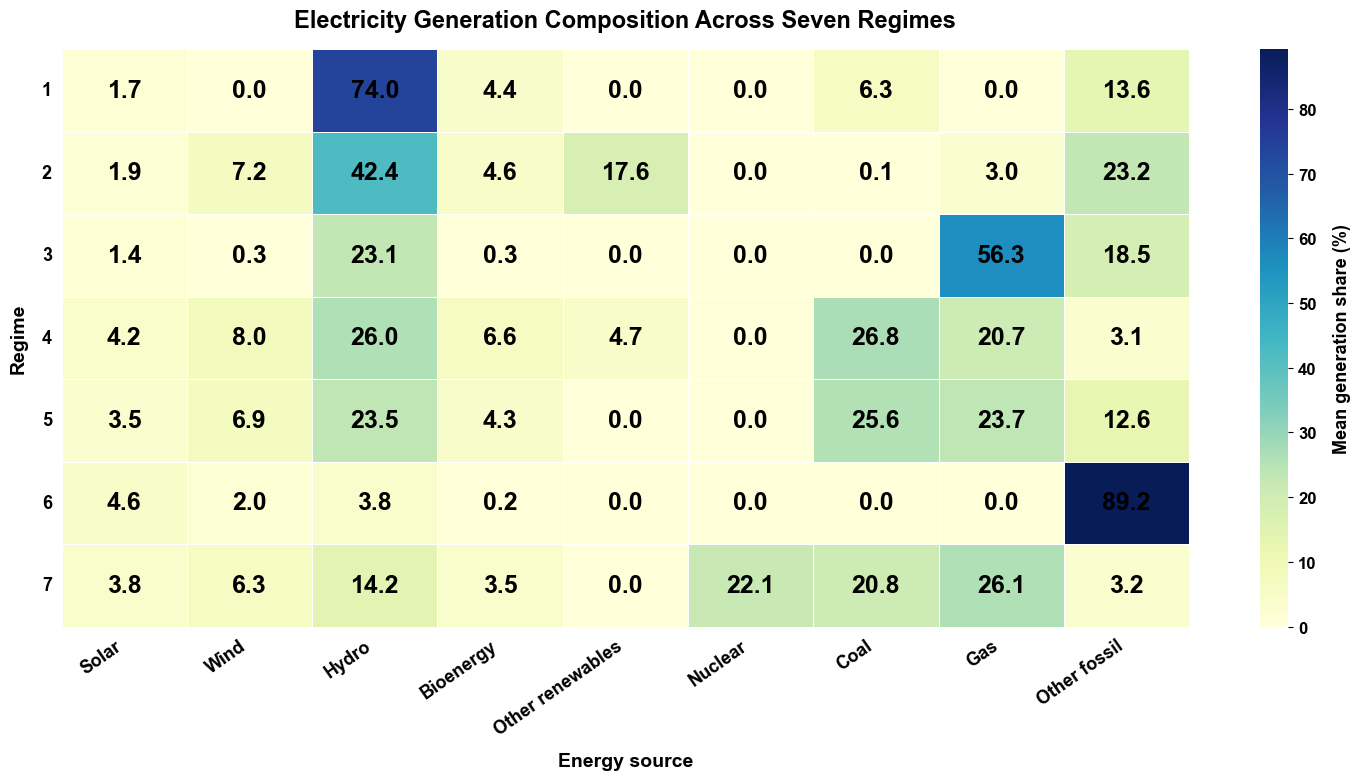

C:\Users\sadul\AppData\Local\Temp\ipykernel_30924\261175310.py:246: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.tight_layout()
C:\Users\sadul\AppData\Local\Temp\ipykernel_30924\261175310.py:247: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.savefig("Figure_4_Carbon_2016_2024.png",dpi=900,
C:\Users\sadul\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


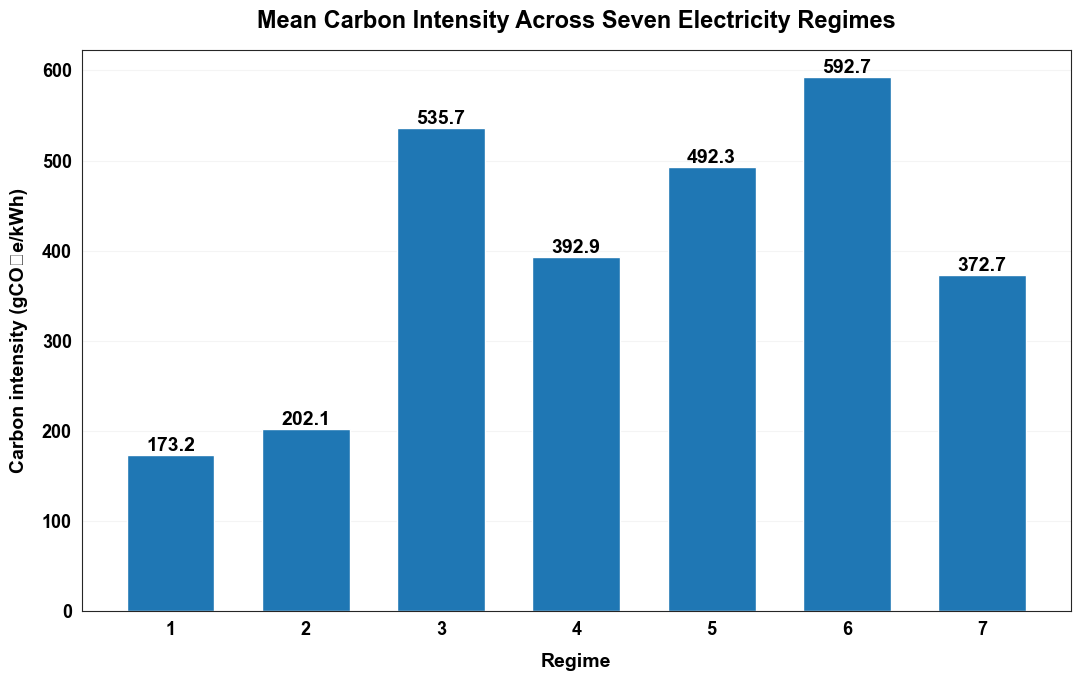

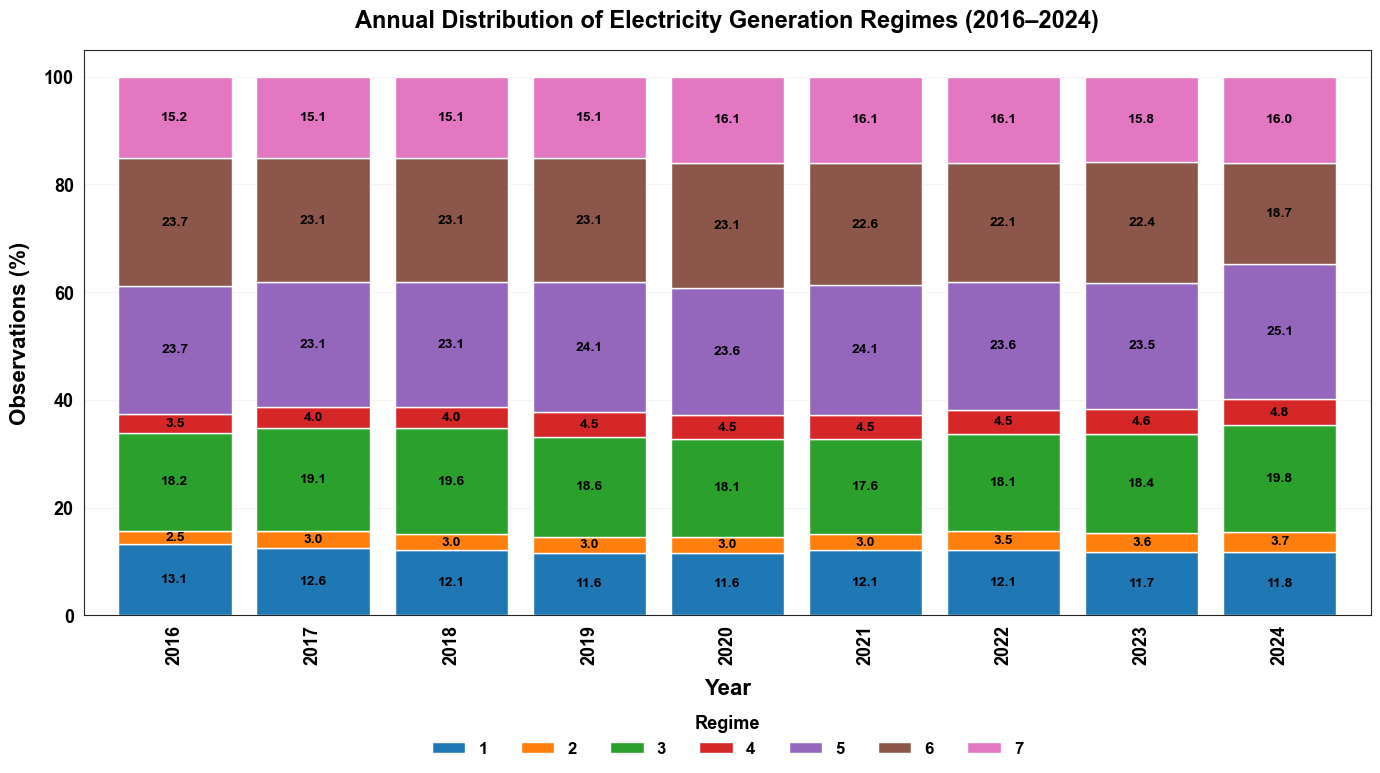

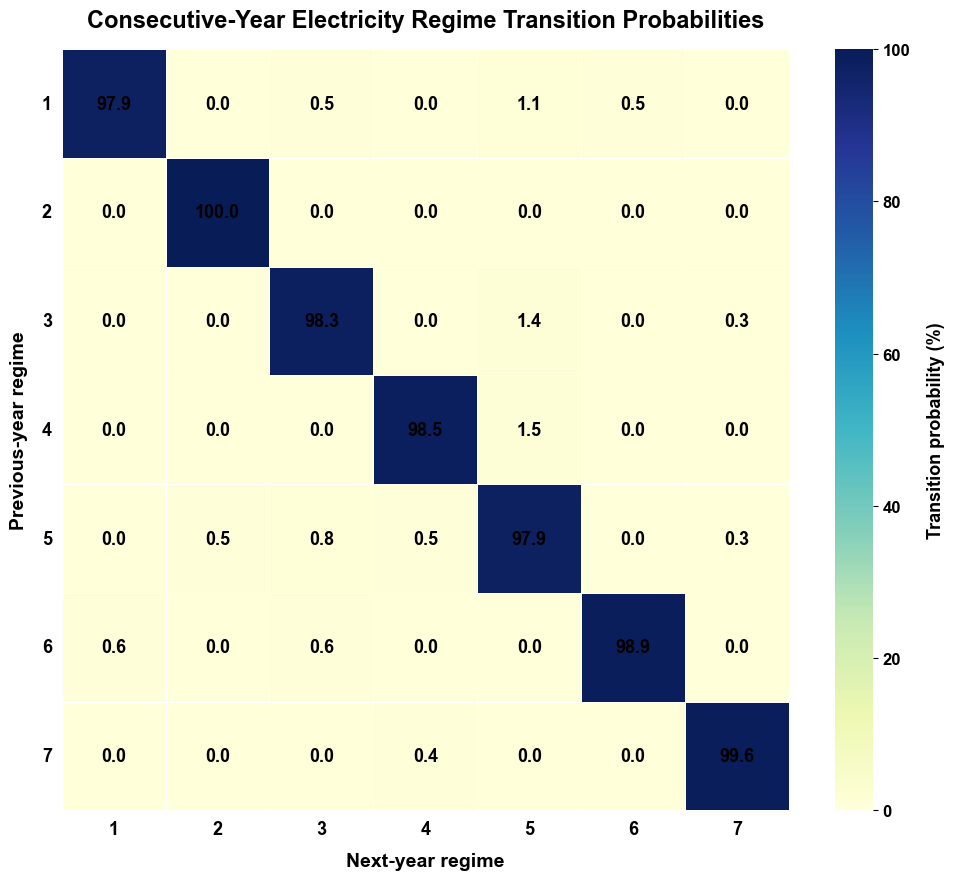


REGIME PROFILES
    Regime    N  Areas  Share_%  Carbon_Mean  Carbon_Median  Carbon_SD  Carbon_Q25  Carbon_Q75   Solar    Wind    Hydro  Bioenergy  Other renewables  Nuclear     Coal      Gas  Other fossil
0       1  214     28  12.0563     173.1647       138.5545   139.2053     47.9100    277.4298  1.7333  0.0000  74.0136     4.3636            0.0000   0.0000   6.2920   0.0000       13.5975
1       2   56      7   3.1549     202.1133       114.3640   178.9171     28.0320    328.0575  1.9281  7.1940  42.4417     4.6108           17.5895   0.0000   0.0550   3.0201       23.1608
2       3  330     42  18.5915     535.6750       582.0870   240.9229    401.1660    656.3052  1.4271  0.2669  23.1170     0.3318            0.0000   0.0000   0.0000  56.3427       18.5147
3       4   77     10   4.3380     392.9284       366.8600   182.8344    248.1610    535.1340  4.1585  7.9614  26.0268     6.5508            4.6784   0.0000  26.7626  20.7392        3.1224
4       5  422     53  23.7746     49

In [15]:

import os
os.environ["OMP_NUM_THREADS"]="7"

import numpy as np,pandas as pd,matplotlib.pyplot as plt,seaborn as sns
import statsmodels.formula.api as smf
from sklearn.mixture import GaussianMixture

# 1. DATA AND HELLINGER TRANSFORMATION
parts=["Solar","Wind","Hydro","Bioenergy","Other renewables","Nuclear","Coal","Gas","Other fossil"]
d=df_analysis.copy()
d["Year"]=pd.to_numeric(d["Year"],errors="coerce")
d=d[d["Year"].between(2016,2024)].copy()
for c in parts+["Carbon_Intensity"]:
    d[c]=pd.to_numeric(d[c],errors="coerce")
d=d.dropna(subset=["Area","Year"]+parts).reset_index(drop=True)

shares=d[parts].to_numpy(dtype=float)
if not np.isfinite(shares).all() or (shares<0).any():
    raise ValueError("Üretim paylarında negatif veya eksik değer var.")
row_sums=shares.sum(axis=1,keepdims=True)
if (row_sums<=0).any():
    raise ValueError("Sıfır toplamlı kompozisyon bulundu.")

P=shares/row_sums
X=np.sqrt(P)
assert X.shape==(len(d),9)
assert np.allclose((X**2).sum(axis=1),1,atol=1e-10)
assert len(d)==1775 and d["Area"].nunique()==199
assert d["Year"].nunique()==9 and d["Year"].min()==2016 and d["Year"].max()==2024

d["Log_CI"]=np.log1p(d["Carbon_Intensity"])
print("Sample:",len(d),"Areas:",d["Area"].nunique(),"Years:",d["Year"].nunique())
print("Original share-sum:",row_sums.min(),"-",row_sums.max())

# 2. FINAL K=7 GMM
gm7=GaussianMixture(n_components=7,covariance_type="diag",n_init=10,
                    reg_covar=1e-5,max_iter=1000,random_state=42)
d["Regime"]=gm7.fit_predict(X)+1
d["Regime"]=d["Regime"].astype(int)
if d["Regime"].nunique()!=7:
    raise ValueError("GMM yedi rejimin tamamını oluşturmadı.")
print("K=7 | BIC:",round(gm7.bic(X),3),"AIC:",round(gm7.aic(X),3),
      "| Converged:",gm7.converged_)

# 3. REGIME PROFILES
profile=[]
for r,g in d.groupby("Regime"):
    row={"Regime":r,"N":len(g),"Areas":g["Area"].nunique(),
         "Share_%":len(g)/len(d)*100,
         "Carbon_Mean":g["Carbon_Intensity"].mean(),
         "Carbon_Median":g["Carbon_Intensity"].median(),
         "Carbon_SD":g["Carbon_Intensity"].std(),
         "Carbon_Q25":g["Carbon_Intensity"].quantile(.25),
         "Carbon_Q75":g["Carbon_Intensity"].quantile(.75)}
    row.update(g[parts].mean().to_dict())
    profile.append(row)
profiles=pd.DataFrame(profile).sort_values("Regime")

# 4. CARBON INTENSITY MODELS
dc=d.dropna(subset=["Area","Year","Regime","Carbon_Intensity","Log_CI"]).copy()
dc["Area"]=dc["Area"].astype(str)
dc["Year"]=dc["Year"].astype(int)

m_year=smf.ols("Log_CI ~ C(Year)",data=dc).fit()
m_regime=smf.ols("Log_CI ~ C(Regime)+C(Year)",data=dc).fit(
    cov_type="cluster",cov_kwds={"groups":dc["Area"]})
m_area=smf.ols("Log_CI ~ C(Area)+C(Year)",data=dc).fit(
    cov_type="cluster",cov_kwds={"groups":dc["Area"]})
m_full=smf.ols("Log_CI ~ C(Area)+C(Year)+C(Regime)",data=dc).fit(
    cov_type="cluster",cov_kwds={"groups":dc["Area"]})

def joint_test(m):
    names=list(m.params.index)
    ix=[i for i,n in enumerate(names) if n.startswith("C(Regime)")]
    if not ix:
        raise ValueError("Modelde rejim katsayısı bulunamadı.")
    return m.wald_test(np.eye(len(names))[ix],scalar=True)

def model_row(name,m):
    return {"Model":name,"N":int(m.nobs),"R2":m.rsquared,"Adj_R2":m.rsquared_adj}

model_table=pd.DataFrame([
    model_row("Year FE",m_year),
    model_row("Regime + Year FE",m_regime),
    model_row("Area + Year FE",m_area),
    model_row("Area + Year + Regime FE",m_full)
])

wt_full,wt_regime=joint_test(m_full),joint_test(m_regime)
partial_r2=(m_full.rsquared-m_area.rsquared)/(1-m_area.rsquared)

def regime_coefs(m):
    z=pd.DataFrame({"Coefficient":m.params,"SE_Clustered":m.bse,
                    "P_Value":m.pvalues,"CI_Lower":m.conf_int()[0],
                    "CI_Upper":m.conf_int()[1]})
    z=z.loc[z.index.str.startswith("C(Regime)")].copy()
    z["Percent_Difference"]=(np.exp(z["Coefficient"])-1)*100
    return z

coef=regime_coefs(m_full)
carbon_tests=pd.DataFrame([
    {"Model":"Regime + Year FE","Wald_Chi2":float(np.asarray(wt_regime.statistic).squeeze()),
     "P_Value":float(wt_regime.pvalue),"Partial_R2":np.nan},
    {"Model":"Area + Year + Regime FE","Wald_Chi2":float(np.asarray(wt_full.statistic).squeeze()),
     "P_Value":float(wt_full.pvalue),"Partial_R2":partial_r2}
])

# 5. ANNUAL REGIME DISTRIBUTION
annual=pd.crosstab(d["Year"],d["Regime"],normalize="index").mul(100).reindex(
    index=range(2016,2025),columns=range(1,8),fill_value=0)
annual_n=pd.crosstab(d["Year"],d["Regime"]).reindex(
    index=range(2016,2025),columns=range(1,8),fill_value=0)

# 6. CONSECUTIVE-YEAR TRANSITIONS
trans=d[["Area","Year","Regime"]].sort_values(["Area","Year"]).copy()
trans["Next_Year"]=trans.groupby("Area")["Year"].shift(-1)
trans["Next_Regime"]=trans.groupby("Area")["Regime"].shift(-1)
pairs=trans[(trans["Next_Year"]-trans["Year"])==1].copy()
pairs["Next_Regime"]=pairs["Next_Regime"].astype(int)

transition_counts=pd.crosstab(pairs["Regime"],pairs["Next_Regime"]).reindex(
    index=range(1,8),columns=range(1,8),fill_value=0)
transition_prob=transition_counts.div(
    transition_counts.sum(axis=1).replace(0,np.nan),axis=0)*100

# 7. AREA-LEVEL STABILITY AND SWITCHERS
area_regimes=d.groupby("Area").agg(
    N_Years=("Year","nunique"),N_Regimes=("Regime","nunique"),
    First_Year=("Year","min"),Last_Year=("Year","max")
).reset_index()

switcher_areas=area_regimes.loc[area_regimes["N_Regimes"]>1,"Area"]
switcher_summary=area_regimes[area_regimes["Area"].isin(switcher_areas)].copy()
switchers_model_data=dc[dc["Area"].isin(switcher_areas)].copy()

if switchers_model_data["Area"].nunique()>=2:
    m_switch=smf.ols("Log_CI ~ C(Area)+C(Year)+C(Regime)",
                     data=switchers_model_data).fit(
        cov_type="cluster",cov_kwds={"groups":switchers_model_data["Area"]})
    wt_switch=joint_test(m_switch)
    switch_coef=regime_coefs(m_switch)
    switch_test=pd.DataFrame([{
        "N":int(m_switch.nobs),"Areas":switchers_model_data["Area"].nunique(),
        "Wald_Chi2":float(np.asarray(wt_switch.statistic).squeeze()),
        "P_Value":float(wt_switch.pvalue),"R2":m_switch.rsquared
    }])
else:
    switch_coef=pd.DataFrame()
    switch_test=pd.DataFrame()

# 8. GEOGRAPHICAL UNIT DOMINANT REGIME
area_regime_counts=pd.crosstab(d["Area"],d["Regime"]).reindex(
    columns=range(1,8),fill_value=0)
area_regime_summary=area_regime_counts.copy()
area_regime_summary["Total_Observations"]=area_regime_counts.sum(axis=1)
area_regime_summary["Dominant_Regime"]=area_regime_counts.idxmax(axis=1)
area_regime_summary["Dominant_Regime_N"]=area_regime_counts.max(axis=1)
area_regime_summary["Dominant_Regime_Share_%"]=(
    area_regime_summary["Dominant_Regime_N"]/
    area_regime_summary["Total_Observations"]*100
)
area_regime_summary["Tied_Dominant_Regimes"]=area_regime_counts.apply(
    lambda row:", ".join(map(str,row.index[row==row.max()])),axis=1
)
area_regime_summary=area_regime_summary.reset_index().sort_values(
    ["Dominant_Regime","Area"])

# 9. EXPORT TABLES
tables=[
    (profiles,"Regime_Profiles",False),(model_table,"Carbon_Models",False),
    (coef,"Carbon_FE_Coefficients",True),(carbon_tests,"Carbon_Joint_Tests",False),
    (annual,"Annual_Regime_Share",True),(annual_n,"Annual_Regime_Counts",True),
    (transition_counts,"Transition_Counts",True),
    (transition_prob,"Transition_Probabilities",True),
    (area_regimes,"Area_Regime_History",False),
    (area_regime_summary,"Area_Dominant_Regime",False),
    (switcher_summary,"Switcher_Areas",False),
    (switch_coef,"Switcher_FE_Coefficients",True),
    (switch_test,"Switcher_Joint_Test",False)
]
with pd.ExcelWriter("K7_Final_Analysis_2016_2024.xlsx") as w:
    for obj,sheet,keep_index in tables:
        obj.to_excel(w,sheet_name=sheet,index=keep_index)
d.to_csv("K7_Final_Country_Year_Regimes_2016_2024.csv",index=False)
area_regime_summary.to_csv("K7_Area_Dominant_Regimes_2016_2024.csv",index=False)

# 10. GLOBAL FIGURE SETTINGS
plt.rcParams.update({
    "font.family":"Arial","font.size":13,"font.weight":"bold",
    "text.color":"black","axes.titleweight":"bold",
    "axes.labelweight":"bold","axes.labelcolor":"black",
    "axes.edgecolor":"black","xtick.color":"black",
    "ytick.color":"black","xtick.labelsize":12,
    "ytick.labelsize":12,"axes.titlesize":17,
    "axes.labelsize":14,"legend.fontsize":12,
    "legend.title_fontsize":13,"figure.facecolor":"white",
    "savefig.facecolor":"white"
})
sns.set_style("white")

# FIGURE 3: REGIME COMPOSITION HEATMAP
fig,ax=plt.subplots(figsize=(15,8),facecolor="white")
sns.heatmap(
    profiles.set_index("Regime")[parts],annot=True,fmt=".1f",
    cmap="YlGnBu",linewidths=.6,
    annot_kws={"fontsize":18,"fontweight":"bold","color":"black"},
    cbar_kws={"label":"Mean generation share (%)"},ax=ax
)
ax.set_title("Electricity Generation Composition Across Seven Regimes",
             fontsize=17,fontweight="bold",color="black",pad=16)
ax.set_xlabel("Energy source",fontsize=14,fontweight="bold",color="black",labelpad=10)
ax.set_ylabel("Regime",fontsize=14,fontweight="bold",color="black",labelpad=10)
ax.set_xticklabels(ax.get_xticklabels(),rotation=35,ha="right",
                   fontsize=13,fontweight="bold",color="black")
ax.set_yticklabels(ax.get_yticklabels(),rotation=0,
                   fontsize=13,fontweight="bold",color="black")
ax.tick_params(axis="both",colors="black",labelsize=13)
cbar=ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=12,colors="black")
cbar.set_label("Mean generation share (%)",fontsize=13,
               fontweight="bold",color="black",labelpad=12)
for label in cbar.ax.get_yticklabels():
    label.set_fontweight("bold")
    label.set_color("black")
fig.tight_layout()
fig.savefig("Figure_3_Composition_2016_2024.png",dpi=900,
            bbox_inches="tight",facecolor="white")
plt.show()

# FIGURE 4: CARBON INTENSITY BY REGIME
fig,ax=plt.subplots(figsize=(11,7),facecolor="white")
bars=ax.bar(profiles["Regime"].astype(str),profiles["Carbon_Mean"],width=.65)
for b,v in zip(bars,profiles["Carbon_Mean"]):
    ax.text(b.get_x()+b.get_width()/2,v,f"{v:.1f}",
            ha="center",va="bottom",fontsize=14,fontweight="bold",color="black")
ax.set_title("Mean Carbon Intensity Across Seven Electricity Regimes",
             fontsize=17,fontweight="bold",color="black",pad=16)
ax.set_xlabel("Regime",fontsize=14,fontweight="bold",color="black",labelpad=10)
ax.set_ylabel("Carbon intensity (gCO₂e/kWh)",fontsize=14,
              fontweight="bold",color="black",labelpad=10)
ax.tick_params(axis="both",labelsize=13,colors="black")
for label in ax.get_xticklabels()+ax.get_yticklabels():
    label.set_fontweight("bold")
    label.set_color("black")
ax.grid(axis="y",alpha=.2)
fig.tight_layout()
fig.savefig("Figure_4_Carbon_2016_2024.png",dpi=900,
            bbox_inches="tight",facecolor="white")
plt.show()

# FIGURE 5: ANNUAL REGIME DISTRIBUTION
fig,ax=plt.subplots(figsize=(14,8),facecolor="white")
annual.plot(kind="bar",stacked=True,ax=ax,width=.82)
for i,year in enumerate(annual.index):
    bottom=0
    for r in range(1,8):
        val=annual.loc[year,r]
        if val>0:
            ax.text(i,bottom+val/2,f"{val:.1f}",
                    ha="center",va="center",fontsize=10,
                    fontweight="bold",color="black")
            bottom+=val
ax.set_title("Annual Distribution of Electricity Generation Regimes (2016–2024)",
             fontsize=17,fontweight="bold",color="black",pad=16)
ax.set_xlabel("Year",fontsize=16,fontweight="bold",color="black",labelpad=10)
ax.set_ylabel("Observations (%)",fontsize=16,fontweight="bold",
              color="black",labelpad=10)
ax.tick_params(axis="both",labelsize=13,colors="black")
for label in ax.get_xticklabels()+ax.get_yticklabels():
    label.set_fontweight("bold")
    label.set_color("black")
legend=ax.legend(title="Regime",ncol=7,loc="upper center",
                 bbox_to_anchor=(.5,-.15),frameon=False)
legend.get_title().set_fontweight("bold")
legend.get_title().set_color("black")
for label in legend.get_texts():
    label.set_fontweight("bold")
    label.set_color("black")
ax.grid(axis="y",alpha=.2)
fig.tight_layout()
fig.savefig("Figure_5_Annual_2016_2024.png",dpi=900,
            bbox_inches="tight",facecolor="white")
plt.show()

# FIGURE 6: CONSECUTIVE-YEAR TRANSITIONS
fig,ax=plt.subplots(figsize=(10,9),facecolor="white")
sns.heatmap(
    transition_prob,annot=True,fmt=".1f",cmap="YlGnBu",
    vmin=0,vmax=100,linewidths=.6,
    annot_kws={"fontsize":13,"fontweight":"bold","color":"black"},
    cbar_kws={"label":"Transition probability (%)"},ax=ax
)
ax.set_title("Consecutive-Year Electricity Regime Transition Probabilities",
             fontsize=17,fontweight="bold",color="black",pad=16)
ax.set_xlabel("Next-year regime",fontsize=14,fontweight="bold",
              color="black",labelpad=10)
ax.set_ylabel("Previous-year regime",fontsize=14,fontweight="bold",
              color="black",labelpad=10)
ax.set_xticklabels(ax.get_xticklabels(),fontsize=13,
                   fontweight="bold",color="black")
ax.set_yticklabels(ax.get_yticklabels(),fontsize=13,
                   fontweight="bold",color="black",rotation=0)
ax.tick_params(axis="both",colors="black",labelsize=13)
cbar=ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=12,colors="black")
cbar.set_label("Transition probability (%)",fontsize=13,
               fontweight="bold",color="black",labelpad=12)
for label in cbar.ax.get_yticklabels():
    label.set_fontweight("bold")
    label.set_color("black")
fig.tight_layout()
fig.savefig("Figure_6_Transitions_2016_2024.png",dpi=900,
            bbox_inches="tight",facecolor="white")
plt.show()

# 11. FINAL OUTPUT
assert len(d)==1775 and d["Year"].max()==2024
assert annual.shape==(9,7) and area_regimes["Last_Year"].max()<=2024
assert area_regime_summary["Area"].nunique()==199

for title,table in [
    ("REGIME PROFILES",profiles),("CARBON MODEL COMPARISON",model_table),
    ("CARBON JOINT TESTS",carbon_tests),("FULL-SAMPLE REGIME COEFFICIENTS",coef),
    ("ANNUAL REGIME SHARES (%)",annual),("ANNUAL REGIME COUNTS",annual_n),
    ("TRANSITION COUNTS",transition_counts),
    ("TRANSITION PROBABILITIES (%)",transition_prob),
    ("AREA DOMINANT REGIMES",area_regime_summary),
    ("SWITCHER SUMMARY",switcher_summary),("SWITCHER MODEL TEST",switch_test),
    ("SWITCHER REGIME COEFFICIENTS",switch_coef)
]:
    print(f"\n{title}\n",table.round(4).to_string())

print("\nSWITCHER AREAS:",len(switcher_areas),"/",d["Area"].nunique())
print("\nFILES SAVED: Excel, CSV and 4 PNG figures.")
print("ANALYSIS COMPLETED.")



FIGURE 4 - TRANSITION PROBABILITIES (%)
Next_Regime      1       2      3      4      5      6      7
Regime                                                       
1            97.89    0.00   0.53   0.00   1.05   0.53   0.00
2             0.00  100.00   0.00   0.00   0.00   0.00   0.00
3             0.00    0.00  98.29   0.00   1.37   0.00   0.34
4             0.00    0.00   0.00  98.53   1.47   0.00   0.00
5             0.00    0.53   0.80   0.53  97.86   0.00   0.27
6             0.56    0.00   0.56   0.00   0.00  98.87   0.00
7             0.00    0.00   0.00   0.41   0.00   0.00  99.59


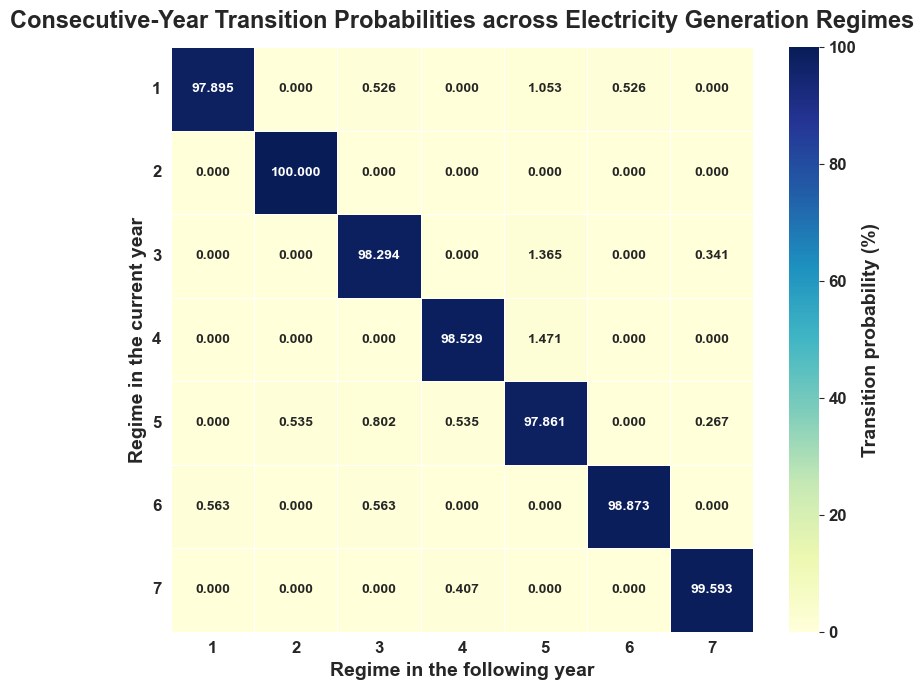

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams.update({
    "font.family":"Arial",
    "font.size":10,
    "font.weight":"bold",
    "axes.titleweight":"bold",
    "axes.labelweight":"bold"
})

# Görselde gösterilen sayısal değerleri konsola yazdır
print("\nFIGURE 4 - TRANSITION PROBABILITIES (%)")
print(transition_prob.round(2).to_string())

fig,ax=plt.subplots(figsize=(8,7),facecolor="white")
sns.heatmap(
    transition_prob,annot=True,fmt=".3f",cmap="YlGnBu",
    vmin=0,vmax=100,linewidths=.5,
    cbar_kws={"label":"Transition probability (%)"},ax=ax
)
ax.set_title("Consecutive-Year Transition Probabilities across Electricity Generation Regimes",pad=14)
ax.set_xlabel("Regime in the following year")
ax.set_ylabel("Regime in the current year")
ax.set_xticklabels(ax.get_xticklabels(),rotation=0)
ax.set_yticklabels(ax.get_yticklabels(),rotation=0)
fig.tight_layout()
fig.savefig("Figure_4_Consecutive_Year_Transitions.png",dpi=900,bbox_inches="tight",facecolor="white")
fig.savefig("Figure_4_Consecutive_Year_Transitions.svg",bbox_inches="tight",facecolor="white")
plt.show()

SAMPLE: 1775 AREAS: 199 YEARS: [np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]


C:\Users\sadul\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=7.
  warnings.warn(
C:\Users\sadul\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=7.
  warnings.warn(
C:\Users\sadul\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=7.
  warnings.warn(
C:\Users\sadul\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

BIC: -47336.50035138341 AIC: -48060.06570403546 Converged: True
REGIME COUNTS:
 Regime
1    214
2     56
3    330
4     77
5    422
6    399
7    277
Name: count, dtype: int64


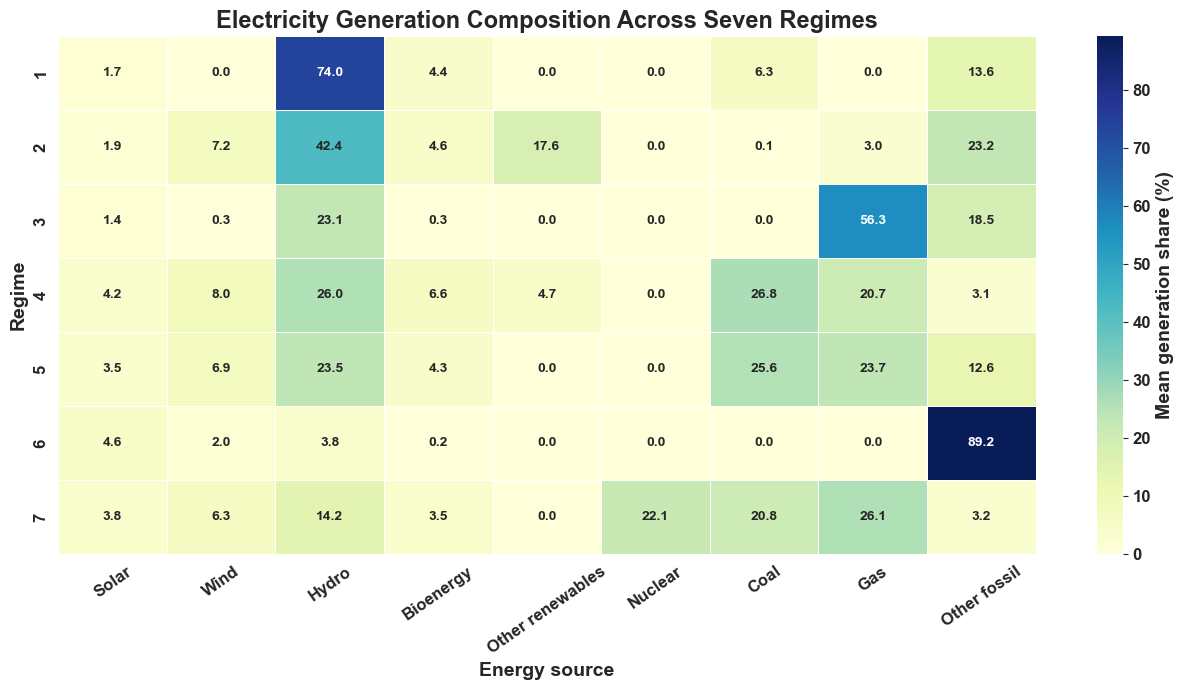

C:\Users\sadul\AppData\Local\Temp\ipykernel_30924\89240979.py:188: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  ax.grid(axis="y",alpha=.2); fig.tight_layout()
C:\Users\sadul\AppData\Local\Temp\ipykernel_30924\89240979.py:189: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.savefig("Figure_K7_Carbon.png",dpi=900,bbox_inches="tight",facecolor="white")
C:\Users\sadul\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


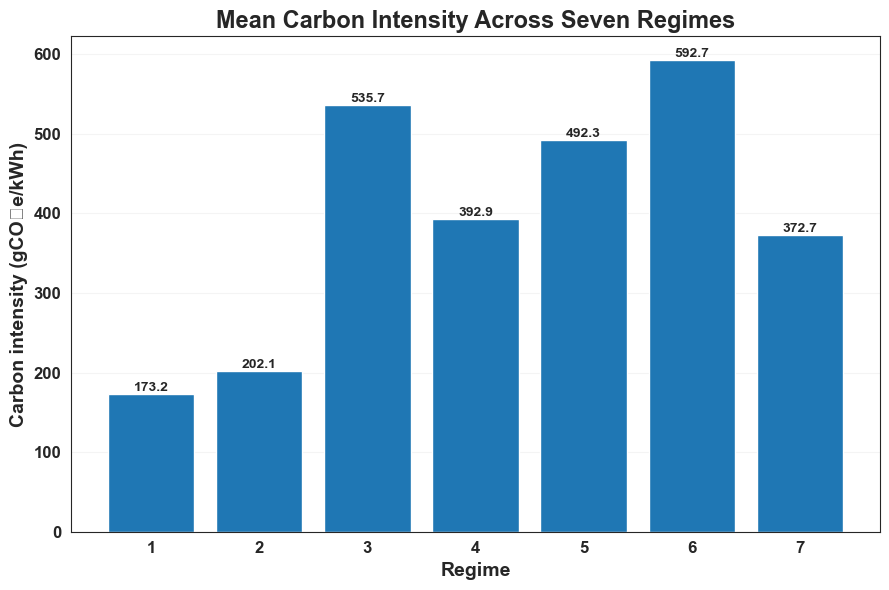

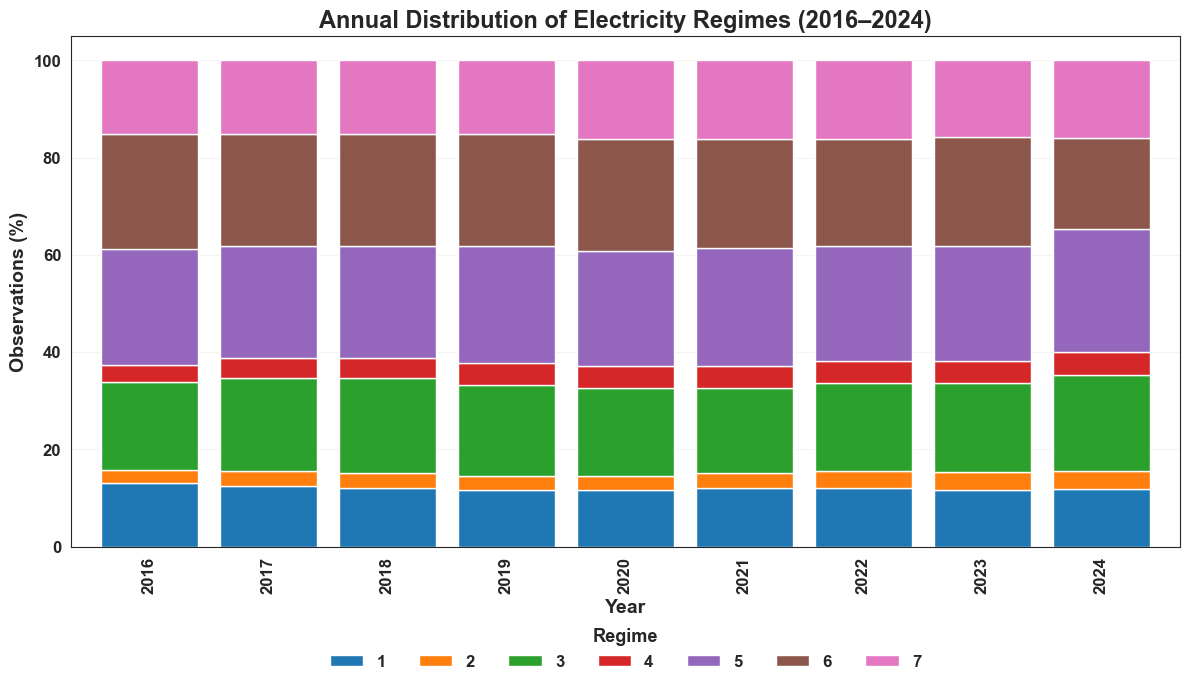

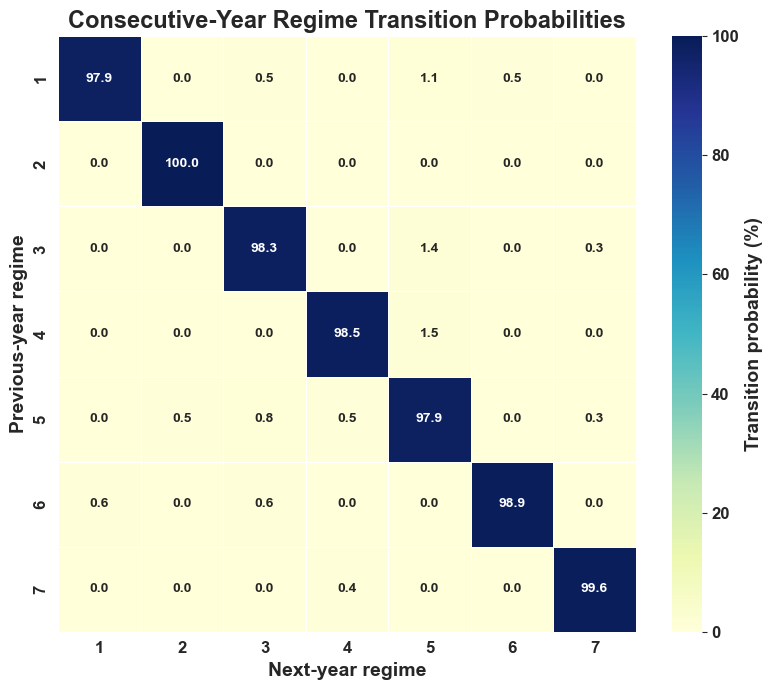


Regime_Profiles
  Regime   N  Areas  Carbon_Mean  Carbon_Median  Carbon_SD  Carbon_Min  Carbon_Max  Share_%  Solar   Wind   Hydro  Bioenergy  Other renewables  Nuclear    Coal     Gas  Other fossil
      1 214     28     173.1647       138.5545   139.2053      21.429     488.285  12.0563 1.7333 0.0000 74.0136     4.3636            0.0000   0.0000  6.2920  0.0000       13.5975
      2  56      7     202.1133       114.3640   178.9171      23.492     532.462   3.1549 1.9281 7.1940 42.4417     4.6108           17.5895   0.0000  0.0550  3.0201       23.1608
      3 330     42     535.6750       582.0870   240.9229      23.682    1306.569  18.5915 1.4271 0.2669 23.1170     0.3318            0.0000   0.0000  0.0000 56.3427       18.5147
      4  77     10     392.9284       366.8600   182.8344      87.363     710.466   4.3380 4.1585 7.9614 26.0268     6.5508            4.6784   0.0000 26.7626 20.7392        3.1224
      5 422     53     492.2989       554.1160   265.0796      23.321    1150

In [25]:
import os
os.environ["OMP_NUM_THREADS"]="7"

import numpy as np,pandas as pd,matplotlib.pyplot as plt,seaborn as sns
import statsmodels.formula.api as smf
from sklearn.mixture import GaussianMixture

# 1. FINAL SAMPLE AND HELLINGER TRANSFORMATION
parts=["Solar","Wind","Hydro","Bioenergy","Other renewables","Nuclear","Coal","Gas","Other fossil"]

d=df_analysis.copy()
d["Year"]=pd.to_numeric(d["Year"],errors="coerce")
d=d.loc[d["Year"].between(2016,2024)].copy().reset_index(drop=True)
for c in parts+["Carbon_Intensity"]:
    d[c]=pd.to_numeric(d[c],errors="coerce")
d=d.dropna(subset=["Area"]+parts).reset_index(drop=True)

shares=d[parts].to_numpy(dtype=float)
if not np.isfinite(shares).all() or (shares<0).any():
    raise ValueError("Üretim paylarında eksik, geçersiz veya negatif değer var.")
row_sums=shares.sum(axis=1,keepdims=True)
if (row_sums<=0).any():
    raise ValueError("Sıfır toplamlı kompozisyon bulundu.")

P=shares/row_sums
X=np.sqrt(P)
assert len(d)==1775 and d["Area"].nunique()==199
assert np.allclose((X**2).sum(axis=1),1,atol=1e-10)

d["Log_CI"]=np.log1p(d["Carbon_Intensity"])
print("SAMPLE:",len(d),"AREAS:",d["Area"].nunique(),
      "YEARS:",sorted(d["Year"].unique()))

# 2. FINAL K=7 GMM
gm7=GaussianMixture(n_components=7,covariance_type="diag",n_init=10,
                    reg_covar=1e-5,max_iter=1000,random_state=42)
d["Regime"]=gm7.fit_predict(X)+1
d["Regime"]=d["Regime"].astype(int)
if d["Regime"].nunique()!=7:
    raise ValueError("Yedi rejimin tamamı oluşmadı.")
print("BIC:",gm7.bic(X),"AIC:",gm7.aic(X),"Converged:",gm7.converged_)
print("REGIME COUNTS:\n",d["Regime"].value_counts().sort_index())

# 3. REGIME PROFILES
profiles=d.groupby("Regime").agg(
    N=("Area","size"),Areas=("Area","nunique"),
    Carbon_Mean=("Carbon_Intensity","mean"),
    Carbon_Median=("Carbon_Intensity","median"),
    Carbon_SD=("Carbon_Intensity","std"),
    Carbon_Min=("Carbon_Intensity","min"),
    Carbon_Max=("Carbon_Intensity","max")
).reset_index()
profiles["Share_%"]=profiles["N"]/len(d)*100
composition=d.groupby("Regime")[parts].mean().reset_index()
profiles=profiles.merge(composition,on="Regime")

# 4. CARBON INTENSITY FIXED-EFFECTS MODELS
dc=d.dropna(subset=["Carbon_Intensity","Log_CI"]).copy()
dc["Area"]=dc["Area"].astype(str)
dc["Year"]=dc["Year"].astype(int)

m_year=smf.ols("Log_CI ~ C(Year)",data=dc).fit()
m_regime=smf.ols("Log_CI ~ C(Regime)+C(Year)",data=dc).fit(
    cov_type="cluster",cov_kwds={"groups":dc["Area"]})
m_area=smf.ols("Log_CI ~ C(Area)+C(Year)",data=dc).fit(
    cov_type="cluster",cov_kwds={"groups":dc["Area"]})
m_full=smf.ols("Log_CI ~ C(Area)+C(Year)+C(Regime)",data=dc).fit(
    cov_type="cluster",cov_kwds={"groups":dc["Area"]})

def regime_test(m):
    names=list(m.params.index)
    idx=[i for i,n in enumerate(names) if n.startswith("C(Regime)")]
    if not idx:
        raise ValueError("Rejim katsayısı bulunamadı.")
    return m.wald_test(np.eye(len(names))[idx],scalar=True)

def regime_coefficients(m):
    z=pd.DataFrame({"Coefficient":m.params,"SE":m.bse,"P_Value":m.pvalues,
                    "CI_Lower":m.conf_int()[0],"CI_Upper":m.conf_int()[1]})
    z=z.loc[z.index.str.startswith("C(Regime)")].copy()
    z["Percent_Change_1plus_CI"]=(np.exp(z["Coefficient"])-1)*100
    return z

model_table=pd.DataFrame([
    {"Model":"Year FE","N":int(m_year.nobs),"R2":m_year.rsquared},
    {"Model":"Regime + Year FE","N":int(m_regime.nobs),"R2":m_regime.rsquared},
    {"Model":"Area + Year FE","N":int(m_area.nobs),"R2":m_area.rsquared},
    {"Model":"Area + Year + Regime FE","N":int(m_full.nobs),"R2":m_full.rsquared}
])
wt1,wt2=regime_test(m_regime),regime_test(m_full)
partial_r2=(m_full.rsquared-m_area.rsquared)/(1-m_area.rsquared)
joint_tests=pd.DataFrame([
    {"Model":"Regime + Year FE","Wald_Chi2":float(np.asarray(wt1.statistic).squeeze()),
     "P_Value":float(wt1.pvalue)},
    {"Model":"Area + Year + Regime FE","Wald_Chi2":float(np.asarray(wt2.statistic).squeeze()),
     "P_Value":float(wt2.pvalue),"Partial_R2":partial_r2}
])
coefficients=regime_coefficients(m_full)

# 5. ANNUAL REGIME DISTRIBUTION
annual=pd.crosstab(d["Year"],d["Regime"],normalize="index").mul(100).reindex(
    index=range(2016,2025),columns=range(1,8),fill_value=0)
annual_counts=pd.crosstab(d["Year"],d["Regime"]).reindex(
    index=range(2016,2025),columns=range(1,8),fill_value=0)

# 6. CONSECUTIVE-YEAR TRANSITIONS
s=d[["Area","Year","Regime"]].sort_values(["Area","Year"]).copy()
s["Next_Year"]=s.groupby("Area")["Year"].shift(-1)
s["Next_Regime"]=s.groupby("Area")["Regime"].shift(-1)
pairs=s[(s["Next_Year"]-s["Year"])==1].copy()
pairs["Next_Regime"]=pairs["Next_Regime"].astype(int)

transition_counts=pd.crosstab(pairs["Regime"],pairs["Next_Regime"]).reindex(
    index=range(1,8),columns=range(1,8),fill_value=0)
transition_prob=transition_counts.div(
    transition_counts.sum(axis=1).replace(0,np.nan),axis=0)*100

# 7. AREA-LEVEL REGIME STABILITY
area_history=d.sort_values(["Area","Year"]).groupby("Area").agg(
    N_Years=("Year","nunique"),N_Regimes=("Regime","nunique"),
    First_Year=("Year","min"),Last_Year=("Year","max")
).reset_index()
area_history["Regime_Changes"]=d.sort_values(["Area","Year"]).groupby(
    "Area")["Regime"].apply(lambda x:(x.diff().fillna(0)!=0).sum()).values
switchers=area_history[area_history["Regime_Changes"]>0].copy()

# 8. SWITCHER-ONLY FIXED-EFFECTS MODEL
switch_data=dc[dc["Area"].isin(switchers["Area"].astype(str))].copy()
if switch_data["Area"].nunique()>=2:
    m_switch=smf.ols("Log_CI ~ C(Area)+C(Year)+C(Regime)",data=switch_data).fit(
        cov_type="cluster",cov_kwds={"groups":switch_data["Area"]})
    wts=regime_test(m_switch)
    switch_test=pd.DataFrame([{
        "N":int(m_switch.nobs),"Areas":switch_data["Area"].nunique(),
        "R2":m_switch.rsquared,
        "Wald_Chi2":float(np.asarray(wts.statistic).squeeze()),
        "P_Value":float(wts.pvalue)}])
    switch_coefficients=regime_coefficients(m_switch)
else:
    switch_test=pd.DataFrame()
    switch_coefficients=pd.DataFrame()

# 9. EXPORT TABLES
output={
    "Regime_Profiles":profiles,
    "Carbon_Models":model_table,
    "Carbon_Joint_Tests":joint_tests,
    "Carbon_FE_Coefficients":coefficients,
    "Annual_Regime_Shares":annual,
    "Annual_Regime_Counts":annual_counts,
    "Transition_Counts":transition_counts,
    "Transition_Probabilities":transition_prob,
    "Area_Regime_History":area_history,
    "Switcher_Areas":switchers,
    "Switcher_Test":switch_test,
    "Switcher_Coefficients":switch_coefficients
}
with pd.ExcelWriter("K7_Final_Analysis_2016_2024.xlsx") as writer:
    for name,table in output.items():
        table.to_excel(writer,sheet_name=name,index=False if name not in [
            "Annual_Regime_Shares","Annual_Regime_Counts",
            "Transition_Counts","Transition_Probabilities"] else True)
d.to_csv("K7_Final_Regime_Assignments_2016_2024.csv",index=False)

# 10. PUBLICATION FIGURES
plt.rcParams.update({"font.family":"Arial","font.size":10,
                     "font.weight":"bold","axes.titleweight":"bold",
                     "axes.labelweight":"bold"})
sns.set_style("white")

fig,ax=plt.subplots(figsize=(13,7),facecolor="white")
sns.heatmap(profiles.set_index("Regime")[parts],annot=True,fmt=".1f",
            cmap="YlGnBu",linewidths=.5,
            cbar_kws={"label":"Mean generation share (%)"},ax=ax)
ax.set_title("Electricity Generation Composition Across Seven Regimes")
ax.set_xlabel("Energy source"); ax.set_ylabel("Regime")
ax.tick_params(axis="x",rotation=35)
fig.tight_layout()
fig.savefig("Figure_K7_Composition.png",dpi=900,bbox_inches="tight",facecolor="white")
plt.show()

fig,ax=plt.subplots(figsize=(9,6),facecolor="white")
bars=ax.bar(profiles["Regime"].astype(str),profiles["Carbon_Mean"])
for b,v in zip(bars,profiles["Carbon_Mean"]):
    ax.text(b.get_x()+b.get_width()/2,v,f"{v:.1f}",ha="center",va="bottom")
ax.set_title("Mean Carbon Intensity Across Seven Regimes")
ax.set_xlabel("Regime"); ax.set_ylabel("Carbon intensity (gCO₂e/kWh)")
ax.grid(axis="y",alpha=.2); fig.tight_layout()
fig.savefig("Figure_K7_Carbon.png",dpi=900,bbox_inches="tight",facecolor="white")
plt.show()

fig,ax=plt.subplots(figsize=(12,7),facecolor="white")
annual.plot(kind="bar",stacked=True,ax=ax,width=.82)
ax.set_title("Annual Distribution of Electricity Regimes (2016–2024)")
ax.set_xlabel("Year"); ax.set_ylabel("Observations (%)")
ax.legend(title="Regime",ncol=7,loc="upper center",
          bbox_to_anchor=(.5,-.13),frameon=False)
ax.grid(axis="y",alpha=.2); fig.tight_layout()
fig.savefig("Figure_K7_Annual.png",dpi=900,bbox_inches="tight",facecolor="white")
plt.show()

fig,ax=plt.subplots(figsize=(8,7),facecolor="white")
sns.heatmap(transition_prob,annot=True,fmt=".1f",cmap="YlGnBu",
            vmin=0,vmax=100,linewidths=.5,
            cbar_kws={"label":"Transition probability (%)"},ax=ax)
ax.set_title("Consecutive-Year Regime Transition Probabilities")
ax.set_xlabel("Next-year regime"); ax.set_ylabel("Previous-year regime")
fig.tight_layout()
fig.savefig("Figure_K7_Transitions.png",dpi=900,bbox_inches="tight",facecolor="white")
plt.show()

# 11. RESULTS
for name,table in output.items():
    print(f"\n{name}\n",table.round(4).to_string(index=False))
print("\nGMM BIC:",round(gm7.bic(X),4),"AIC:",round(gm7.aic(X),4))
print("Consecutive-year transitions:",len(pairs))
print("Regime switches:",int((pairs["Regime"]!=pairs["Next_Regime"]).sum()))
print("Stable Areas:",int((area_history["Regime_Changes"]==0).sum()))
print("Switching Areas:",len(switchers))
print("\nANALYSIS COMPLETED.")

In [26]:
import numpy as np
import pandas as pd

parts = ["Solar","Wind","Hydro","Bioenergy","Other renewables","Nuclear","Coal","Gas","Other fossil"]
d["Regime"] = d["Regime"].astype(int)

profile = d.groupby("Regime").agg(
    N=("Area","size"),
    Areas=("Area","nunique"),
    Carbon_Mean=("Carbon_Intensity","mean"),
    Carbon_Median=("Carbon_Intensity","median"),
    Carbon_SD=("Carbon_Intensity","std"),
    Carbon_Min=("Carbon_Intensity","min"),
    Carbon_Max=("Carbon_Intensity","max")
)
profile["Share_%"] = 100*profile["N"]/len(d)
composition = d.groupby("Regime")[parts].mean()
profile = profile.join(composition.add_prefix("Mean_"))
profile = profile.sort_values("Carbon_Mean")

print("\nREGIME PROFILES")
print(profile.round(3).to_string())

annual = pd.crosstab(d["Year"],d["Regime"],normalize="index").mul(100)
print("\nANNUAL REGIME SHARES (%)")
print(annual.round(2).to_string())

d = d.sort_values(["Area","Year"]).copy()
d["Next_Year"] = d.groupby("Area")["Year"].shift(-1)
d["Next_Regime"] = d.groupby("Area")["Regime"].shift(-1)
pairs = d[(d["Next_Year"]-d["Year"])==1].copy()

transition_counts = pd.crosstab(pairs["Regime"],pairs["Next_Regime"])
transition_prob = transition_counts.div(transition_counts.sum(axis=1),axis=0)*100
print("\nCONSECUTIVE-YEAR TRANSITION COUNTS")
print(transition_counts.to_string())
print("\nTRANSITION PROBABILITIES (%)")
print(transition_prob.round(2).to_string())

switch = d.groupby("Area").agg(
    Years=("Year","nunique"),
    Regime_Count=("Regime","nunique"),
    First_Year=("Year","min"),
    Last_Year=("Year","max")
)
switch["Switcher"] = switch["Regime_Count"]>1
print("\nSWITCHER SUMMARY")
print(switch["Switcher"].value_counts().rename(index={True:"Switcher",False:"Non-switcher"}).to_string())
print("\nSWITCHER RATE (%):",round(100*switch["Switcher"].mean(),2))
print("\nREGIME COUNTS AMONG SWITCHERS")
print(d[d["Area"].isin(switch.index[switch["Switcher"]])].groupby("Regime")["Area"].nunique().to_string())


REGIME PROFILES
          N  Areas  Carbon_Mean  Carbon_Median  Carbon_SD  Carbon_Min  Carbon_Max  Share_%  Mean_Solar  Mean_Wind  Mean_Hydro  Mean_Bioenergy  Mean_Other renewables  Mean_Nuclear  Mean_Coal  Mean_Gas  Mean_Other fossil
Regime                                                                                                                                                                                                                    
1       214     28      173.165        138.555    139.205      21.429     488.285   12.056       1.733      0.000      74.014           4.364                  0.000         0.000      6.292     0.000             13.597
2        56      7      202.113        114.364    178.917      23.492     532.462    3.155       1.928      7.194      42.442           4.611                 17.589         0.000      0.055     3.020             23.161
7       277     32      372.706        383.807    193.598      34.894     779.447   15.606       3.763     

In [27]:
import statsmodels.formula.api as smf
import numpy as np
import pandas as pd

d = d.copy()
d["Log_CI"] = np.log1p(d["Carbon_Intensity"])
d["Regime"] = d["Regime"].astype("category")

m_base = smf.ols("Log_CI ~ C(Area)+C(Year)",data=d).fit(
    cov_type="cluster",cov_kwds={"groups":d["Area"]}
)
m_full = smf.ols("Log_CI ~ C(Area)+C(Year)+C(Regime)",data=d).fit(
    cov_type="cluster",cov_kwds={"groups":d["Area"]}
)

regime_terms = [x for x in m_full.params.index if "C(Regime)" in x]
constraint = ",".join(f"{x}=0" for x in regime_terms)
wald = m_full.wald_test(constraint,scalar=True)

partial_r2 = (m_full.rsquared-m_base.rsquared)/(1-m_base.rsquared)

coef_table = pd.DataFrame({
    "Coefficient":m_full.params[regime_terms],
    "Cluster_SE":m_full.bse[regime_terms],
    "p_value":m_full.pvalues[regime_terms],
    "CI_Lower":m_full.conf_int().loc[regime_terms,0],
    "CI_Upper":m_full.conf_int().loc[regime_terms,1]
})
coef_table["Exp_Coefficient_%"] = 100*np.expm1(coef_table["Coefficient"])

switch_areas = switch.index[switch["Switcher"]]
ds = d[d["Area"].isin(switch_areas)].copy()
m_switch = smf.ols("Log_CI ~ C(Area)+C(Year)+C(Regime)",data=ds).fit(
    cov_type="cluster",cov_kwds={"groups":ds["Area"]}
)

print("BASE MODEL R2:",round(m_base.rsquared,5))
print("FULL MODEL R2:",round(m_full.rsquared,5))
print("INCREMENTAL PARTIAL R2:",round(partial_r2,5))
print("JOINT REGIME WALD TEST:",wald)
print("\nREGIME COEFFICIENTS: AREA + YEAR FE")
print(coef_table.round(5).to_string())
print("\nSWITCHER-ONLY MODEL")
print("N:",len(ds),"Areas:",ds["Area"].nunique(),"R2:",round(m_switch.rsquared,5))
print(m_switch.summary().tables[1])

BASE MODEL R2: 0.98016
FULL MODEL R2: 0.98036
INCREMENTAL PARTIAL R2: 0.0098
JOINT REGIME WALD TEST: <Wald test (chi2): statistic=9.93318573566754, p-value=0.12749405900036156, df_denom=6>

REGIME COEFFICIENTS: AREA + YEAR FE
                Coefficient  Cluster_SE  p_value  CI_Lower  CI_Upper  Exp_Coefficient_%
C(Regime)[T.2]      0.12968     0.14199  0.36106  -0.14860   0.40797           13.84667
C(Regime)[T.3]      0.12744     0.13334  0.33919  -0.13390   0.38879           13.59209
C(Regime)[T.4]      0.05028     0.14417  0.72729  -0.23229   0.33284            5.15613
C(Regime)[T.5]      0.09987     0.12569  0.42684  -0.14647   0.34622           10.50310
C(Regime)[T.6]      0.17737     0.11498  0.12293  -0.04799   0.40274           19.40755
C(Regime)[T.7]      0.02725     0.13136  0.83565  -0.23021   0.28471            2.76258

SWITCHER-ONLY MODEL
N: 180 Areas: 20 R2: 0.9851
                                      coef    std err          z      P>|z|      [0.025      0.975]
---------

C:\Users\sadul\anaconda3\Lib\site-packages\statsmodels\base\model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 33, but rank is 14
  warnings.warn('covariance of constraints does not have full '


C:\Users\sadul\AppData\Local\Temp\ipykernel_30924\2522172805.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  means=z.groupby("Regime")["Carbon_Intensity"].mean()
C:\Users\sadul\AppData\Local\Temp\ipykernel_30924\2522172805.py:15: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  profile=d.groupby("Regime").agg(N=("Carbon_Intensity","count"),Areas=("Area","nunique"),Mean=("Carbon_Intensity","mean")).reindex(regimes)


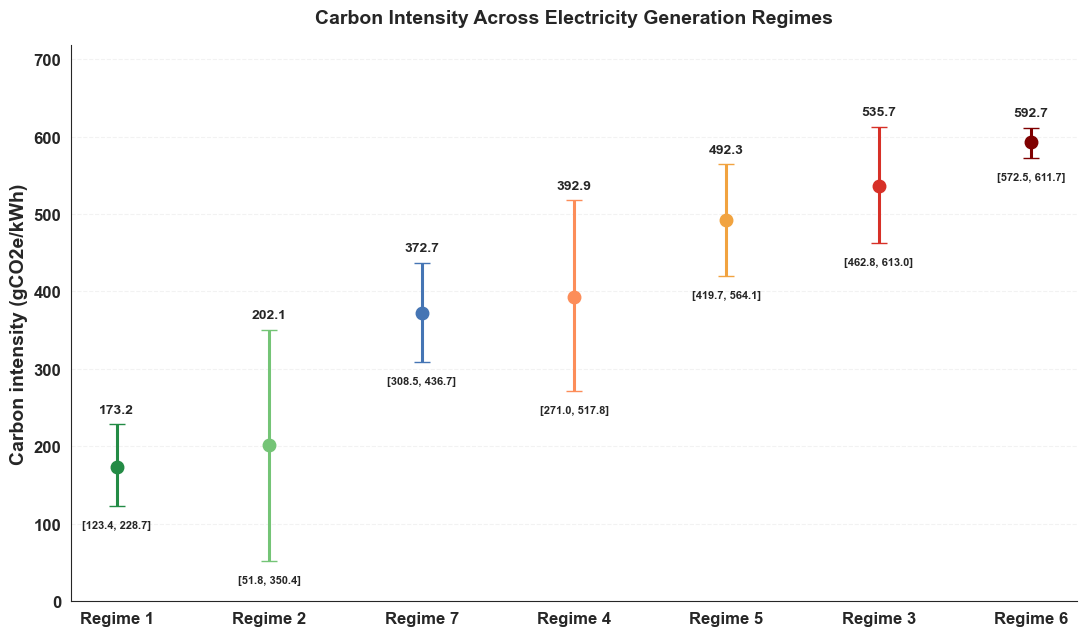

 Regime    Mean  CI_Lower  CI_Upper
      1 173.165   123.404   228.674
      2 202.113    51.815   350.366
      7 372.706   308.455   436.709
      4 392.928   270.963   517.818
      5 492.299   419.712   564.125
      3 535.675   462.756   613.001
      6 592.670   572.504   611.695


In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)
areas=d["Area"].dropna().unique()
regimes=sorted(d["Regime"].dropna().astype(int).unique())
B=2000
boot=np.full((B,len(regimes)),np.nan)
for b in range(B):
    sampled=np.random.choice(areas,len(areas),replace=True)
    z=pd.concat([d[d["Area"]==a] for a in sampled],ignore_index=True)
    means=z.groupby("Regime")["Carbon_Intensity"].mean()
    boot[b]=means.reindex(regimes).to_numpy()
profile=d.groupby("Regime").agg(N=("Carbon_Intensity","count"),Areas=("Area","nunique"),Mean=("Carbon_Intensity","mean")).reindex(regimes)
summary=pd.DataFrame({"Regime":regimes,"Mean":profile["Mean"].to_numpy(),"CI_Lower":np.nanpercentile(boot,2.5,axis=0),"CI_Upper":np.nanpercentile(boot,97.5,axis=0)})
summary=summary.sort_values("Mean").reset_index(drop=True)
colors={1:"#238B45",2:"#74C476",3:"#D73027",4:"#FC8D59",5:"#F1A340",6:"#7F0000",7:"#4575B4"}
plt.rcParams.update({"font.family":"Arial","font.size":11,"font.weight":"bold","axes.labelweight":"bold","axes.titleweight":"bold","figure.facecolor":"white","axes.facecolor":"white"})
fig,ax=plt.subplots(figsize=(11,6.5))
for pos,r in enumerate(summary["Regime"].astype(int)):
    z=summary.iloc[pos]
    ax.errorbar(pos,z["Mean"],yerr=[[z["Mean"]-z["CI_Lower"]],[z["CI_Upper"]-z["Mean"]]],fmt="o",color=colors[r],ecolor=colors[r],elinewidth=2.2,capsize=6,markersize=9)
    ax.text(pos,z["CI_Upper"]+15,f'{z["Mean"]:.1f}',ha="center",fontsize=10,fontweight="bold")
    ax.text(pos,z["CI_Lower"]-18,f'[{z["CI_Lower"]:.1f}, {z["CI_Upper"]:.1f}]',ha="center",va="top",fontsize=8,fontweight="bold")
ax.set_xticks(range(len(summary)),[f"Regime {int(r)}" for r in summary["Regime"]])
ax.set_ylabel("Carbon intensity (gCO2e/kWh)")
ax.set_title("Carbon Intensity Across Electricity Generation Regimes",fontsize=14,pad=16)
ax.grid(axis="y",linestyle="--",alpha=.25)
ax.spines[["top","right"]].set_visible(False)
ax.set_ylim(0,summary["CI_Upper"].max()+105)
plt.tight_layout()
plt.savefig("Figure_6_Carbon_Intensity_Bootstrap.png",dpi=900,bbox_inches="tight",facecolor="white")
plt.show()
print(summary.round(3).to_string(index=False))

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"font.family":"Arial","font.size":11,"font.weight":"bold","axes.labelweight":"bold","axes.titleweight":"bold","figure.facecolor":"white","axes.facecolor":"white"})
colors={1:"#238B45",2:"#74C476",3:"#D73027",4:"#FC8D59",5:"#F1A340",6:"#7F0000",7:"#4575B4"}
order=summary.sort_values("Mean")["Regime"].astype(int).tolist()

# 1. NUMERICAL RESULTS
profile=d.groupby("Regime").agg(
    N=("Carbon_Intensity","count"),
    Areas=("Area","nunique"),
    Mean=("Carbon_Intensity","mean"),
    Median=("Carbon_Intensity","median"),
    SD=("Carbon_Intensity","std")
).reset_index()
results=profile.merge(summary[["Regime","CI_Lower","CI_Upper"]],on="Regime")
results["Share_%"]=100*results["N"]/results["N"].sum()
results=results.sort_values("Mean")

print("\n"+"="*75+"\nREGIME CARBON INTENSITY AND BOOTSTRAP RESULTS\n"+"="*75)
print(results.round(3).to_string(index=False))
print(f"\nKruskal-Wallis H = {kw.statistic:.6f}")
print(f"Kruskal-Wallis p-value = {kw.pvalue:.6e}")
print(f"Total observations = {len(d)}")
print(f"Reporting units = {d['Area'].nunique()}")
print(f"Bootstrap replications = {len(boot)}")

# 2. PAIRWISE DIFFERENCES
pairs=[]
for i in sorted(means.index.astype(int)):
    for j in sorted(means.index.astype(int)):
        if j>i:
            pairs.append((i,j,means[i],means[j],means[i]-means[j]))
pair_df=pd.DataFrame(pairs,columns=["Regime_1","Regime_2","Mean_1","Mean_2","Difference"])
pair_df=pair_df.sort_values("Difference")

print("\n"+"="*75+"\nPAIRWISE REGIME MEAN DIFFERENCES\n"+"="*75)
print(pair_df.round(3).to_string(index=False))

# 3. FIGURE 1: MEANS AND BOOTSTRAP CONFIDENCE INTERVALS
fig,ax=plt.subplots(figsize=(12,7))
for pos,r in enumerate(order):
    z=results[results["Regime"]==r].iloc[0]
    c=colors[r]
    ax.errorbar(pos,z["Mean"],yerr=[[z["Mean"]-z["CI_Lower"]],[z["CI_Upper"]-z["Mean"]]],fmt="o",color=c,ecolor=c,elinewidth=2.5,capsize=7,markersize=11)
    ax.text(pos,z["CI_Upper"]+18,f'{z["Mean"]:.1f}',ha="center",color=c,fontsize=11,fontweight="bold")
    ax.text(pos,z["CI_Lower"]-22,f'[{z["CI_Lower"]:.1f}, {z["CI_Upper"]:.1f}]',ha="center",va="top",color=c,fontsize=8,fontweight="bold")
ax.set_xticks(range(len(order)),[f"Regime {r}" for r in order])
ax.set_ylabel("Carbon intensity (gCO₂e/kWh)")
ax.set_title("Carbon Intensity Across Electricity Generation Regimes",fontsize=15,pad=18)
ax.text(.02,.97,f"Kruskal–Wallis H={kw.statistic:.2f} | p={kw.pvalue:.2e}",transform=ax.transAxes,ha="left",va="top",color="#6A1B9A",bbox=dict(boxstyle="round,pad=.45",facecolor="#F3E5F5",edgecolor="#6A1B9A"))
ax.grid(axis="y",linestyle="--",alpha=.25)
ax.spines[["top","right"]].set_visible(False)
ax.set_ylim(0,results["CI_Upper"].max()+125)
plt.tight_layout()
plt.savefig("Figure_Regime_Carbon_Bootstrap_CI.png",dpi=900,bbox_inches="tight",facecolor="white")
plt.show()

# 4. FIGURE 2: PAIRWISE DIFFERENCES
fig,ax=plt.subplots(figsize=(12,10))
bar_colors=["#238B45" if x<0 else "#D73027" for x in pair_df["Difference"]]
bars=ax.barh(pair_df.apply(lambda x:f"R{int(x.Regime_1)} − R{int(x.Regime_2)}",axis=1),pair_df["Difference"],color=bar_colors,edgecolor="black",linewidth=.45)
for bar,val in zip(bars,pair_df["Difference"]):
    ax.text(val+(8 if val>=0 else -8),bar.get_y()+bar.get_height()/2,f"{val:+.1f}",ha="left" if val>=0 else "right",va="center",fontsize=9,fontweight="bold")
ax.axvline(0,color="black",linewidth=1)
ax.set_xlabel("Difference in mean carbon intensity (gCO₂e/kWh)")
ax.set_title("Pairwise Differences in Mean Carbon Intensity Between Regimes",fontsize=14,pad=15)
ax.grid(axis="x",linestyle="--",alpha=.25)
ax.spines[["top","right"]].set_visible(False)
ax.text(.02,.02,"Green: negative difference | Red: positive difference",transform=ax.transAxes,fontsize=10,fontweight="bold")
plt.tight_layout()
plt.savefig("Figure_Pairwise_Regime_Differences.png",dpi=900,bbox_inches="tight",facecolor="white")
plt.show()

# 5. EXPORT ALL NUMERICAL RESULTS
with pd.ExcelWriter("Regime_Carbon_Intensity_Results.xlsx") as writer:
    results.to_excel(writer,sheet_name="Regime_Profiles",index=False)
    pair_df.to_excel(writer,sheet_name="Pairwise_Differences",index=False)
    pd.DataFrame({"Statistic":["Kruskal-Wallis H","Kruskal-Wallis p-value","Observations","Reporting units","Bootstrap replications"],
                  "Value":[kw.statistic,kw.pvalue,len(d),d["Area"].nunique(),len(boot)]}).to_excel(writer,sheet_name="Statistical_Tests",index=False)

print("\nFILES SAVED:")
print("1. Figure_Regime_Carbon_Bootstrap_CI.png")
print("2. Figure_Pairwise_Regime_Differences.png")
print("3. Regime_Carbon_Intensity_Results.xlsx")

C:\Users\sadul\AppData\Local\Temp\ipykernel_30924\1631121760.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  profile=d.groupby("Regime").agg(



REGIME CARBON INTENSITY AND BOOTSTRAP RESULTS
 Regime   N  Areas    Mean  Median      SD  CI_Lower  CI_Upper  Share_%
      1 214     28 173.165 138.555 139.205   123.404   228.674   12.056
      2  56      7 202.113 114.364 178.917    51.815   350.366    3.155
      7 277     32 372.706 383.807 193.598   308.455   436.709   15.606
      4  77     10 392.928 366.860 182.834   270.963   517.818    4.338
      5 422     53 492.299 554.116 265.080   419.712   564.125   23.775
      3 330     42 535.675 582.087 240.923   462.756   613.001   18.592
      6 399     48 592.670 625.714  82.162   572.504   611.695   22.479


NameError: name 'kw' is not defined

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"font.family":"Arial","font.size":10,"font.weight":"bold","axes.labelweight":"bold","axes.titleweight":"bold","figure.facecolor":"white","axes.facecolor":"white"})

colors=["#238B45" if x>=.90 else "#F1A340" if x>=.75 else "#D73027" for x in stability["ARI_vs_Reference"]]

# 1. ARI STABILITY
fig,ax=plt.subplots(figsize=(12,6))
bars=ax.bar(stability["Seed"].astype(str),stability["ARI_vs_Reference"],color=colors,edgecolor="black",linewidth=.5)
for b,v in zip(bars,stability["ARI_vs_Reference"]):
    ax.text(b.get_x()+b.get_width()/2,v+.018,f"{v:.3f}",ha="center",fontsize=9,fontweight="bold")
ax.axhline(stability["ARI_vs_Reference"].mean(),color="#6A1B9A",linestyle="--",linewidth=2,label=f'Mean ARI = {stability["ARI_vs_Reference"].mean():.3f}')
ax.set_ylim(0,1.13)
ax.set_xlabel("Random seed")
ax.set_ylabel("Adjusted Rand Index")
ax.set_title("K=7 GMM: Classification Stability Across Random Seeds",fontsize=14,pad=15)
ax.legend(frameon=False)
ax.grid(axis="y",linestyle="--",alpha=.25)
ax.spines[["top","right"]].set_visible(False)
plt.tight_layout()
plt.savefig("Figure_GMM_Seed_ARI.png",dpi=900,bbox_inches="tight",facecolor="white")
plt.show()

# 2. BIC AND SILHOUETTE
fig,ax1=plt.subplots(figsize=(13,7))
x=np.arange(len(stability))
bars=ax1.bar(x,stability["BIC"],color="#4575B4",alpha=.85,edgecolor="black",linewidth=.4)
ax1.set_xticks(x,stability["Seed"].astype(str))
ax1.set_xlabel("Random seed")
ax1.set_ylabel("BIC",color="#1F4E79")
ax1.set_title("GMM Model Fit and Cluster Separation Across Random Seeds",fontsize=14,pad=15)
for b,v in zip(bars,stability["BIC"]):
    ax1.text(b.get_x()+b.get_width()/2,v+abs(stability["BIC"].min())*.002,f"{v:.0f}",ha="center",fontsize=8,color="#1F4E79",rotation=0)
ax2=ax1.twinx()
ax2.plot(x,stability["Silhouette"],color="#D73027",marker="o",linewidth=2.2,markersize=7)
ax2.set_ylabel("Silhouette score",color="#D73027")
for xx,v in zip(x,stability["Silhouette"]):
    ax2.annotate(f"{v:.3f}",(xx,v),xytext=(0,9),textcoords="offset points",ha="center",color="#D73027",fontsize=8,fontweight="bold")
ax1.grid(axis="y",linestyle="--",alpha=.2)
ax1.spines["top"].set_visible(False)
ax2.spines["top"].set_visible(False)
plt.tight_layout()
plt.savefig("Figure_GMM_BIC_Silhouette.png",dpi=900,bbox_inches="tight",facecolor="white")
plt.show()

# 3. MINIMUM CLUSTER SIZE AND ARI
fig,ax=plt.subplots(figsize=(12,7))
scatter=ax.scatter(stability["Min_Cluster_%"],stability["ARI_vs_Reference"],s=130,c=stability["Silhouette"],cmap="RdYlGn",edgecolors="black",linewidths=.6)
for _,r in stability.iterrows():
    ax.annotate(f'Seed {int(r["Seed"])}\nARI={r["ARI_vs_Reference"]:.3f}',(r["Min_Cluster_%"],r["ARI_vs_Reference"]),xytext=(5,7),textcoords="offset points",fontsize=8,fontweight="bold")
cb=plt.colorbar(scatter,ax=ax)
cb.set_label("Silhouette score")
ax.set_xlabel("Minimum cluster size (%)")
ax.set_ylabel("Adjusted Rand Index")
ax.set_title("Classification Stability, Cluster Size and Separation",fontsize=14,pad=15)
ax.grid(linestyle="--",alpha=.25)
ax.spines[["top","right"]].set_visible(False)
plt.tight_layout()
plt.savefig("Figure_GMM_Stability_Diagnostics.png",dpi=900,bbox_inches="tight",facecolor="white")
plt.show()

# 4. NUMERICAL SUMMARY AND EXPORT
print("\nSEED STABILITY NUMERICAL SUMMARY")
print(stability.round(4).to_string(index=False))
print("\nMEAN ARI:",round(stability["ARI_vs_Reference"].mean(),4))
print("MEDIAN ARI:",round(stability["ARI_vs_Reference"].median(),4))
print("SD ARI:",round(stability["ARI_vs_Reference"].std(),4))
print("MIN ARI:",round(stability["ARI_vs_Reference"].min(),4))
print("MAX ARI:",round(stability["ARI_vs_Reference"].max(),4))
print("CONVERGENCE:",f'{stability["Converged"].sum()}/{len(stability)}')
print("MEAN SILHOUETTE:",round(stability["Silhouette"].mean(),4))
print("MEAN MINIMUM CLUSTER SIZE (%):",round(stability["Min_Cluster_%"].mean(),4))

stability.to_excel("GMM_K7_Seed_Stability.xlsx",index=False)
print("\nALL FIGURES AND EXCEL RESULTS SAVED.")

NameError: name 'stability' is not defined

In [61]:
source_cols=[f"{p}_Mean" for p in parts]
profile["Dominant_Source"]=profile[source_cols].idxmax(axis=1).str.replace("_Mean","",regex=False)
profile["Dominant_Share"]=profile[source_cols].max(axis=1).round(2)

print("\nFINAL K=7 REGIME PROFILES")
print(profile.to_string())

print("\nCARBON INTENSITY DESCRIPTIVE TEST")
groups=[g["Carbon_Intensity"].dropna().values for _,g in d.groupby("Regime")]
print("Kruskal-Wallis H, p:",kruskal(*groups))

annual=pd.crosstab(d["Year"],d["Regime"],normalize="index").mul(100).round(2)
print("\nANNUAL REGIME DISTRIBUTION (%)")
print(annual.to_string())

profile.to_excel("Final_K7_Regime_Profiles.xlsx")
annual.to_excel("Final_K7_Annual_Regime_Distribution.xlsx")


FINAL K=7 REGIME PROFILES
          N  Areas  Carbon_Mean  Carbon_Median  Carbon_SD  Solar_Mean  Wind_Mean  Hydro_Mean  Bioenergy_Mean  Other renewables_Mean  Nuclear_Mean  Coal_Mean  Gas_Mean  Other fossil_Mean    N_% Dominant_Source  Dominant_Share
Regime                                                                                                                                                                                                                          
1       214     28      173.165        138.555    139.205       1.733      0.000      74.014           4.364                  0.000         0.000      6.292     0.000             13.597  12.06           Hydro           74.01
2        56      7      202.113        114.364    178.917       1.928      7.194      42.442           4.611                 17.589         0.000      0.055     3.020             23.161   3.15           Hydro           42.44
3       330     42      535.675        582.087    240.923       1.427    

In [31]:
import pandas as pd
d=d.sort_values(["Area","Year"]).copy()
d["Next_Year"]=d.groupby("Area")["Year"].shift(-1)
d["Next_Regime"]=d.groupby("Area")["Regime"].shift(-1)
tr=d[d["Next_Year"]==d["Year"]+1].dropna(subset=["Next_Regime"]).copy()
tr["Next_Regime"]=tr["Next_Regime"].astype(int)
counts=pd.crosstab(tr["Regime"],tr["Next_Regime"]).reindex(index=range(1,8),columns=range(1,8),fill_value=0)
probs=counts.div(counts.sum(axis=1),axis=0).mul(100).round(2)
switch=tr[tr["Regime"]!=tr["Next_Regime"]]
unit_switch=tr.groupby("Area").apply(lambda x:(x["Regime"]!=x["Next_Regime"]).any(),include_groups=False)
print("CONSECUTIVE TRANSITIONS:",len(tr))
print("\nTRANSITION COUNTS\n",counts)
print("\nTRANSITION PROBABILITIES (%)\n",probs)
print("\nTOTAL SWITCHES:",len(switch))
print("SWITCH RATE (%):",round(100*len(switch)/len(tr),2))
print("UNITS WITH AT LEAST ONE SWITCH:",int(unit_switch.sum()))
print("UNITS WITHOUT SWITCH:",int((~unit_switch).sum()))
print("\nSWITCHES BY ORIGIN REGIME\n",switch["Regime"].value_counts().sort_index())
print("\nSWITCHES BY DESTINATION REGIME\n",switch["Next_Regime"].value_counts().sort_index())

CONSECUTIVE TRANSITIONS: 1575

TRANSITION COUNTS
 Next_Regime    1   2    3   4    5    6    7
Regime                                      
1            186   0    1   0    2    1    0
2              0  49    0   0    0    0    0
3              0   0  288   0    4    0    1
4              0   0    0  67    1    0    0
5              0   2    3   2  366    0    1
6              2   0    2   0    0  351    0
7              0   0    0   1    0    0  245

TRANSITION PROBABILITIES (%)
 Next_Regime      1       2      3      4      5      6      7
Regime                                                       
1            97.89    0.00   0.53   0.00   1.05   0.53   0.00
2             0.00  100.00   0.00   0.00   0.00   0.00   0.00
3             0.00    0.00  98.29   0.00   1.37   0.00   0.34
4             0.00    0.00   0.00  98.53   1.47   0.00   0.00
5             0.00    0.53   0.80   0.53  97.86   0.00   0.27
6             0.56    0.00   0.56   0.00   0.00  98.87   0.00
7             0.00

In [32]:
unit_stats=d.groupby("Area").agg(
    N_Years=("Year","nunique"),
    N_Regimes=("Regime","nunique"),
    First_Year=("Year","min"),
    Last_Year=("Year","max")
)
unit_stats["Regime_Changes"]=d.groupby("Area")["Regime"].apply(lambda x:(x!=x.shift()).sum()-1)
unit_stats["Stable"]=unit_stats["N_Regimes"].eq(1)
unit_stats["Observed_Years_%"]=(100*unit_stats["N_Years"]/9).round(2)

print("UNIT-LEVEL REGIME STABILITY")
print(unit_stats["N_Regimes"].value_counts().sort_index().to_string())
print("\nSTABLE UNITS:",unit_stats["Stable"].sum())
print("CHANGING UNITS:",(~unit_stats["Stable"]).sum())
print("\nREGIME CHANGE DISTRIBUTION")
print(unit_stats["Regime_Changes"].value_counts().sort_index().to_string())
print("\nUNITS WITH REGIME CHANGES")
print(unit_stats[~unit_stats["Stable"]].sort_values("Regime_Changes",ascending=False).to_string())

unit_stats.to_excel("K7_Unit_Level_Regime_Stability.xlsx")

UNIT-LEVEL REGIME STABILITY
N_Regimes
1    179
2     19
3      1

STABLE UNITS: 179
CHANGING UNITS: 20

REGIME CHANGE DISTRIBUTION
Regime_Changes
0    179
1     18
2      1
3      1

UNITS WITH REGIME CHANGES
                      N_Years  N_Regimes  First_Year  Last_Year  Regime_Changes  Stable  Observed_Years_%
Area                                                                                                     
Ethiopia                    9          3        2016       2024               3   False             100.0
Croatia                     9          2        2016       2024               2   False             100.0
Angola                      9          2        2016       2024               1   False             100.0
Belarus                     9          2        2016       2024               1   False             100.0
Brunei Darussalam           9          2        2016       2024               1   False             100.0
Bolivia                     9          2        2

In [33]:
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor, GradientBoostingRegressor, AdaBoostRegressor, RandomForestRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import Ridge, ElasticNet
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from catboost import CatBoostRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

X=np.asarray(X)
y=np.log1p(d["Carbon_Intensity"].to_numpy())
groups=d["Area"].to_numpy()
cv=GroupKFold(n_splits=5)

models={
    "Dummy":DummyRegressor(strategy="mean"),
    "Ridge":make_pipeline(StandardScaler(),Ridge(alpha=10)),
    "ElasticNet":make_pipeline(StandardScaler(),ElasticNet(alpha=0.001,l1_ratio=0.5,max_iter=10000)),
    "SVR-RBF":make_pipeline(StandardScaler(),SVR(C=10,epsilon=0.05)),
    "KNN":make_pipeline(StandardScaler(),KNeighborsRegressor(n_neighbors=7,weights="distance")),
    "Random Forest":RandomForestRegressor(n_estimators=500,min_samples_leaf=3,max_features=0.8,n_jobs=-1,random_state=42),
    "Extra Trees":ExtraTreesRegressor(n_estimators=500,min_samples_leaf=3,max_features=0.8,n_jobs=-1,random_state=42),
    "Gradient Boosting":GradientBoostingRegressor(n_estimators=300,learning_rate=0.03,max_depth=3,loss="huber",random_state=42),
    "Hist Gradient Boosting":HistGradientBoostingRegressor(max_iter=300,max_leaf_nodes=15,l2_regularization=1,random_state=42),
    "AdaBoost":AdaBoostRegressor(n_estimators=300,learning_rate=0.03,loss="linear",random_state=42),
    "CatBoost":CatBoostRegressor(iterations=700,depth=6,learning_rate=0.03,l2_leaf_reg=5,loss_function="RMSE",verbose=False,thread_count=1,random_seed=42),
    "XGBoost":XGBRegressor(n_estimators=700,max_depth=4,learning_rate=0.03,subsample=0.8,colsample_bytree=0.8,reg_lambda=5,objective="reg:squarederror",n_jobs=1,random_state=42),
    "LightGBM":LGBMRegressor(n_estimators=700,max_depth=5,num_leaves=15,learning_rate=0.03,subsample=0.8,colsample_bytree=0.8,reg_lambda=5,verbosity=-1,n_jobs=1,random_state=42)
}

splits=list(cv.split(X,y,groups))
results=[]
oof_predictions={}

for name,model in models.items():
    pred=np.full(len(y),np.nan)
    for train_idx,test_idx in splits:
        fitted=clone(model)
        fitted.fit(X[train_idx],y[train_idx])
        pred[test_idx]=fitted.predict(X[test_idx])
    oof_predictions[name]=pred
    pred_raw=np.expm1(pred)
    y_raw=np.expm1(y)
    results.append({
        "Model":name,
        "R2_Log":r2_score(y,pred),
        "MAE_Log":mean_absolute_error(y,pred),
        "RMSE_Log":np.sqrt(mean_squared_error(y,pred)),
        "R2_Raw":r2_score(y_raw,pred_raw),
        "MAE_Raw":mean_absolute_error(y_raw,pred_raw),
        "RMSE_Raw":np.sqrt(mean_squared_error(y_raw,pred_raw))
    })

performance=pd.DataFrame(results).sort_values("R2_Log",ascending=False).reset_index(drop=True)
print("\nGROUPED 5-FOLD OUT-OF-FOLD MODEL COMPARISON")
print(performance.round(4).to_string(index=False))
performance.to_excel("K7_Advanced_Algorithm_Comparison.xlsx",index=False)
pd.DataFrame(oof_predictions).to_excel("K7_OOF_Predictions.xlsx",index=False)

C:\Users\sadul\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
C:\Users\sadul\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
C:\Users\sadul\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
C:\Users\sadul\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
C:\Users\sadul\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(



GROUPED 5-FOLD OUT-OF-FOLD MODEL COMPARISON
                 Model  R2_Log  MAE_Log  RMSE_Log  R2_Raw  MAE_Raw  RMSE_Raw
              LightGBM  0.9389   0.1291    0.2210  0.8613  46.9176   89.8012
           Extra Trees  0.9366   0.1242    0.2251  0.8920  43.4390   79.2371
              CatBoost  0.9354   0.1274    0.2272  0.8871  43.4178   81.0231
               SVR-RBF  0.9348   0.1246    0.2283  0.8774  46.6461   84.4297
               XGBoost  0.9304   0.1321    0.2358  0.8773  45.8145   84.4621
Hist Gradient Boosting  0.9278   0.1358    0.2402  0.8603  47.4933   90.0995
     Gradient Boosting  0.9038   0.1515    0.2773  0.8746  48.5769   85.3790
         Random Forest  0.8964   0.1577    0.2878  0.8683  50.6995   87.4987
                   KNN  0.8419   0.2033    0.3554  0.8196  65.0412  102.4153
            ElasticNet  0.8371   0.2745    0.3608  0.3515 117.7754  194.1489
                 Ridge  0.8364   0.2742    0.3616  0.3814 115.7971  189.6237
              AdaBoost  0.8139 

In [34]:
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.model_selection import GroupKFold
from sklearn.metrics import mean_squared_error

X=np.asarray(X)
y=np.log1p(d["Carbon_Intensity"].to_numpy())
groups=d["Area"].to_numpy()
parts=["Solar","Wind","Hydro","Bioenergy","Other renewables","Nuclear","Coal","Gas","Other fossil"]
cv=GroupKFold(n_splits=5)
splits=list(cv.split(X,y,groups))
top_models={k:clone(models[k]) for k in ["Extra Trees","CatBoost","LightGBM"]}
importance=[]

for name,model in top_models.items():
    for fold,(tr,te) in enumerate(splits,1):
        fitted=clone(model).fit(X[tr],y[tr])
        pi=permutation_importance(fitted,X[te],y[te],scoring="neg_root_mean_squared_error",n_repeats=30,random_state=42,n_jobs=-1)
        for j,part in enumerate(parts):
            importance.append({"Model":name,"Fold":fold,"Source":part,"Importance":pi.importances_mean[j],"SD":pi.importances_std[j]})

imp=pd.DataFrame(importance)
summary=imp.groupby(["Model","Source"]).agg(Mean_Importance=("Importance","mean"),SD=("Importance","std")).reset_index()
summary["Mean_Importance"]=summary["Mean_Importance"].clip(lower=0)
summary["Importance_%"]=summary.groupby("Model")["Mean_Importance"].transform(lambda x:100*x/x.sum())
summary=summary.sort_values(["Model","Importance_%"],ascending=[True,False])
print(summary.round(4).to_string(index=False))
summary.to_excel("K7_Top3_GroupCV_Permutation_Importance.xlsx",index=False)

C:\Users\sadul\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
C:\Users\sadul\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
C:\Users\sadul\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
C:\Users\sadul\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
C:\Users\sadul\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


      Model           Source  Mean_Importance     SD  Importance_%
   CatBoost            Hydro           0.6432 0.1492       45.8579
   CatBoost             Coal           0.2301 0.0426       16.4026
   CatBoost     Other fossil           0.1598 0.0579       11.3908
   CatBoost              Gas           0.1090 0.0377        7.7736
   CatBoost          Nuclear           0.0975 0.0315        6.9490
   CatBoost             Wind           0.0685 0.0223        4.8854
   CatBoost        Bioenergy           0.0552 0.0166        3.9359
   CatBoost            Solar           0.0276 0.0235        1.9669
   CatBoost Other renewables           0.0118 0.0116        0.8379
Extra Trees            Hydro           0.6584 0.1512       47.9749
Extra Trees             Coal           0.2048 0.0359       14.9247
Extra Trees     Other fossil           0.1667 0.0397       12.1503
Extra Trees              Gas           0.1274 0.0238        9.2846
Extra Trees          Nuclear           0.0842 0.0281        6.

In [35]:
import pandas as pd
from scipy.stats import spearmanr
parts=["Solar","Wind","Hydro","Bioenergy","Other renewables","Nuclear","Coal","Gas","Other fossil"]
fold_imp=imp.pivot_table(index=["Model","Fold"],columns="Source",values="Importance")
ranks=fold_imp.rank(axis=1,ascending=False,method="average")
print("FOLD-LEVEL HYDRO RANK")
print(ranks["Hydro"].groupby("Model").agg(["mean","min","max"]).to_string())
print("\nFOLD-LEVEL TOP FEATURE FREQUENCY")
for model in ranks.index.get_level_values("Model").unique():
    z=ranks.loc[model]
    print(model,":",int((z.idxmin(axis=1)=="Hydro").sum()),"/",len(z))
print("\nCROSS-MODEL RANK CORRELATIONS")
for a,b in [("CatBoost","Extra Trees"),("CatBoost","LightGBM"),("Extra Trees","LightGBM")]:
    ra=ranks.loc[a].mean()
    rb=ranks.loc[b].mean()
    print(a,"vs",b,":",round(spearmanr(ra,rb).statistic,4))

FOLD-LEVEL HYDRO RANK
             mean  min  max
Model                      
CatBoost      1.0  1.0  1.0
Extra Trees   1.0  1.0  1.0
LightGBM      1.0  1.0  1.0

FOLD-LEVEL TOP FEATURE FREQUENCY
CatBoost : 5 / 5
Extra Trees : 5 / 5
LightGBM : 5 / 5

CROSS-MODEL RANK CORRELATIONS
CatBoost vs Extra Trees : 0.9958
CatBoost vs LightGBM : 0.9958
Extra Trees vs LightGBM : 1.0


In [36]:
import numpy as np
import pandas as pd
import shap
from sklearn.base import clone
from sklearn.model_selection import GroupKFold

parts=["Solar","Wind","Hydro","Bioenergy","Other renewables","Nuclear","Coal","Gas","Other fossil"]
X=np.asarray(X)
y=np.log1p(d["Carbon_Intensity"].to_numpy())
groups=d["Area"].to_numpy()
cv=GroupKFold(n_splits=5)
splits=list(cv.split(X,y,groups))
shap_results={}

for name in ["Extra Trees","CatBoost","LightGBM"]:
    values=np.zeros((len(y),X.shape[1]))
    for train_idx,test_idx in splits:
        model=clone(models[name]).fit(X[train_idx],y[train_idx])
        explainer=shap.TreeExplainer(model)
        sv=explainer.shap_values(X[test_idx],check_additivity=False)
        if isinstance(sv,list): sv=sv[0]
        values[test_idx]=np.asarray(sv).reshape(len(test_idx),-1)
    shap_results[name]=values

rows=[]
for name,values in shap_results.items():
    for j,part in enumerate(parts):
        rows.append({
            "Model":name,
            "Source":part,
            "Mean_Abs_SHAP":np.abs(values[:,j]).mean(),
            "Mean_SHAP":values[:,j].mean(),
            "SD_SHAP":values[:,j].std()
        })

shap_summary=pd.DataFrame(rows)
shap_summary["Importance_%"]=shap_summary.groupby("Model")["Mean_Abs_SHAP"].transform(lambda x:100*x/x.sum())
shap_summary=shap_summary.sort_values(["Model","Importance_%"],ascending=[True,False])

print("\nOUT-OF-FOLD SHAP RESULTS")
print(shap_summary.round(4).to_string(index=False))
shap_summary.to_excel("K7_GroupCV_OOF_SHAP_Summary.xlsx",index=False)

for name,values in shap_results.items():
    pd.DataFrame(values,columns=parts).assign(Area=d["Area"].values,Year=d["Year"].values).to_excel(f"K7_{name.replace(' ','_')}_OOF_SHAP.xlsx",index=False)


OUT-OF-FOLD SHAP RESULTS
      Model           Source  Mean_Abs_SHAP  Mean_SHAP  SD_SHAP  Importance_%
   CatBoost            Hydro         0.4300     0.0462   0.5352       39.1023
   CatBoost             Coal         0.1699    -0.0058   0.2072       15.4506
   CatBoost     Other fossil         0.1371    -0.0204   0.1713       12.4646
   CatBoost              Gas         0.0911    -0.0062   0.1135        8.2810
   CatBoost             Wind         0.0735    -0.0015   0.1105        6.6852
   CatBoost          Nuclear         0.0654    -0.0004   0.1274        5.9475
   CatBoost        Bioenergy         0.0611    -0.0044   0.0841        5.5545
   CatBoost            Solar         0.0429    -0.0005   0.0624        3.9011
   CatBoost Other renewables         0.0287     0.0024   0.0642        2.6130
Extra Trees            Hydro         0.4449    -0.0303   0.6143       42.7834
Extra Trees             Coal         0.1325    -0.0161   0.1615       12.7392
Extra Trees     Other fossil         0

In [37]:
import numpy as np
import pandas as pd

for name,values in shap_results.items():
    z=pd.DataFrame({"Hydro_Share":np.asarray(X)[:,2]**2*100,"Hydro_SHAP":values[:,2]})
    z["Hydro_Group"]=pd.qcut(z["Hydro_Share"],5,duplicates="drop")
    print("\n",name)
    print(z.groupby("Hydro_Group",observed=True).agg(
        N=("Hydro_SHAP","size"),
        Hydro_Mean=("Hydro_Share","mean"),
        SHAP_Mean=("Hydro_SHAP","mean"),
        SHAP_Abs=("Hydro_SHAP",lambda x:np.abs(x).mean())
    ).round(4).to_string())


 Extra Trees
                    N  Hydro_Mean  SHAP_Mean  SHAP_Abs
Hydro_Group                                           
(-0.001, 4.011]   710      0.4632     0.3778    0.3778
(4.011, 18.993]   355     10.0924     0.2463    0.2463
(18.993, 53.585]  355     33.4890    -0.0574    0.1265
(53.585, 100.0]   355     77.3255    -1.0959    1.0959

 CatBoost
                    N  Hydro_Mean  SHAP_Mean  SHAP_Abs
Hydro_Group                                           
(-0.001, 4.011]   710      0.4632     0.4129    0.4129
(4.011, 18.993]   355     10.0924     0.2906    0.2906
(18.993, 53.585]  355     33.4890     0.0146    0.1334
(53.585, 100.0]   355     77.3255    -0.9001    0.9001

 LightGBM
                    N  Hydro_Mean  SHAP_Mean  SHAP_Abs
Hydro_Group                                           
(-0.001, 4.011]   710      0.4632     0.3488    0.3488
(4.011, 18.993]   355     10.0924     0.2514    0.2514
(18.993, 53.585]  355     33.4890    -0.0185    0.1172
(53.585, 100.0]   355     77.


Extra Trees
      Hydro_Group   N  Hydro_Mean  SHAP_Mean  SHAP_Abs
 (-0.001, 4.011] 710      0.4632     0.3778    0.3778
 (4.011, 18.993] 355     10.0924     0.2463    0.2463
(18.993, 53.585] 355     33.4890    -0.0574    0.1265
 (53.585, 100.0] 355     77.3255    -1.0959    1.0959

CatBoost
      Hydro_Group   N  Hydro_Mean  SHAP_Mean  SHAP_Abs
 (-0.001, 4.011] 710      0.4632     0.4129    0.4129
 (4.011, 18.993] 355     10.0924     0.2906    0.2906
(18.993, 53.585] 355     33.4890     0.0146    0.1334
 (53.585, 100.0] 355     77.3255    -0.9001    0.9001

LightGBM
      Hydro_Group   N  Hydro_Mean  SHAP_Mean  SHAP_Abs
 (-0.001, 4.011] 710      0.4632     0.3488    0.3488
 (4.011, 18.993] 355     10.0924     0.2514    0.2514
(18.993, 53.585] 355     33.4890    -0.0185    0.1172
 (53.585, 100.0] 355     77.3255    -1.0734    1.0734


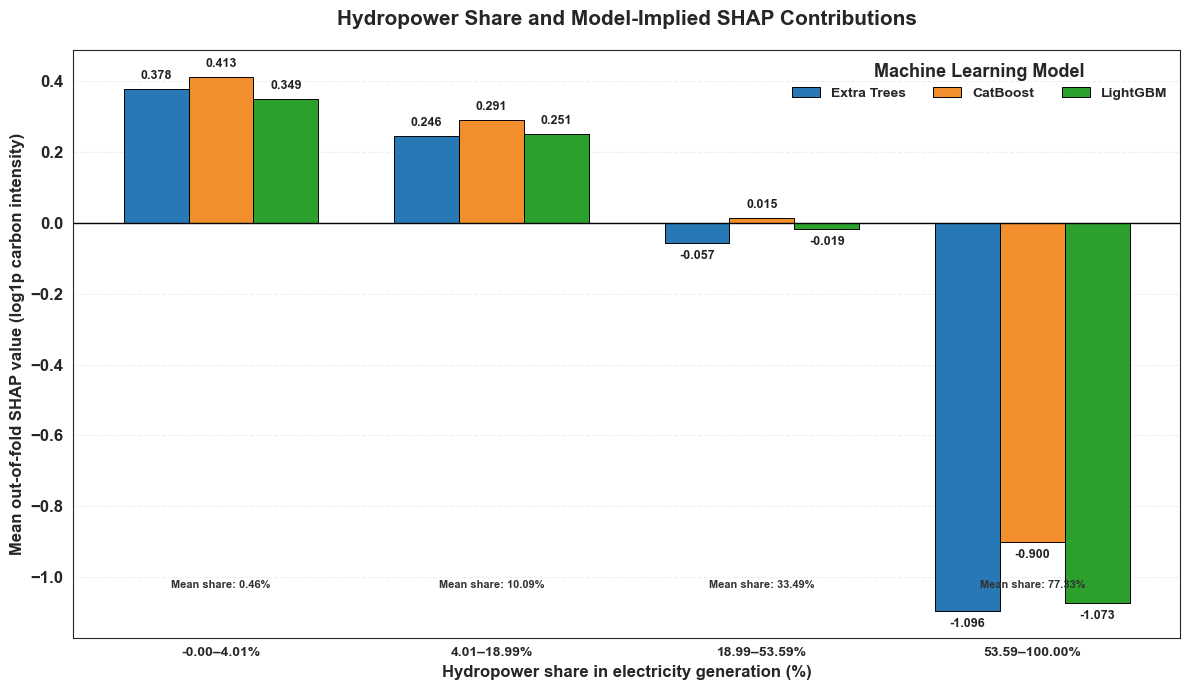

In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

parts=["Solar","Wind","Hydro","Bioenergy","Other renewables","Nuclear","Coal","Gas","Other fossil"]
results={}
for name,values in shap_results.items():
    z=pd.DataFrame({"Hydro_Share":np.asarray(X)[:,2]**2*100,"Hydro_SHAP":values[:,2]})
    z["Hydro_Group"]=pd.qcut(z["Hydro_Share"],5,duplicates="drop")
    tab=z.groupby("Hydro_Group",observed=True).agg(
        N=("Hydro_SHAP","size"),
        Hydro_Mean=("Hydro_Share","mean"),
        SHAP_Mean=("Hydro_SHAP","mean"),
        SHAP_Abs=("Hydro_SHAP",lambda x:np.abs(x).mean())
    ).reset_index()
    results[name]=tab
    print(f"\n{name}\n",tab.round(4).to_string(index=False))

models=["Extra Trees","CatBoost","LightGBM"]
colors=["#2878B5","#F28E2B","#2CA02C"]
labels=[f"{a.left:.2f}–{a.right:.2f}%" for a in results[models[0]]["Hydro_Group"]]
x=np.arange(len(labels))
width=0.24
fig,ax=plt.subplots(figsize=(12,7))

for i,(name,color) in enumerate(zip(models,colors)):
    vals=results[name]["SHAP_Mean"].to_numpy()
    bars=ax.bar(x+(i-1)*width,vals,width,label=name,color=color,edgecolor="black",linewidth=.7)
    for bar,v in zip(bars,vals):
        ax.annotate(f"{v:.3f}",(bar.get_x()+bar.get_width()/2,v),
                    xytext=(0,5 if v>=0 else -5),textcoords="offset points",
                    ha="center",va="bottom" if v>=0 else "top",
                    fontsize=9,fontweight="bold",color="#222222")

ax.axhline(0,color="black",linewidth=1)
ax.set_xticks(x)
ax.set_xticklabels(labels,fontsize=10,fontweight="bold")
ax.set_xlabel("Hydropower share in electricity generation (%)",fontsize=12,fontweight="bold")
ax.set_ylabel("Mean out-of-fold SHAP value (log1p carbon intensity)",fontsize=12,fontweight="bold")
ax.set_title("Hydropower Share and Model-Implied SHAP Contributions",
             fontsize=15,fontweight="bold",pad=18)
ax.legend(title="Machine Learning Model",frameon=False,ncol=3,fontsize=10)
ax.grid(axis="y",linestyle="--",alpha=.3)
ax.set_axisbelow(True)

for i,row in results[models[0]].iterrows():
    ax.text(i,ax.get_ylim()[0]*.88 if ax.get_ylim()[0]<0 else 0,
            f"Mean share: {row['Hydro_Mean']:.2f}%",
            ha="center",fontsize=8,color="#333333")

fig.tight_layout()
plt.savefig("Hydropower_SHAP_Comparison.png",dpi=900,bbox_inches="tight",facecolor="white")
plt.show()

In [ ]:

import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations
from scipy.stats import spearmanr
from sklearn.ensemble import ExtraTreesRegressor
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor

parts=["Solar","Wind","Hydro","Bioenergy","Other renewables","Nuclear","Coal","Gas","Other fossil"]
models_to_run={
    "Extra Trees":ExtraTreesRegressor(n_estimators=300,min_samples_leaf=1,max_features=1.0,n_jobs=-1,random_state=42),
    "CatBoost":CatBoostRegressor(iterations=500,depth=6,learning_rate=0.05,loss_function="RMSE",verbose=False,random_seed=42,allow_writing_files=False),
    "LightGBM":LGBMRegressor(n_estimators=500,learning_rate=0.05,num_leaves=31,verbosity=-1,n_jobs=-1,random_state=42)
}
colors={"Extra Trees":"#3498DB","CatBoost":"#FF9F43","LightGBM":"#2ECC71"}

X=np.asarray(X)
y=np.asarray(y)
assert X.shape==(len(y),9)
assert len(splits)>0

# OOF SHAP INTERACTION
interaction_results={}
for name,estimator in models_to_run.items():
    all_values=np.zeros((len(y),9,9))
    for train_idx,test_idx in splits:
        model=estimator.__class__(**estimator.get_params()).fit(X[train_idx],y[train_idx])
        explainer=shap.TreeExplainer(model,feature_perturbation="tree_path_dependent")
        values=explainer.shap_interaction_values(X[test_idx])
        if isinstance(values,list): values=values[0]
        values=np.asarray(values)
        if values.shape!=(len(test_idx),9,9):
            raise ValueError(f"{name}: SHAP boyutu beklenenden farklı: {values.shape}")
        all_values[test_idx]=values
    interaction_results[name]=all_values
    print(name,"OOF SHAP interaction tamamlandı.")

# ETKILESIM TABLOSU
rows=[]
for name,values in interaction_results.items():
    for i,j in combinations(range(9),2):
        v=values[:,i,j]
        rows.append({"Model":name,"Feature_1":parts[i],"Feature_2":parts[j],
                     "Interaction":f"{parts[i]} × {parts[j]}",
                     "Mean_Abs_Interaction":np.abs(v).mean(),
                     "Mean_Interaction":v.mean(),"SD_Interaction":v.std()})
interaction_df=pd.DataFrame(rows)
interaction_df["Importance_%"]=interaction_df.groupby("Model")["Mean_Abs_Interaction"].transform(
    lambda x:100*x/x.sum() if x.sum()>0 else 0)
interaction_df["Rank"]=interaction_df.groupby("Model")["Mean_Abs_Interaction"].rank(
    ascending=False,method="min").astype(int)

# TOP 10
for name in models_to_run:
    print(f"\n{name} — TOP 10")
    print(interaction_df[interaction_df["Model"]==name].nsmallest(10,"Rank")[
        ["Interaction","Mean_Abs_Interaction","Mean_Interaction","Importance_%","Rank"]
    ].round(4).to_string(index=False))

# HYDRO ETKILESIMLERI
hydro_df=interaction_df[
    (interaction_df["Feature_1"]=="Hydro")|(interaction_df["Feature_2"]=="Hydro")
].copy()
print("\nHYDRO ETKİLEŞİMLERİ")
print(hydro_df.sort_values(["Model","Rank"])[
    ["Model","Interaction","Mean_Abs_Interaction","Mean_Interaction","Importance_%","Rank"]
].round(4).to_string(index=False))

# MODELLER ARASI SIRALAMA UYUMU
rank_table=interaction_df.pivot(index="Interaction",columns="Model",values="Rank")
print("\nSPEARMAN SIRALAMA KORELASYONLARI")
for a,b in combinations(models_to_run,2):
    rho,p=spearmanr(rank_table[a],rank_table[b])
    print(f"{a} – {b}: rho={rho:.4f}, p={p:.4g}")

# GRAFIK 1: TOP 10
fig,axes=plt.subplots(1,3,figsize=(21,9))
for ax,name in zip(axes,models_to_run):
    temp=interaction_df[interaction_df["Model"]==name].nlargest(10,"Mean_Abs_Interaction").sort_values("Mean_Abs_Interaction")
    bars=ax.barh(temp["Interaction"],temp["Mean_Abs_Interaction"],color=colors[name],edgecolor="black")
    for bar,val in zip(bars,temp["Mean_Abs_Interaction"]):
        ax.text(val,bar.get_y()+bar.get_height()/2,f" {val:.3f}",va="center",fontsize=9,fontweight="bold")
    ax.set_title(name,fontsize=14,fontweight="bold")
    ax.set_xlabel("Mean |SHAP interaction|")
    ax.grid(axis="x",alpha=.25)
    ax.set_axisbelow(True)
fig.suptitle("Top 10 Pairwise SHAP Interactions",fontsize=17,fontweight="bold")
plt.tight_layout()
plt.savefig("SHAP_Interaction_Top10.png",dpi=900,bbox_inches="tight",facecolor="white")
plt.show()

# GRAFIK 2: HYDRO
fig,axes=plt.subplots(1,3,figsize=(20,8))
for ax,name in zip(axes,models_to_run):
    temp=hydro_df[hydro_df["Model"]==name].sort_values("Mean_Abs_Interaction")
    bars=ax.barh(temp["Interaction"],temp["Mean_Abs_Interaction"],color=colors[name],edgecolor="black")
    for bar,val in zip(bars,temp["Mean_Abs_Interaction"]):
        ax.text(val,bar.get_y()+bar.get_height()/2,f" {val:.3f}",va="center",fontsize=9,fontweight="bold")
    ax.set_title(name,fontsize=14,fontweight="bold")
    ax.set_xlabel("Mean |SHAP interaction|")
    ax.grid(axis="x",alpha=.25)
    ax.set_axisbelow(True)
fig.suptitle("Hydropower-Based SHAP Interactions",fontsize=17,fontweight="bold")
plt.tight_layout()
plt.savefig("SHAP_Hydro_Interactions.png",dpi=900,bbox_inches="tight",facecolor="white")
plt.show()

# GRAFIK 3: ISI HARITASI
fig,axes=plt.subplots(1,3,figsize=(22,8))
for ax,name in zip(axes,models_to_run):
    matrix=np.zeros((9,9))
    for _,r in interaction_df[interaction_df["Model"]==name].iterrows():
        i,j=parts.index(r["Feature_1"]),parts.index(r["Feature_2"])
        matrix[i,j]=matrix[j,i]=r["Mean_Abs_Interaction"]
    sns.heatmap(matrix,xticklabels=parts,yticklabels=parts,cmap="YlOrRd",
                annot=True,fmt=".3f",linewidths=.5,square=True,ax=ax,cbar=False,
                annot_kws={"size":7,"weight":"bold"})
    ax.set_title(name,fontsize=14,fontweight="bold")
    ax.tick_params(axis="x",rotation=70,labelsize=8)
    ax.tick_params(axis="y",rotation=0,labelsize=8)
fig.suptitle("Pairwise SHAP Interaction Importance",fontsize=17,fontweight="bold")
plt.tight_layout()
plt.savefig("SHAP_Interaction_Heatmaps.png",dpi=900,bbox_inches="tight",facecolor="white")
plt.show()

# EXCEL
with pd.ExcelWriter("K7_GroupCV_SHAP_Interaction_Results.xlsx") as writer:
    interaction_df.sort_values(["Model","Rank"]).to_excel(writer,sheet_name="All_Interactions",index=False)
    hydro_df.sort_values(["Model","Rank"]).to_excel(writer,sheet_name="Hydro_Interactions",index=False)
    rank_table.to_excel(writer,sheet_name="Model_Rank_Comparison")
    for name in models_to_run:
        interaction_df[interaction_df["Model"]==name].nsmallest(10,"Rank").to_excel(
            writer,sheet_name=name.replace(" ","_")+"_Top10",index=False)

print("\nANALİZ TAMAMLANDI.")


In [ ]:
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations
from scipy.stats import spearmanr
from sklearn.ensemble import ExtraTreesRegressor

parts=["Solar","Wind","Hydro","Bioenergy","Other renewables","Nuclear","Coal","Gas","Other fossil"]

model=ExtraTreesRegressor(
    n_estimators=300,min_samples_leaf=1,max_features=1.0,
    n_jobs=-1,random_state=42
)
color="#3498DB"

X=np.asarray(X)
y=np.asarray(y)
assert X.shape==(len(y),9)
assert len(splits)>0

# OOF SHAP INTERACTION
all_values=np.zeros((len(y),9,9))

for train_idx,test_idx in splits:
    estimator=ExtraTreesRegressor(**model.get_params())
    estimator.fit(X[train_idx],y[train_idx])
    explainer=shap.TreeExplainer(
        estimator,feature_perturbation="tree_path_dependent"
    )
    values=explainer.shap_interaction_values(X[test_idx])
    if isinstance(values,list):
        values=values[0]
    values=np.asarray(values)
    if values.shape!=(len(test_idx),9,9):
        raise ValueError(f"SHAP boyutu beklenenden farklı: {values.shape}")
    all_values[test_idx]=values

print("Extra Trees OOF SHAP interaction tamamlandı.")

# ETKILESIM TABLOSU
rows=[]
for i,j in combinations(range(9),2):
    v=all_values[:,i,j]
    rows.append({
        "Feature_1":parts[i],
        "Feature_2":parts[j],
        "Interaction":f"{parts[i]} × {parts[j]}",
        "Mean_Abs_Interaction":np.abs(v).mean(),
        "Mean_Interaction":v.mean(),
        "SD_Interaction":v.std()
    })

interaction_df=pd.DataFrame(rows)
interaction_df["Importance_%"]=(
    100*interaction_df["Mean_Abs_Interaction"]/
    interaction_df["Mean_Abs_Interaction"].sum()
)
interaction_df["Rank"]=interaction_df["Mean_Abs_Interaction"].rank(
    ascending=False,method="min"
).astype(int)

# TOP 10
print("\nEXTRA TREES — TOP 10")
print(interaction_df.nsmallest(10,"Rank")[
    ["Interaction","Mean_Abs_Interaction","Mean_Interaction","Importance_%","Rank"]
].round(4).to_string(index=False))

# HYDRO ETKILESIMLERI
hydro_df=interaction_df[
    (interaction_df["Feature_1"]=="Hydro")|
    (interaction_df["Feature_2"]=="Hydro")
].copy()

print("\nHYDRO ETKİLEŞİMLERİ")
print(hydro_df.sort_values("Rank")[
    ["Interaction","Mean_Abs_Interaction","Mean_Interaction","Importance_%","Rank"]
].round(4).to_string(index=False))

# GRAFIK 1: TOP 10
fig,ax=plt.subplots(figsize=(10,8),facecolor="white")
temp=interaction_df.nlargest(10,"Mean_Abs_Interaction").sort_values("Mean_Abs_Interaction")
bars=ax.barh(temp["Interaction"],temp["Mean_Abs_Interaction"],
             color=color,edgecolor="black")
for bar,val in zip(bars,temp["Mean_Abs_Interaction"]):
    ax.text(val,bar.get_y()+bar.get_height()/2,f" {val:.3f}",
            va="center",fontsize=9,fontweight="bold")
ax.set_title("Top 10 Pairwise SHAP Interactions — Extra Trees",
             fontsize=14,fontweight="bold")
ax.set_xlabel("Mean |SHAP interaction|")
ax.grid(axis="x",alpha=.25)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig("SHAP_Interaction_Top10_ExtraTrees.png",
            dpi=900,bbox_inches="tight",facecolor="white")
plt.show()

# GRAFIK 2: HYDRO
fig,ax=plt.subplots(figsize=(10,8),facecolor="white")
temp=hydro_df.sort_values("Mean_Abs_Interaction")
bars=ax.barh(temp["Interaction"],temp["Mean_Abs_Interaction"],
             color=color,edgecolor="black")
for bar,val in zip(bars,temp["Mean_Abs_Interaction"]):
    ax.text(val,bar.get_y()+bar.get_height()/2,f" {val:.3f}",
            va="center",fontsize=9,fontweight="bold")
ax.set_title("Hydropower-Based SHAP Interactions — Extra Trees",
             fontsize=14,fontweight="bold")
ax.set_xlabel("Mean |SHAP interaction|")
ax.grid(axis="x",alpha=.25)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig("SHAP_Hydro_Interactions_ExtraTrees.png",
            dpi=900,bbox_inches="tight",facecolor="white")
plt.show()

# GRAFIK 3: ISI HARITASI
matrix=np.zeros((9,9))
for _,r in interaction_df.iterrows():
    i,j=parts.index(r["Feature_1"]),parts.index(r["Feature_2"])
    matrix[i,j]=matrix[j,i]=r["Mean_Abs_Interaction"]

fig,ax=plt.subplots(figsize=(10,9),facecolor="white")
sns.heatmap(matrix,xticklabels=parts,yticklabels=parts,cmap="YlOrRd",
            annot=True,fmt=".3f",linewidths=.5,square=True,ax=ax,
            cbar_kws={"label":"Mean |SHAP interaction|"},
            annot_kws={"size":8,"weight":"bold"})
ax.set_title("Pairwise SHAP Interaction Importance — Extra Trees",
             fontsize=14,fontweight="bold")
ax.tick_params(axis="x",rotation=70,labelsize=8)
ax.tick_params(axis="y",rotation=0,labelsize=8)
plt.tight_layout()
plt.savefig("SHAP_Interaction_Heatmap_ExtraTrees.png",
            dpi=900,bbox_inches="tight",facecolor="white")
plt.show()

# EXCEL
with pd.ExcelWriter("K7_GroupCV_SHAP_Interaction_ExtraTrees.xlsx") as writer:
    interaction_df.sort_values("Rank").to_excel(
        writer,sheet_name="All_Interactions",index=False)
    hydro_df.sort_values("Rank").to_excel(
        writer,sheet_name="Hydro_Interactions",index=False)
    interaction_df.nsmallest(10,"Rank").to_excel(
        writer,sheet_name="ExtraTrees_Top10",index=False)

print("\nEXTRA TREES SHAP INTERACTION ANALİZİ TAMAMLANDI.")

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. KONTROLLER
parts=["Solar","Wind","Hydro","Bioenergy","Other renewables",
       "Nuclear","Coal","Gas","Other fossil"]

pairs=[("Hydro","Other fossil"),("Hydro","Coal"),("Hydro","Gas")]
model_names=["Extra Trees","CatBoost","LightGBM"]

assert len(d)==len(y)==len(X)
assert all(m in interaction_results for m in model_names)

for m in model_names:
    assert interaction_results[m].shape==(len(d),9,9)

# 2. GERÇEK ÜRETİM PAYLARI (%)
raw=d[parts].to_numpy(dtype=float)
share_pct=100*raw/raw.sum(axis=1,keepdims=True)
plot_data=pd.DataFrame(share_pct,columns=parts)

# 3. SIFIR VE POZİTİF PAY GRUPLARI
def make_groups(x):
    x=np.asarray(x,dtype=float)
    positive=x[x>1e-10]
    if len(positive)==0:
        raise ValueError("Değişkende pozitif gözlem bulunamadı.")
    q1,q2=np.quantile(positive,[1/3,2/3])
    labels=np.select(
        [x<=1e-10,x<=q1,x<=q2],
        ["Zero","Low","Medium"],default="High"
    )
    return pd.Categorical(labels,
        categories=["Zero","Low","Medium","High"],ordered=True)

for col in ["Hydro","Other fossil","Coal","Gas"]:
    plot_data[col+"_Group"]=make_groups(plot_data[col])

# 4. OOF SHAP ETKİLEŞİM DEĞERLERİ
rows=[]
for model_name in model_names:
    values=interaction_results[model_name]
    for f1,f2 in pairs:
        i,j=parts.index(f1),parts.index(f2)
        temp=plot_data[[f1+"_Group",f2+"_Group"]].copy()
        temp["SHAP_Interaction"]=values[:,i,j]
        temp["Abs_Interaction"]=np.abs(values[:,i,j])
        temp=temp.groupby(
            [f1+"_Group",f2+"_Group"],observed=False
        ).agg(
            N=("SHAP_Interaction","size"),
            Mean_Interaction=("SHAP_Interaction","mean"),
            Mean_Abs_Interaction=("Abs_Interaction","mean")
        ).reset_index()
        temp.insert(0,"Model",model_name)
        temp.insert(1,"Interaction",f"{f1} × {f2}")
        temp=temp.rename(columns={
            f1+"_Group":"Hydro_Group",
            f2+"_Group":"Fossil_Group"
        })
        rows.append(temp)

interaction_surface=pd.concat(rows,ignore_index=True)

# 5. SONUÇ TABLOLARI
for pair in [f"{a} × {b}" for a,b in pairs]:
    print("\n",pair)
    print(interaction_surface[
        interaction_surface["Interaction"]==pair
    ].round(4).to_string(index=False))

# 6. ÜÇ ETKİLEŞİM İÇİN ISI HARİTALARI
plt.rcParams.update({
    "font.family":"Arial","font.size":10,
    "font.weight":"bold","axes.titleweight":"bold",
    "axes.labelweight":"bold"
})
sns.set_style("white")

for f1,f2 in pairs:
    fig,axes=plt.subplots(1,3,figsize=(19,6),facecolor="white")
    for ax,model_name in zip(axes,model_names):
        temp=interaction_surface[
            (interaction_surface["Model"]==model_name)&
            (interaction_surface["Interaction"]==f"{f1} × {f2}")
        ]
        mat=temp.pivot(
            index="Hydro_Group",columns="Fossil_Group",
            values="Mean_Interaction"
        ).reindex(index=["Zero","Low","Medium","High"],
                  columns=["Zero","Low","Medium","High"])
        counts=temp.pivot(
            index="Hydro_Group",columns="Fossil_Group",values="N"
        ).reindex(index=["Zero","Low","Medium","High"],
                  columns=["Zero","Low","Medium","High"])
        annot=mat.copy().astype(object)
        for r in mat.index:
            for c in mat.columns:
                v=mat.loc[r,c]
                n=counts.loc[r,c]
                annot.loc[r,c]=f"{v:.3f}\n(n={int(n)})" if pd.notna(v) else ""
        sns.heatmap(mat,annot=annot,fmt="",cmap="RdBu_r",center=0,
                    linewidths=.6,square=True,ax=ax,
                    cbar_kws={"label":"Mean SHAP interaction"})
        ax.set_title(model_name,fontsize=13,fontweight="bold")
        ax.set_xlabel(f"{f2} share (%)")
        ax.set_ylabel("Hydro share (%)")
    fig.suptitle(
        f"OOF SHAP Interaction: {f1} × {f2}",
        fontsize=16,fontweight="bold"
    )
    plt.tight_layout()
    filename=f"SHAP_Surface_{f1.replace(' ','_')}_{f2.replace(' ','_')}.png"
    plt.savefig(filename,dpi=900,bbox_inches="tight",facecolor="white")
    plt.show()

# 7. EXCEL ÇIKTISI
with pd.ExcelWriter("K7_SHAP_Two_Dimensional_Interactions.xlsx") as writer:
    interaction_surface.to_excel(
        writer,sheet_name="Interaction_Surfaces",index=False
    )
    for pair in [f"{a} × {b}" for a,b in pairs]:
        sheet=pair.replace(" × ","_")[:31]
        interaction_surface[
            interaction_surface["Interaction"]==pair
        ].to_excel(writer,sheet_name=sheet,index=False)

print("\nİKİ BOYUTLU SHAP ETKİLEŞİM ANALİZİ TAMAMLANDI.")


Transition Probabilities (%):
 Next_Regime      1       2      3      4      5      6      7
Regime                                                       
1            97.89    0.00   0.53   0.00   1.05   0.53   0.00
2             0.00  100.00   0.00   0.00   0.00   0.00   0.00
3             0.00    0.00  98.29   0.00   1.37   0.00   0.34
4             0.00    0.00   0.00  98.53   1.47   0.00   0.00
5             0.00    0.53   0.80   0.53  97.86   0.00   0.27
6             0.56    0.00   0.56   0.00   0.00  98.87   0.00
7             0.00    0.00   0.00   0.41   0.00   0.00  99.59


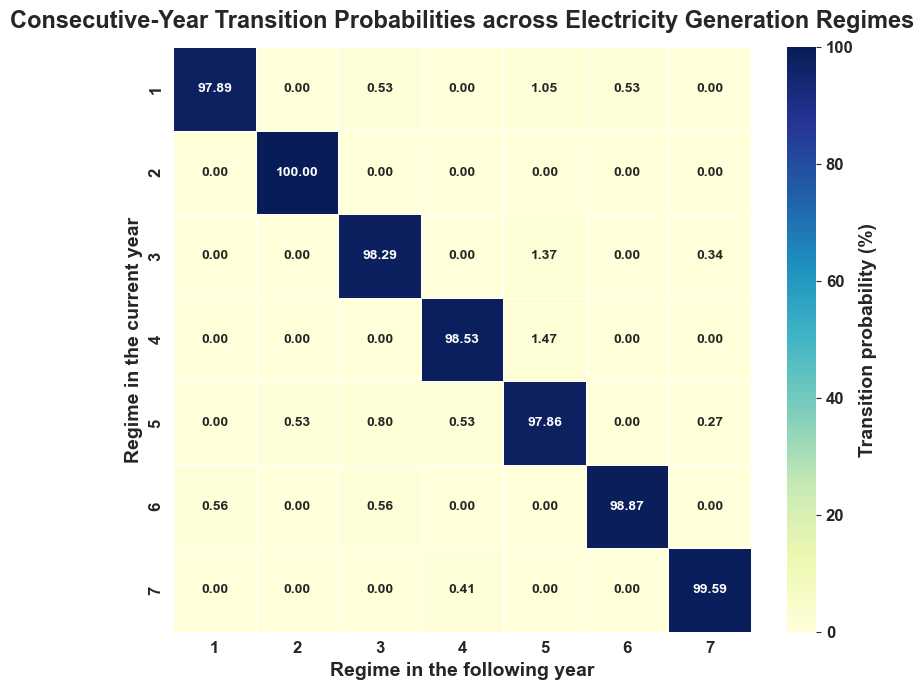

In [42]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams.update({"font.family":"Arial","font.size":10,"font.weight":"bold","axes.titleweight":"bold","axes.labelweight":"bold"})

transition_data = transition_prob.reindex(index=range(1,8), columns=range(1,8))

print("\nTransition Probabilities (%):\n", transition_data.round(2).to_string())

fig, ax = plt.subplots(figsize=(8,7), facecolor="white")
sns.heatmap(transition_data, annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=100, linewidths=.5, annot_kws={"size":10,"weight":"bold"}, cbar_kws={"label":"Transition probability (%)"}, ax=ax)

ax.set_title("Consecutive-Year Transition Probabilities across Electricity Generation Regimes", pad=14)
ax.set_xlabel("Regime in the following year")
ax.set_ylabel("Regime in the current year")

plt.tight_layout()
plt.savefig("Figure_5_Consecutive_Year_Transitions.png", dpi=900, bbox_inches="tight", facecolor="white")
plt.savefig("Figure_5_Consecutive_Year_Transitions.svg", bbox_inches="tight", facecolor="white")
plt.show()



Out-of-Sample Model Performance Results:

                 Model  R2_Log  MAE_Log  RMSE_Log
              LightGBM  0.9389   0.1291    0.2210
           Extra Trees  0.9366   0.1242    0.2251
              CatBoost  0.9354   0.1274    0.2272
               SVR-RBF  0.9348   0.1246    0.2283
               XGBoost  0.9304   0.1321    0.2358
Hist Gradient Boosting  0.9278   0.1358    0.2402
     Gradient Boosting  0.9038   0.1515    0.2773
         Random Forest  0.8964   0.1577    0.2878
                   KNN  0.8419   0.2033    0.3554
            ElasticNet  0.8371   0.2745    0.3608
                 Ridge  0.8364   0.2742    0.3616
              AdaBoost  0.8139   0.2575    0.3857
                 Dummy -0.0043   0.6837    0.8959


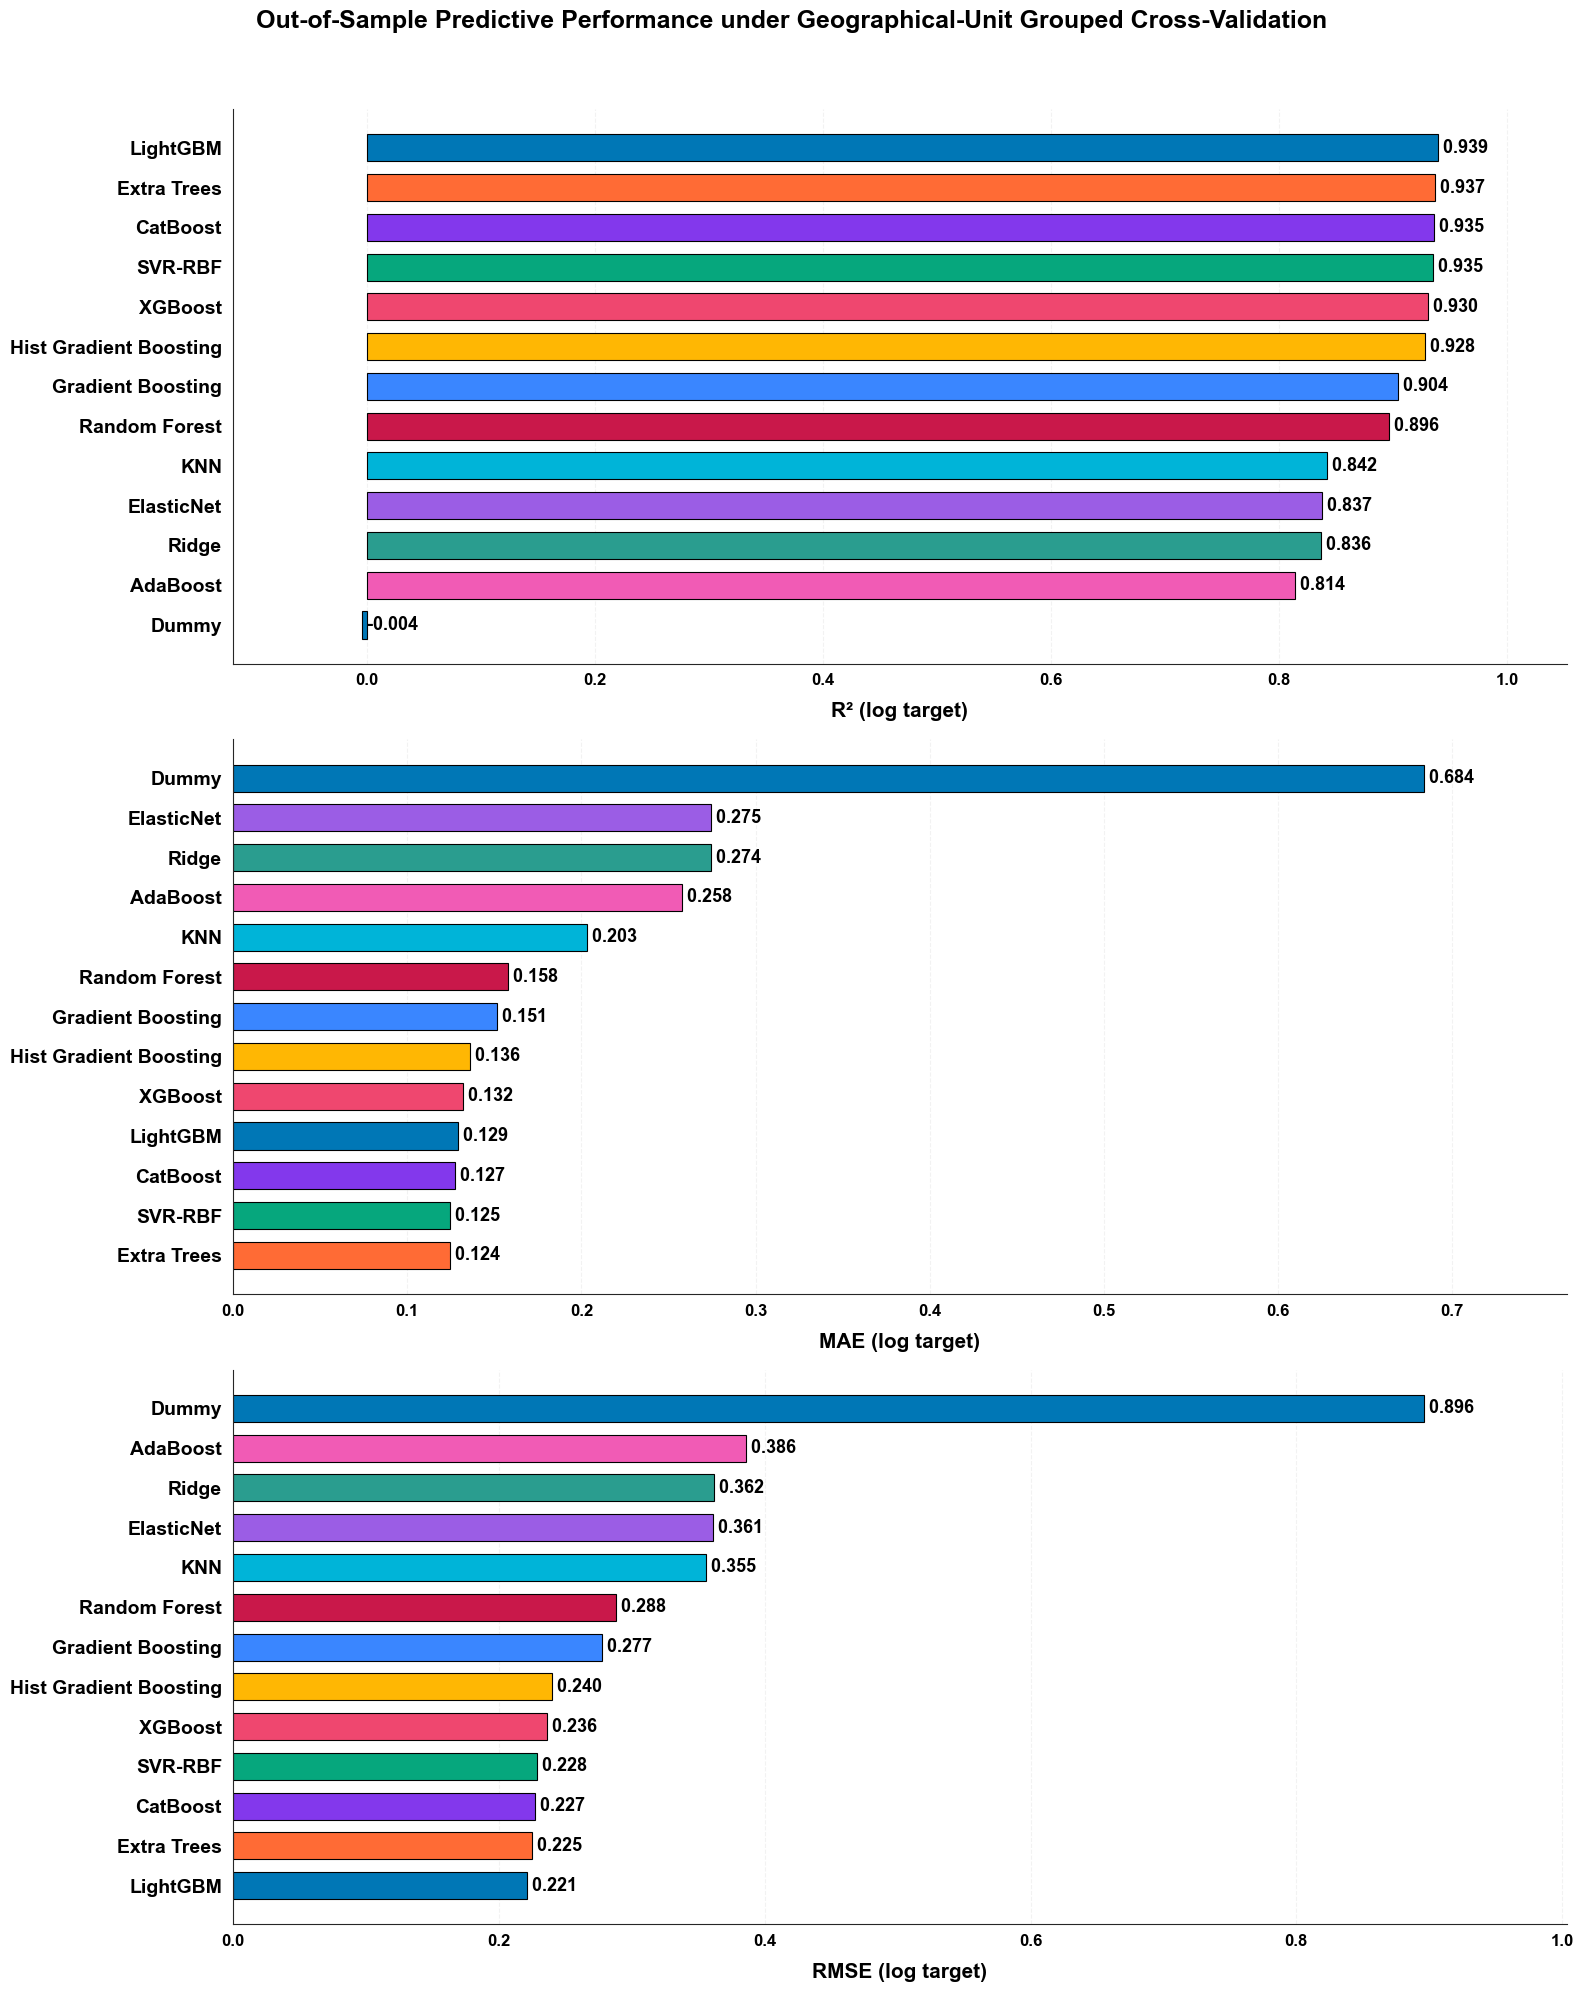

In [49]:
import numpy as np
import matplotlib.pyplot as plt

metrics=[("R2_Log","R² (log target)"),("MAE_Log","MAE (log target)"),("RMSE_Log","RMSE (log target)")]
perf=performance.sort_values("R2_Log",ascending=False).copy()

print("\nOut-of-Sample Model Performance Results:\n")
print(perf[["Model","R2_Log","MAE_Log","RMSE_Log"]].round(4).to_string(index=False))

# Canlı ve uyumlu renk paleti
colors=["#0077B6","#FF6B35","#8338EC","#06A77D","#EF476F",
        "#FFB703","#3A86FF","#C9184A","#00B4D8","#9B5DE5",
        "#2A9D8F","#F15BB5"]

models=perf["Model"].tolist()
model_colors={m:colors[i%len(colors)] for i,m in enumerate(models)}

plt.rcParams.update({"font.family":"Arial","font.size":12,"font.weight":"bold",
                     "axes.labelweight":"bold","axes.titleweight":"bold","text.color":"black"})

fig,axes=plt.subplots(3,1,figsize=(16,20),facecolor="white")

for ax,(col,label) in zip(axes,metrics):
    z=perf.sort_values(col,ascending=True)
    bars=ax.barh(z["Model"],z[col],color=[model_colors[m] for m in z["Model"]],
                 edgecolor="black",linewidth=.8,height=.68)

    for bar,val in zip(bars,z[col]):
        ax.text(val,bar.get_y()+bar.get_height()/2,f" {val:.3f}",
                va="center",ha="left",fontsize=13,fontweight="bold",color="black")

    ax.set_xlabel(label,fontsize=15,fontweight="bold",color="black",labelpad=10)
    ax.tick_params(axis="y",labelsize=14,colors="black",length=0,pad=8)
    ax.tick_params(axis="x",labelsize=12,colors="black")

    for tick in ax.get_yticklabels()+ax.get_xticklabels():
        tick.set_fontweight("bold")
        tick.set_color("black")

    ax.grid(axis="x",linestyle="--",alpha=.25)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.margins(x=.12)

fig.suptitle("Out-of-Sample Predictive Performance under Geographical-Unit Grouped Cross-Validation",
             fontsize=18,fontweight="bold",color="black",y=.995)

plt.tight_layout(rect=[0,0,1,.975])
plt.savefig("Figure_7_ML_Model_Performance.png",dpi=900,bbox_inches="tight",facecolor="white")
plt.savefig("Figure_7_ML_Model_Performance.svg",bbox_inches="tight",facecolor="white")
plt.show()


Out-of-Sample Model Performance Results:

                 Model  R2_Log  MAE_Log  RMSE_Log
              LightGBM  0.9389   0.1291    0.2210
           Extra Trees  0.9366   0.1242    0.2251
              CatBoost  0.9354   0.1274    0.2272
               SVR-RBF  0.9348   0.1246    0.2283
               XGBoost  0.9304   0.1321    0.2358
Hist Gradient Boosting  0.9278   0.1358    0.2402
     Gradient Boosting  0.9038   0.1515    0.2773
         Random Forest  0.8964   0.1577    0.2878
                   KNN  0.8419   0.2033    0.3554
            ElasticNet  0.8371   0.2745    0.3608
                 Ridge  0.8364   0.2742    0.3616
              AdaBoost  0.8139   0.2575    0.3857


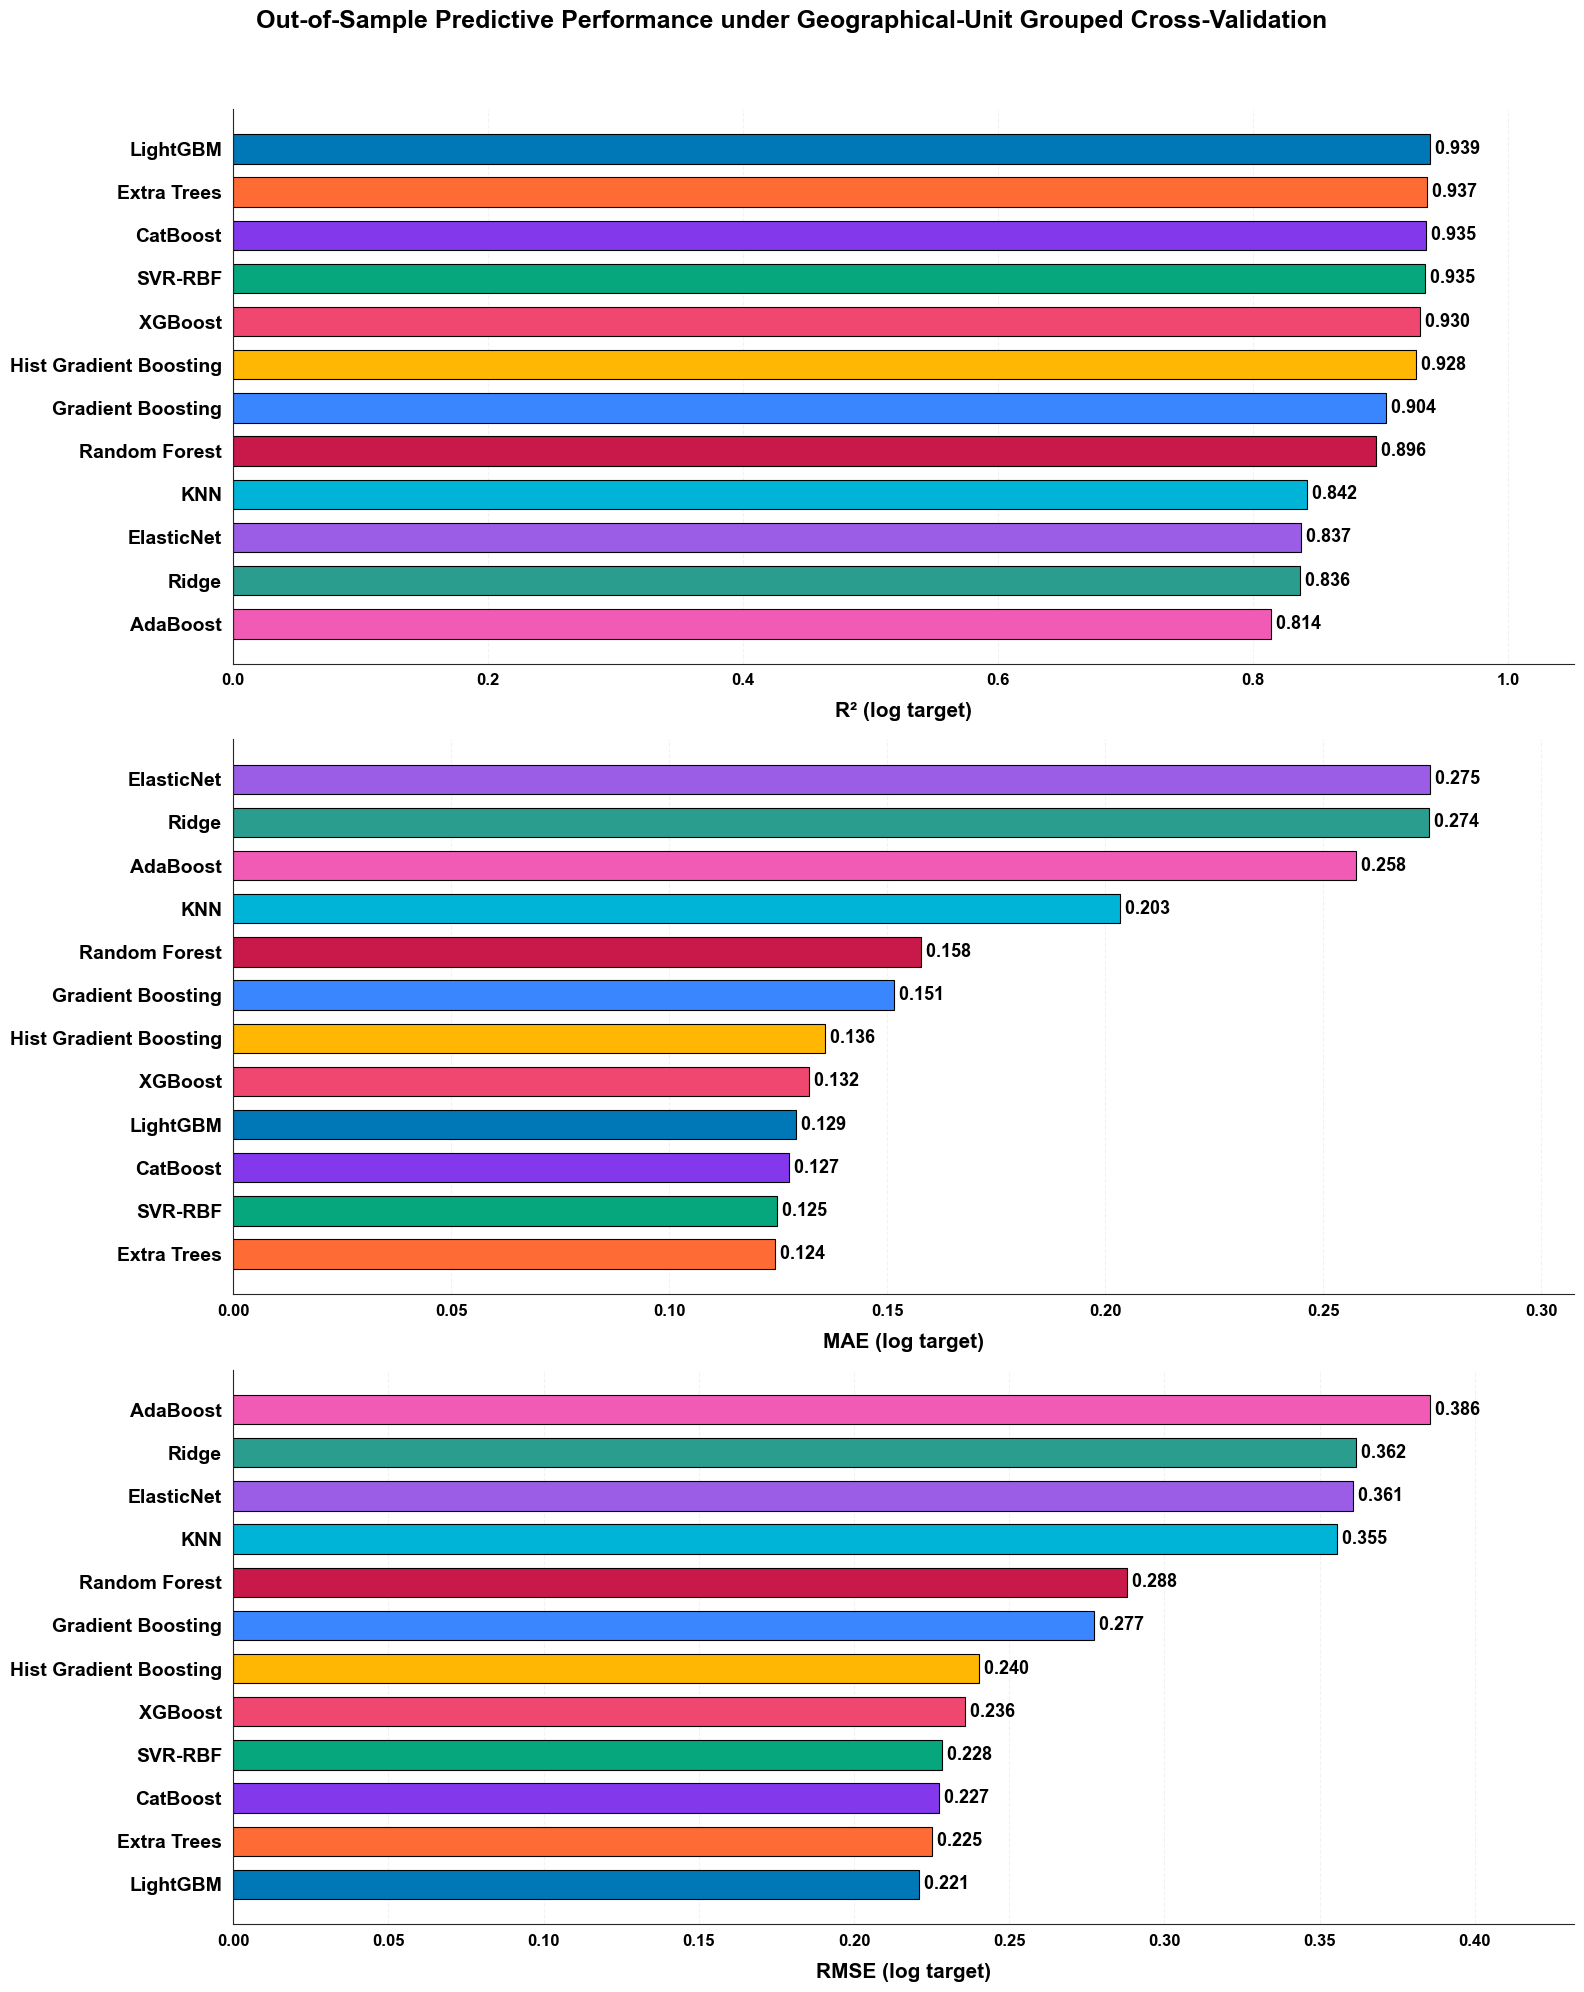

In [50]:
import numpy as np
import matplotlib.pyplot as plt

metrics=[("R2_Log","R² (log target)"),("MAE_Log","MAE (log target)"),("RMSE_Log","RMSE (log target)")]
perf=performance[~performance["Model"].str.contains("Dummy",case=False,na=False)].sort_values("R2_Log",ascending=False).copy()

print("\nOut-of-Sample Model Performance Results:\n")
print(perf[["Model","R2_Log","MAE_Log","RMSE_Log"]].round(4).to_string(index=False))

colors=["#0077B6","#FF6B35","#8338EC","#06A77D","#EF476F",
        "#FFB703","#3A86FF","#C9184A","#00B4D8","#9B5DE5",
        "#2A9D8F","#F15BB5"]

models=perf["Model"].tolist()
model_colors={m:colors[i%len(colors)] for i,m in enumerate(models)}

plt.rcParams.update({"font.family":"Arial","font.size":12,"font.weight":"bold",
                     "axes.labelweight":"bold","axes.titleweight":"bold","text.color":"black"})

fig,axes=plt.subplots(3,1,figsize=(16,20),facecolor="white")

for ax,(col,label) in zip(axes,metrics):
    z=perf.sort_values(col,ascending=True)
    bars=ax.barh(z["Model"],z[col],color=[model_colors[m] for m in z["Model"]],
                 edgecolor="black",linewidth=.8,height=.68)

    for bar,val in zip(bars,z[col]):
        ax.text(val,bar.get_y()+bar.get_height()/2,f" {val:.3f}",
                va="center",ha="left",fontsize=13,fontweight="bold",color="black")

    ax.set_xlabel(label,fontsize=15,fontweight="bold",color="black",labelpad=10)
    ax.tick_params(axis="y",labelsize=14,colors="black",length=0,pad=8)
    ax.tick_params(axis="x",labelsize=12,colors="black")

    for tick in ax.get_yticklabels()+ax.get_xticklabels():
        tick.set_fontweight("bold")
        tick.set_color("black")

    ax.grid(axis="x",linestyle="--",alpha=.25)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.margins(x=.12)

fig.suptitle("Out-of-Sample Predictive Performance under Geographical-Unit Grouped Cross-Validation",
             fontsize=18,fontweight="bold",color="black",y=.995)

plt.tight_layout(rect=[0,0,1,.975])
plt.savefig("Figure_7_ML_Model_Performance.png",dpi=900,bbox_inches="tight",facecolor="white")
plt.savefig("Figure_7_ML_Model_Performance.svg",bbox_inches="tight",facecolor="white")
plt.show()


Extra Trees - SHAP Feature Importance (%):
          Source  Importance_%
Other renewables         2.182
           Solar         3.382
       Bioenergy         5.710
            Wind         6.740
         Nuclear         7.372
             Gas         8.952
    Other fossil        10.140
            Coal        12.739
           Hydro        42.783

CatBoost - SHAP Feature Importance (%):
          Source  Importance_%
Other renewables         2.613
           Solar         3.901
       Bioenergy         5.555
         Nuclear         5.948
            Wind         6.685
             Gas         8.281
    Other fossil        12.465
            Coal        15.451
           Hydro        39.102

LightGBM - SHAP Feature Importance (%):
          Source  Importance_%
Other renewables         1.666
           Solar         3.959
         Nuclear         5.969
            Wind         6.941
       Bioenergy         8.414
             Gas         9.604
    Other fossil        11.606
      

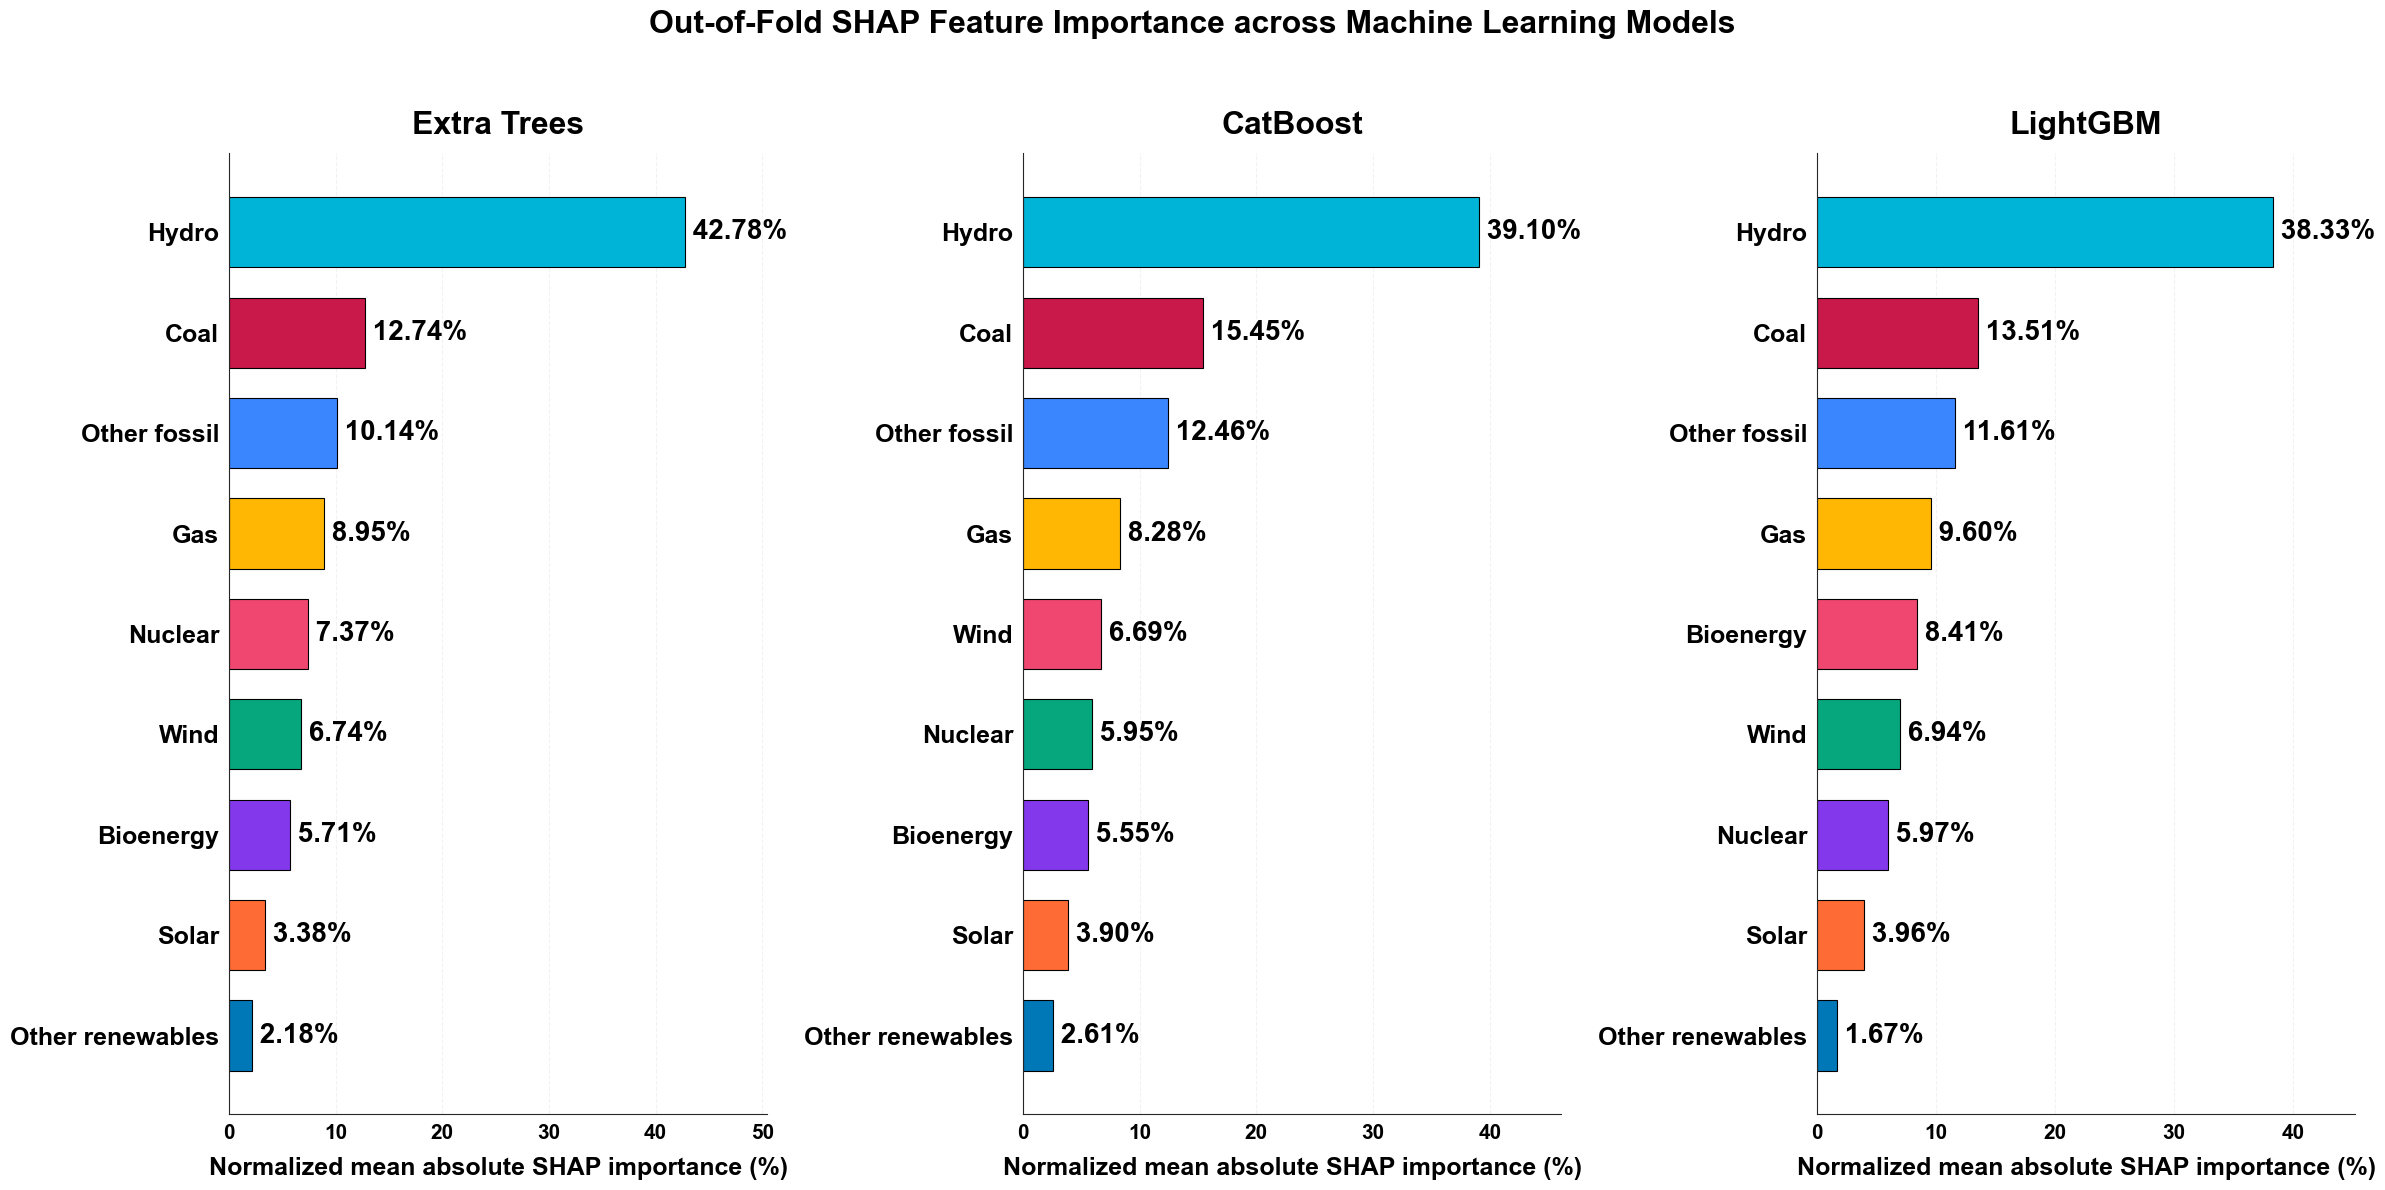

In [53]:
import matplotlib.pyplot as plt

model_order=["Extra Trees","CatBoost","LightGBM"]

colors=["#0077B6","#FF6B35","#8338EC","#06A77D","#EF476F",
        "#FFB703","#3A86FF","#C9184A","#00B4D8","#9B5DE5",
        "#2A9D8F","#F15BB5","#D35400","#4361EE"]

plt.rcParams.update({"font.family":"Arial","font.size":12,"font.weight":"bold",
                     "text.color":"black","axes.labelweight":"bold",
                     "axes.titleweight":"bold"})

fig,axes=plt.subplots(1,3,figsize=(24,12),facecolor="white")

for ax,name in zip(axes,model_order):
    z=shap_summary[shap_summary["Model"]==name].sort_values("Importance_%",ascending=True)

    print(f"\n{name} - SHAP Feature Importance (%):")
    print(z[["Source","Importance_%"]].round(3).to_string(index=False))

    variable_colors=[colors[i%len(colors)] for i in range(len(z))]

    bars=ax.barh(z["Source"],z["Importance_%"],color=variable_colors,
                 edgecolor="black",linewidth=.8,height=.7)

    for bar,val in zip(bars,z["Importance_%"]):
        ax.text(val,bar.get_y()+bar.get_height()/2,f" {val:.2f}%",
                va="center",ha="left",fontsize=20,fontweight="bold",color="black")

    ax.set_title(name,fontsize=23,fontweight="bold",color="black",pad=14)
    ax.set_xlabel("Normalized mean absolute SHAP importance (%)",
                  fontsize=18,fontweight="bold",color="black",labelpad=10)

    ax.tick_params(axis="y",labelsize=18,colors="black",length=0,pad=7)
    ax.tick_params(axis="x",labelsize=15,colors="black")

    for tick in ax.get_yticklabels()+ax.get_xticklabels():
        tick.set_fontweight("bold")
        tick.set_color("black")

    ax.grid(axis="x",linestyle="--",alpha=.25)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.margins(x=.18)

fig.suptitle("Out-of-Fold SHAP Feature Importance across Machine Learning Models",
             fontsize=23,fontweight="bold",color="black",y=.99)

plt.tight_layout(rect=[0,0,1,.96])
plt.savefig("Figure_8_OOF_SHAP_Feature_Importance.png",dpi=900,bbox_inches="tight",facecolor="white")
plt.savefig("Figure_8_OOF_SHAP_Feature_Importance.svg",bbox_inches="tight",facecolor="white")
plt.show()

In [66]:

import pandas as pd

print("=== DATAFRAMES ===")
for k,v in globals().copy().items():
    if isinstance(v,pd.DataFrame):
        print(k, v.shape, list(v.columns)[:15])

print("\n=== RELEVANT VARIABLES ===")
for k,v in globals().copy().items():
    if any(s in k.lower() for s in [
        "hellinger","carbon","intensity","feature",
        "target","group","area","country","shap","model","fold"
    ]):
        print(k, type(v).__name__, getattr(v,"shape",None))

import pandas as pd

print("=== DATAFRAMES ===")
for k,v in globals().copy().items():
    if isinstance(v,pd.DataFrame):
        print(k, v.shape, list(v.columns)[:15])

print("\n=== RELEVANT VARIABLES ===")
for k,v in globals().copy().items():
    if any(s in k.lower() for s in [
        "hellinger","carbon","intensity","feature",
        "target","group","area","country","shap","model","fold"
    ]):
        print(k, type(v).__name__, getattr(v,"shape",None))

import pandas as pd

print("=== DATAFRAMES ===")
for k,v in globals().copy().items():
    if isinstance(v,pd.DataFrame):
        print(k, v.shape, list(v.columns)[:15])

print("\n=== RELEVANT VARIABLES ===")
for k,v in globals().copy().items():
    if any(s in k.lower() for s in [
        "hellinger","carbon","intensity","feature",
        "target","group","area","country","shap","model","fold"
    ]):
        print(k, type(v).__name__, getattr(v,"shape",None))


=== DATAFRAMES ===
df_analysis (1863, 14) ['Area', 'Year', 'Carbon_Intensity', 'Solar', 'Wind', 'Hydro', 'Bioenergy', 'Other renewables', 'Nuclear', 'Coal', 'Gas', 'Other fossil', 'Share_Sum', 'Complete_Composition']
df_corr (1775, 12) ['Solar', 'Wind', 'Hydro', 'Bioenergy', 'Other renewables', 'Nuclear', 'Coal', 'Gas', 'Other fossil', 'Carbon_Intensity', 'Year', 'Area']
corr_matrix (10, 10) ['Solar', 'Wind', 'Hydro', 'Bioenergy', 'Other renewables', 'Nuclear', 'Coal', 'Gas', 'Other fossil', 'Carbon_Intensity']
p_matrix (10, 10) ['Solar', 'Wind', 'Hydro', 'Bioenergy', 'Other renewables', 'Nuclear', 'Coal', 'Gas', 'Other fossil', 'Carbon_Intensity']
valid (1775, 2) ['Carbon_Intensity', 'Other fossil']
corr_results (9, 6) ['Variable', 'N', 'Pearson_r', 'p_value', 'p_BH', 'Significant_BH_05']
d (1775, 18) ['Area', 'Year', 'Carbon_Intensity', 'Solar', 'Wind', 'Hydro', 'Bioenergy', 'Other renewables', 'Nuclear', 'Coal', 'Gas', 'Other fossil', 'Share_Sum', 'Complete_Composition', 'Log_CI']
p

In [68]:

import numpy as np
import pandas as pd
from scipy.stats import kendalltau, spearmanr

# Validate existing results
required={"Model","Fold","Source","Importance"}
assert required.issubset(imp.columns), f"Missing columns: {required-set(imp.columns)}"

shap_fold_df=imp[list(required)].copy()
shap_fold_df["Importance"]=pd.to_numeric(shap_fold_df["Importance"],errors="coerce")
assert shap_fold_df["Importance"].notna().all()
assert np.isfinite(shap_fold_df["Importance"]).all()

# Use magnitude of the signed SHAP values
shap_fold_df["Abs_Importance"]=shap_fold_df["Importance"].abs()

# Check unique model-fold-feature observations
assert not shap_fold_df.duplicated(["Model","Fold","Source"]).any()
assert (shap_fold_df.groupby(["Model","Fold"])["Abs_Importance"].sum()>0).all()

# Normalize within each model and fold
shap_fold_df["Importance_%"]=100*shap_fold_df["Abs_Importance"]/shap_fold_df.groupby(["Model","Fold"])["Abs_Importance"].transform("sum")

# Fold-level importance summary
fold_summary=(shap_fold_df.groupby(["Model","Source"])
    .agg(Mean_Importance=("Importance_%","mean"),
         SD_Importance=("Importance_%","std"))
    .reset_index())

# Rank stability
stability_rows=[]
for model,g in shap_fold_df.groupby("Model"):
    wide=g.pivot(index="Fold",columns="Source",values="Importance_%").sort_index()
    ranks=wide.rank(axis=1,ascending=False,method="average")
    pairs=[(i,j) for i in range(len(ranks)) for j in range(i+1,len(ranks))]
    kendall=[kendalltau(ranks.iloc[i],ranks.iloc[j]).statistic for i,j in pairs]
    spearman=[spearmanr(ranks.iloc[i],ranks.iloc[j]).statistic for i,j in pairs]
    mean_ranks=ranks.mean()
    top=mean_ranks.idxmin()
    stability_rows.append({
        "Model":model,
        "N_Folds":len(ranks),
        "Mean_Kendall_Tau":np.nanmean(kendall),
        "Mean_Spearman":np.nanmean(spearman),
        "Top_Feature":top,
        "Mean_Rank":mean_ranks[top],
        "Rank_SD":ranks[top].std(),
        "Top_Rank_Frequency_%":100*(ranks[top]==1).mean()
    })

stability=pd.DataFrame(stability_rows)

# Display
print("\nFOLD-LEVEL SHAP IMPORTANCE")
print(fold_summary.round(4).to_string(index=False))
print("\nSHAP RANK STABILITY")
print(stability.round(4).to_string(index=False))

# Export
shap_fold_df.to_csv("SHAP_Fold_Level_Results.csv",index=False)
fold_summary.to_csv("SHAP_Fold_Importance_Summary.csv",index=False)
stability.to_csv("SHAP_Rank_Stability.csv",index=False)

print("\nAll supplementary tables exported successfully.")



FOLD-LEVEL SHAP IMPORTANCE
      Model           Source  Mean_Importance  SD_Importance
   CatBoost        Bioenergy           3.8855         0.8161
   CatBoost             Coal          16.5691         2.6796
   CatBoost              Gas           7.6723         1.7579
   CatBoost            Hydro          45.5807         2.2418
   CatBoost          Nuclear           7.2460         2.6969
   CatBoost     Other fossil          11.2291         2.5846
   CatBoost Other renewables           0.9723         1.0137
   CatBoost            Solar           1.8623         1.4603
   CatBoost             Wind           4.9827         1.5473
Extra Trees        Bioenergy           2.9695         0.9828
Extra Trees             Coal          15.1090         2.9518
Extra Trees              Gas           9.3551         1.6033
Extra Trees            Hydro          47.5987         4.2533
Extra Trees          Nuclear           6.3683         2.3962
Extra Trees     Other fossil          12.1442         1.8

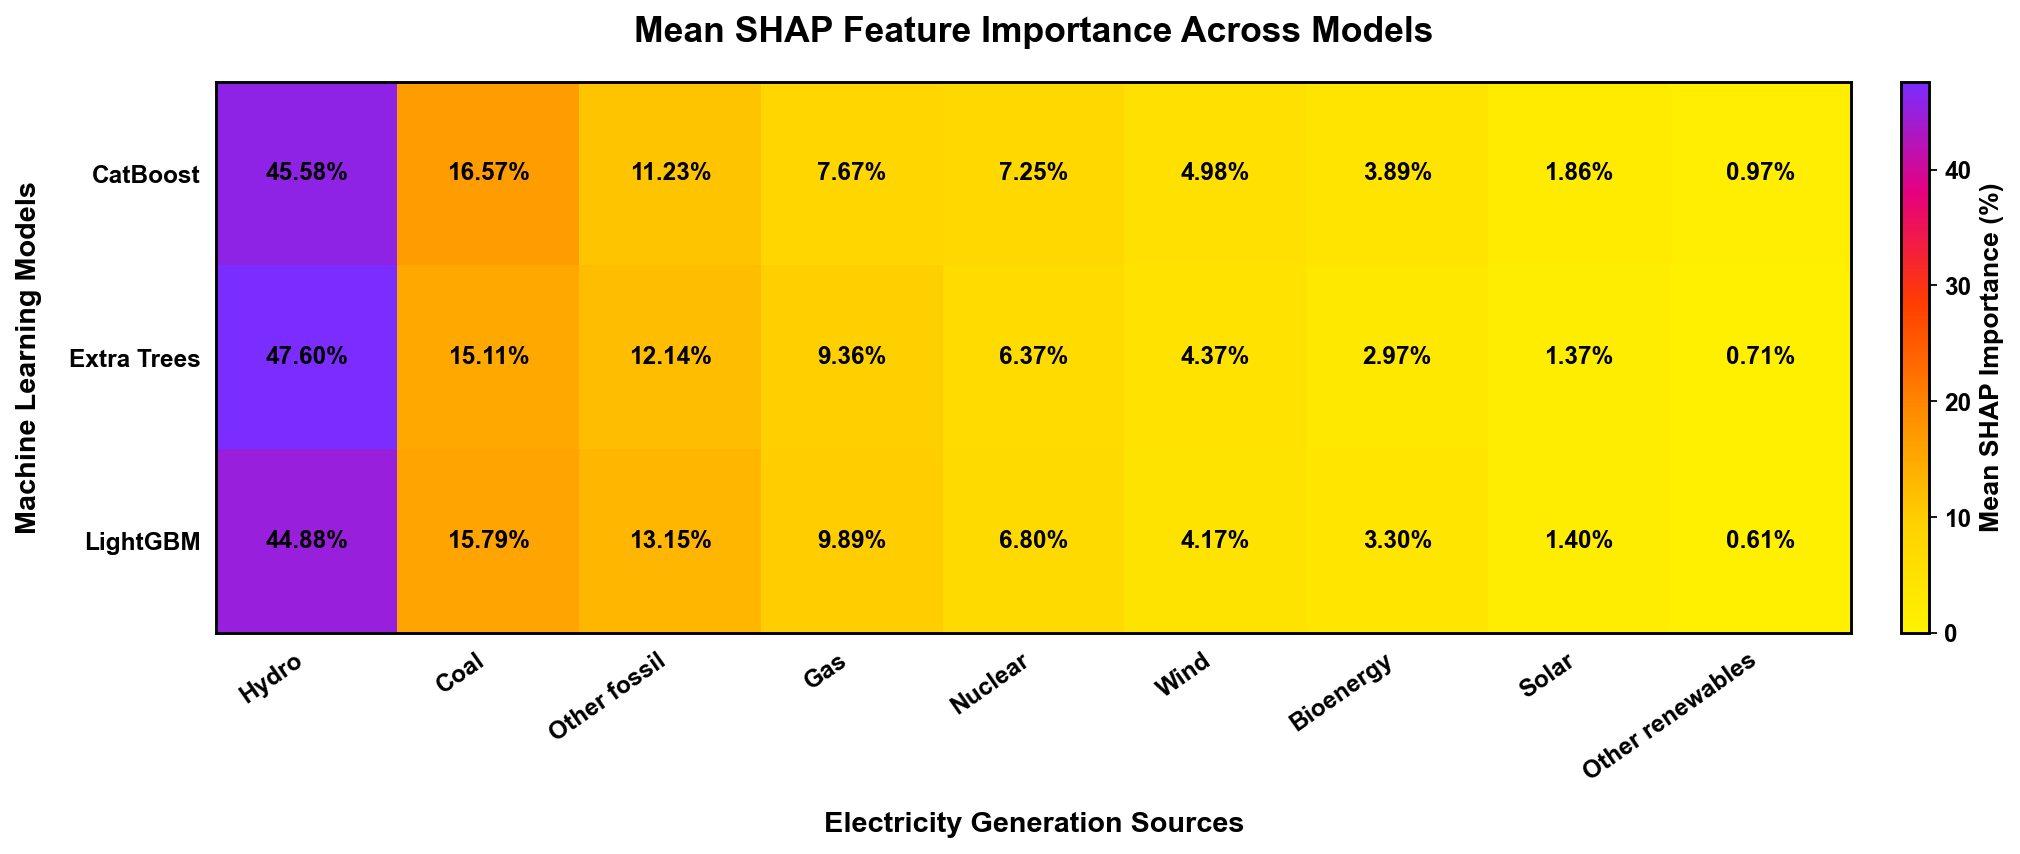

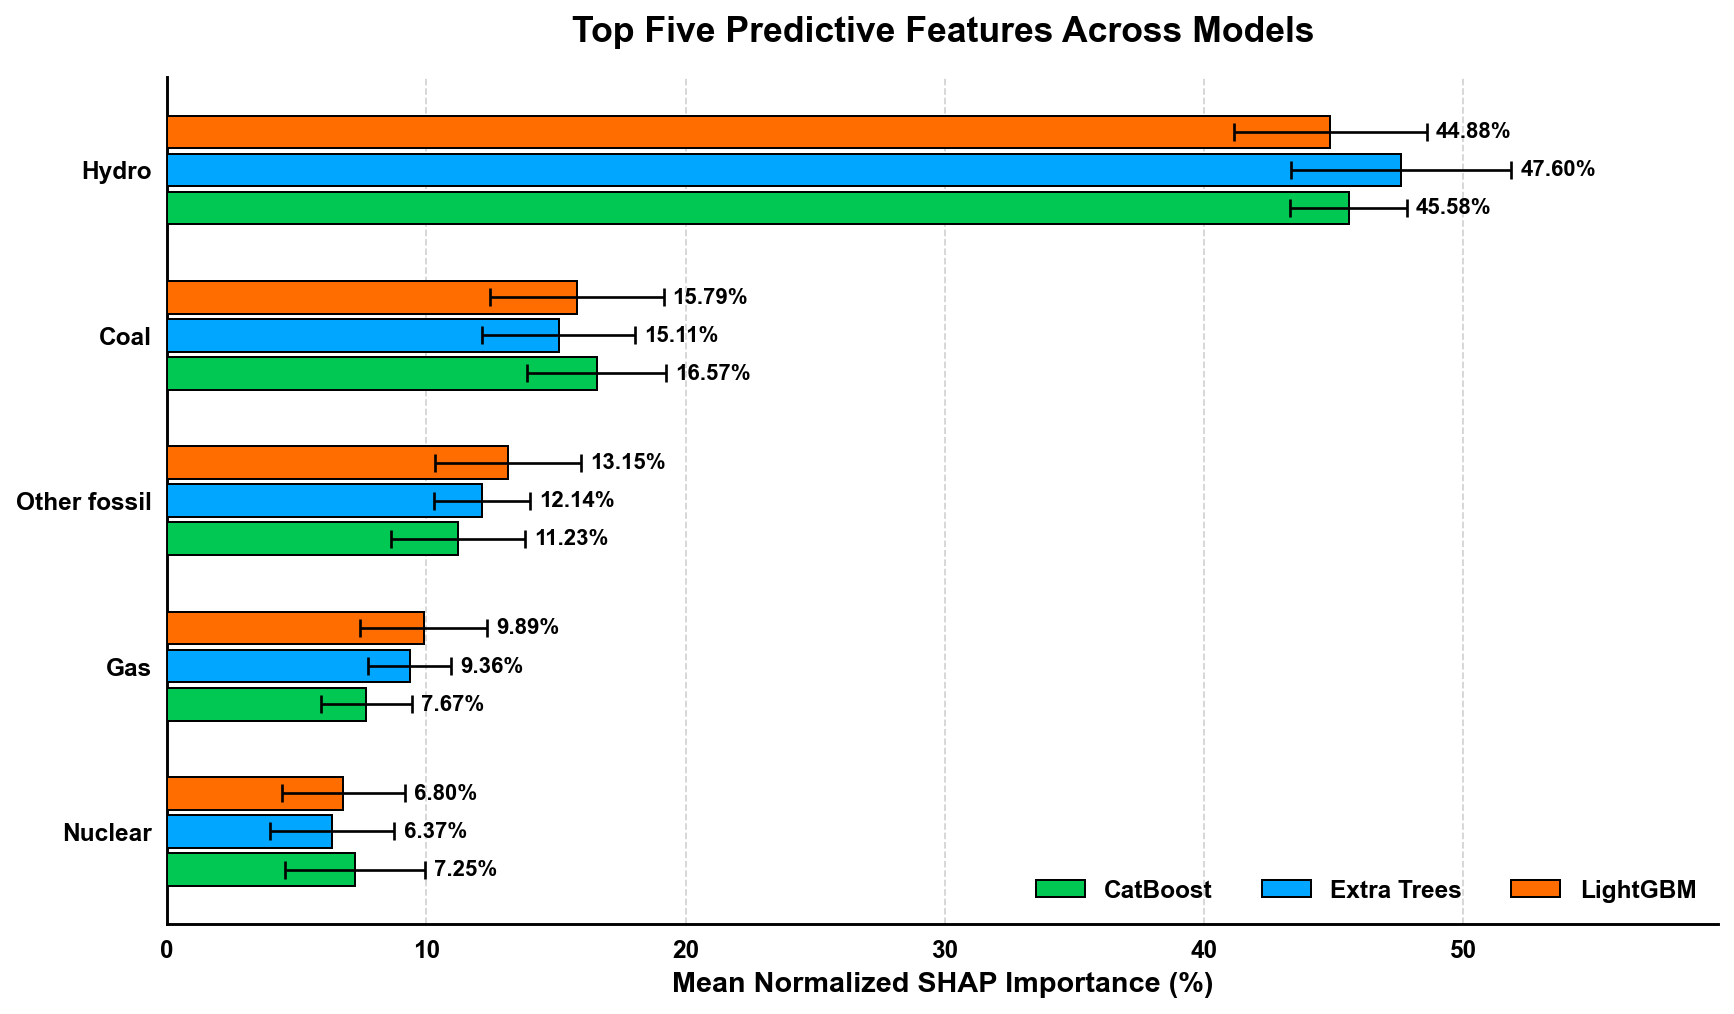

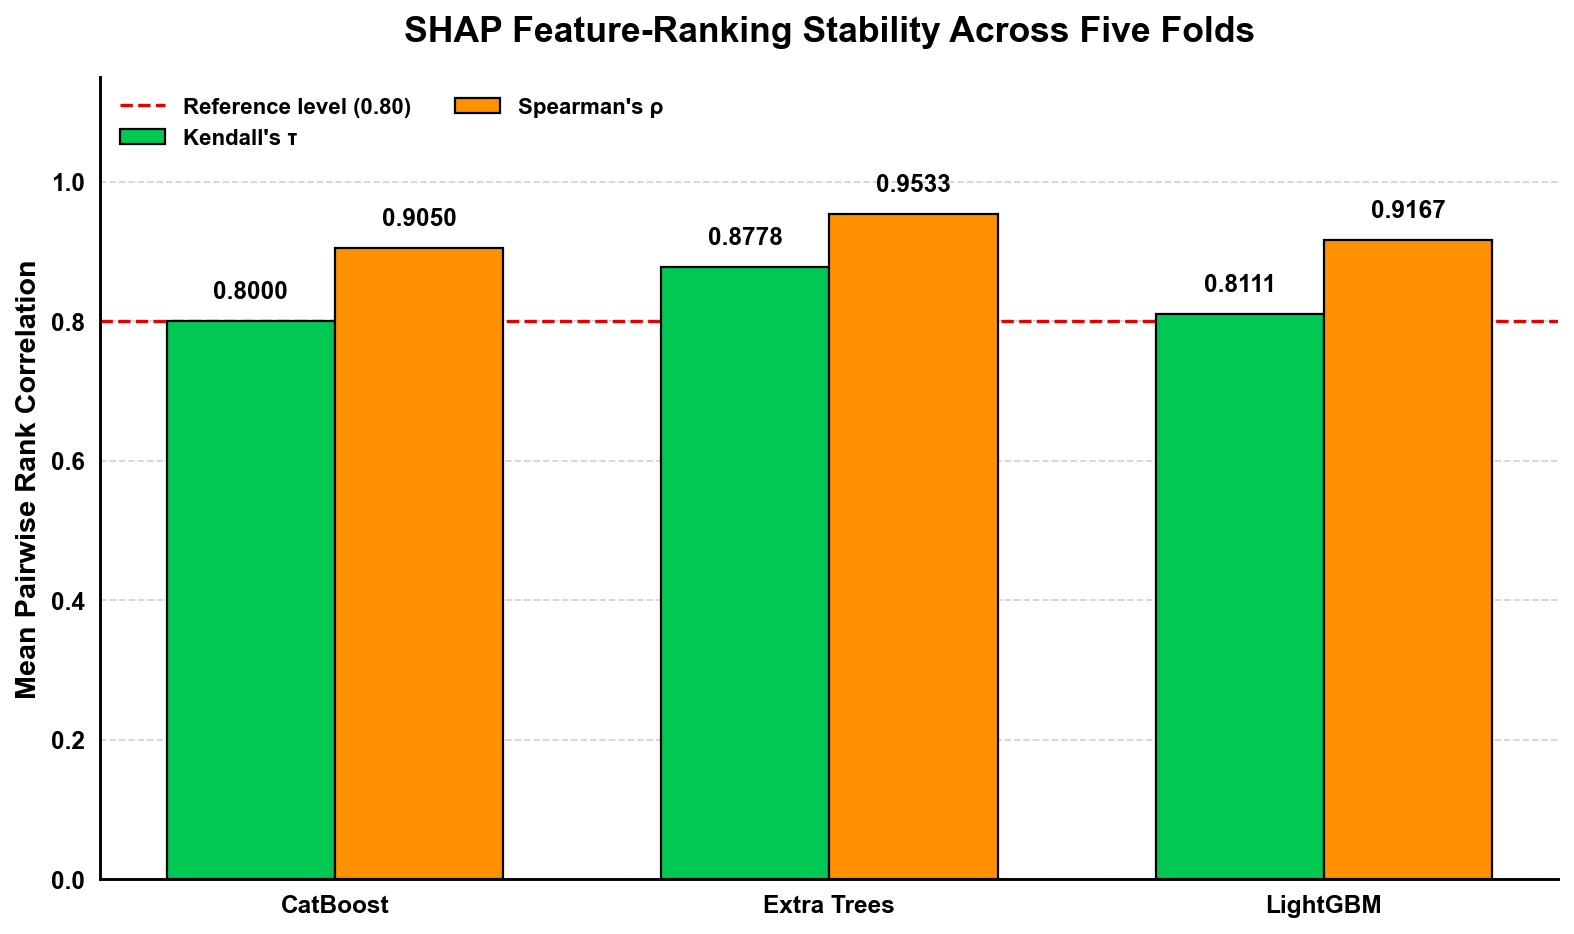


ALL FIGURES AND NUMERICAL DATA EXPORTED
Output directory: C:\Users\sadul\SHAP_Visual_Results_SSCI

Figure S1: SHAP heatmap
Source         Hydro     Coal  Other fossil     Gas  Nuclear    Wind  Bioenergy   Solar  Other renewables
Model                                                                                                    
CatBoost     45.5807  16.5691       11.2291  7.6723   7.2460  4.9827     3.8855  1.8623            0.9723
Extra Trees  47.5987  15.1090       12.1442  9.3551   6.3683  4.3702     2.9695  1.3719            0.7131
LightGBM     44.8830  15.7916       13.1492  9.8938   6.7970  4.1731     3.2967  1.4037            0.6119

Figure S2: Top-five feature importance
      Model       Source  Mean_Importance  SD_Importance
   CatBoost         Coal          16.5691         2.6796
   CatBoost          Gas           7.6723         1.7579
   CatBoost        Hydro          45.5807         2.2418
   CatBoost      Nuclear           7.2460         2.6969
   CatBoost Other fos

In [70]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
from pathlib import Path

OUT=Path("SHAP_Visual_Results_SSCI")
OUT.mkdir(exist_ok=True)

# Publication-quality formatting
plt.rcParams.update({
    "font.family":"Arial",
    "font.size":12,
    "font.weight":"bold",
    "text.color":"black",
    "axes.labelcolor":"black",
    "axes.labelweight":"bold",
    "axes.titleweight":"bold",
    "axes.edgecolor":"black",
    "axes.linewidth":1.3,
    "xtick.color":"black",
    "ytick.color":"black",
    "xtick.labelsize":11,
    "ytick.labelsize":11,
    "savefig.dpi":600,
    "figure.dpi":160,
    "figure.facecolor":"white",
    "axes.facecolor":"white"
})

models=["CatBoost","Extra Trees","LightGBM"]
sources=["Hydro","Coal","Other fossil","Gas","Nuclear","Wind","Bioenergy","Solar","Other renewables"]
colors={"CatBoost":"#00C853","Extra Trees":"#00A6FF","LightGBM":"#FF6D00"}

assert {"Model","Source","Mean_Importance","SD_Importance"}.issubset(fold_summary.columns)
assert {"Model","Mean_Kendall_Tau","Mean_Spearman","Top_Feature"}.issubset(stability.columns)

heat=fold_summary.pivot(index="Model",columns="Source",values="Mean_Importance").reindex(index=models,columns=sources)
assert heat.notna().all().all()

# FIGURE S1: High-contrast SHAP heatmap
fig,ax=plt.subplots(figsize=(14,5.5))
cmap=LinearSegmentedColormap.from_list("vivid_shap",[
    "#FFF200","#FFD000","#FF8C00","#FF3D00","#E6007E","#7B2CFF"
])
im=ax.imshow(heat.values,aspect="auto",cmap=cmap,
             norm=Normalize(vmin=0,vmax=heat.values.max()),interpolation="nearest")

ax.set_xticks(range(len(sources)))
ax.set_xticklabels(sources,rotation=35,ha="right",fontweight="bold",color="black")
ax.set_yticks(range(len(models)))
ax.set_yticklabels(models,fontweight="bold",color="black")

for i in range(len(models)):
    for j in range(len(sources)):
        val=heat.iloc[i,j]
        ax.text(j,i,f"{val:.2f}%",ha="center",va="center",
                fontsize=11,fontweight="bold",color="black")

ax.set_title("Mean SHAP Feature Importance Across Models",fontsize=16,pad=18,color="black")
ax.set_xlabel("Electricity Generation Sources",fontsize=13,labelpad=12,fontweight="bold")
ax.set_ylabel("Machine Learning Models",fontsize=13,labelpad=12,fontweight="bold")
cb=fig.colorbar(im,ax=ax,pad=0.025)
cb.set_label("Mean SHAP Importance (%)",fontsize=12,fontweight="bold",color="black")
cb.ax.tick_params(labelcolor="black")
for t in cb.ax.get_yticklabels():
    t.set_fontweight("bold")
for spine in ax.spines.values():
    spine.set_linewidth(1.3)
fig.tight_layout()
fig.savefig(OUT/"Figure_S1_SHAP_Heatmap.png",dpi=600,bbox_inches="tight")
fig.savefig(OUT/"Figure_S1_SHAP_Heatmap.tiff",dpi=600,bbox_inches="tight")
plt.show()

# FIGURE S2: Top-five SHAP importance with SD
top_sources=(fold_summary.groupby("Source")["Mean_Importance"]
             .mean().nlargest(5).index.tolist())
plot_df=fold_summary[fold_summary["Source"].isin(top_sources)].copy()
plot_df["Source"]=pd.Categorical(plot_df["Source"],categories=top_sources[::-1],ordered=True)
plot_df=plot_df.sort_values("Source")

fig,ax=plt.subplots(figsize=(11,6.5))
y=np.arange(len(top_sources))
width=0.23

for k,m in enumerate(models):
    sub=plot_df[plot_df["Model"]==m].set_index("Source").reindex(top_sources[::-1])
    pos=y+(k-1)*width
    bars=ax.barh(pos,sub["Mean_Importance"],height=width*0.86,
        xerr=sub["SD_Importance"],capsize=4,
        color=colors[m],edgecolor="black",linewidth=0.9,
        error_kw={"ecolor":"black","elinewidth":1.2,"capthick":1.2},
        label=m,zorder=3)
    for bar,val,sd in zip(bars,sub["Mean_Importance"],sub["SD_Importance"]):
        ax.text(bar.get_width()+sd+0.35,bar.get_y()+bar.get_height()/2,
                f"{val:.2f}%",ha="left",va="center",
                fontsize=10,fontweight="bold",color="black")

ax.set_yticks(y)
ax.set_yticklabels(top_sources[::-1],fontweight="bold",color="black")
ax.set_xlabel("Mean Normalized SHAP Importance (%)",fontsize=13,fontweight="bold")
ax.set_title("Top Five Predictive Features Across Models",fontsize=16,pad=16,color="black")
ax.legend(frameon=False,ncol=3,loc="lower right",prop={"weight":"bold","size":11})
ax.grid(axis="x",linestyle="--",linewidth=0.8,color="#B0B0B0",alpha=0.55,zorder=0)
ax.set_axisbelow(True)
ax.spines[["top","right"]].set_visible(False)
ax.tick_params(axis="both",colors="black")
ax.set_xlim(0,(plot_df["Mean_Importance"]+plot_df["SD_Importance"]).max()+8)
fig.tight_layout()
fig.savefig(OUT/"Figure_S2_Top5_SHAP_Importance.png",dpi=600,bbox_inches="tight")
fig.savefig(OUT/"Figure_S2_Top5_SHAP_Importance.tiff",dpi=600,bbox_inches="tight")
plt.show()

# FIGURE S3: Fold-level ranking stability
stab=stability.set_index("Model").reindex(models)
x=np.arange(len(models))
width=0.34

fig,ax=plt.subplots(figsize=(10,6))
b1=ax.bar(x-width/2,stab["Mean_Kendall_Tau"],width,
          color="#00C853",edgecolor="black",linewidth=1.0,label="Kendall's τ",zorder=3)
b2=ax.bar(x+width/2,stab["Mean_Spearman"],width,
          color="#FF9100",edgecolor="black",linewidth=1.0,label="Spearman's ρ",zorder=3)

for bars in [b1,b2]:
    for bar in bars:
        h=bar.get_height()
        ax.text(bar.get_x()+bar.get_width()/2,h+0.025,f"{h:.4f}",
                ha="center",va="bottom",fontsize=11,fontweight="bold",color="black")

ax.set_xticks(x)
ax.set_xticklabels(models,fontweight="bold",color="black")
ax.set_ylim(0,1.15)
ax.set_ylabel("Mean Pairwise Rank Correlation",fontsize=13,fontweight="bold")
ax.set_title("SHAP Feature-Ranking Stability Across Five Folds",fontsize=16,pad=16,color="black")
ax.axhline(0.8,color="#E60000",linestyle="--",linewidth=1.5,label="Reference level (0.80)")
ax.legend(frameon=False,loc="upper left",ncol=2,prop={"weight":"bold","size":10})
ax.grid(axis="y",linestyle="--",linewidth=0.8,color="#B0B0B0",alpha=0.55,zorder=0)
ax.set_axisbelow(True)
ax.spines[["top","right"]].set_visible(False)
fig.tight_layout()
fig.savefig(OUT/"Figure_S3_SHAP_Rank_Stability.png",dpi=600,bbox_inches="tight")
fig.savefig(OUT/"Figure_S3_SHAP_Rank_Stability.tiff",dpi=600,bbox_inches="tight")
plt.show()

# Export every numerical value displayed in the figures
heat_export=heat.reset_index().rename(columns={"index":"Model"})
bar_export=fold_summary[fold_summary["Source"].isin(top_sources)].copy()
stability_export=stability.copy()

with pd.ExcelWriter(OUT/"SHAP_Figure_Data.xlsx",engine="openpyxl") as writer:
    heat_export.to_excel(writer,sheet_name="Figure_S1_Heatmap",index=False)
    bar_export.to_excel(writer,sheet_name="Figure_S2_Top5",index=False)
    stability_export.to_excel(writer,sheet_name="Figure_S3_Stability",index=False)

heat_export.to_csv(OUT/"Figure_S1_Heatmap_Data.csv",index=False)
bar_export.to_csv(OUT/"Figure_S2_Top5_Data.csv",index=False)
stability_export.to_csv(OUT/"Figure_S3_Stability_Data.csv",index=False)

print("\nALL FIGURES AND NUMERICAL DATA EXPORTED")
print("Output directory:",OUT.resolve())
print("\nFigure S1: SHAP heatmap")
print(heat.round(4).to_string())
print("\nFigure S2: Top-five feature importance")
print(bar_export.round(4).to_string(index=False))
print("\nFigure S3: Ranking stability")
print(stability_export.round(4).to_string(index=False))
print("\nFormats: 600-DPI PNG and TIFF; numerical values: Excel and CSV")


In [62]:

import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display

# 1. SOURCE DATA VALIDATION
data = d[["Area", "Year", "Regime"]].dropna().copy()
data["Year"] = pd.to_numeric(data["Year"], errors="raise").astype(int)
data["Regime"] = pd.to_numeric(data["Regime"], errors="raise").astype(int)

if data.duplicated(["Area", "Year"]).any():
    raise ValueError("Duplicate Area-Year observations detected.")

data = data.sort_values(["Area", "Year"]).reset_index(drop=True)

# 2. REGIME FREQUENCIES
counts = (
    data.groupby(["Area", "Regime"])
    .size()
    .reset_index(name="Regime_Observations")
)
counts["Total_Observations"] = counts.groupby("Area")["Regime_Observations"].transform("sum")
counts["Regime_Percentage"] = 100 * counts["Regime_Observations"] / counts["Total_Observations"]

# 3. DOMINANT REGIME IDENTIFICATION
maximum = counts.groupby("Area")["Regime_Observations"].transform("max")
dominant = counts[counts["Regime_Observations"].eq(maximum)].copy()
tie_counts = dominant.groupby("Area").size()
dominant["Dominance_Status"] = np.where(dominant["Area"].map(tie_counts).gt(1), "Tied", "Unique")

dominant = dominant.rename(columns={
    "Regime": "Dominant_Regime",
    "Regime_Observations": "Dominant_Regime_Observations",
    "Regime_Percentage": "Dominant_Regime_Percentage"
}).drop(columns="Total_Observations")

# 4. GEOGRAPHICAL AND TEMPORAL STATISTICS
unit_stats = (
    data.groupby("Area")
    .agg(
        First_Year=("Year", "min"),
        Last_Year=("Year", "max"),
        Number_of_Years=("Year", "nunique"),
        Number_of_Regimes=("Regime", "nunique"),
        Total_Observations=("Regime", "size")
    )
    .reset_index()
)

unit_stats["Regime_Switch"] = np.where(
    unit_stats["Number_of_Regimes"].gt(1), "Yes", "No"
)

# 5. CONSTRUCT TABLE S1
table_s1 = dominant.merge(
    unit_stats, on="Area", how="left", validate="many_to_one"
).rename(columns={"Area": "Geographical_Unit"})

table_s1 = table_s1[[
    "Geographical_Unit", "Dominant_Regime",
    "Dominant_Regime_Observations", "Total_Observations",
    "Dominant_Regime_Percentage", "First_Year", "Last_Year",
    "Number_of_Years", "Number_of_Regimes",
    "Regime_Switch", "Dominance_Status"
]].sort_values(
    ["Dominant_Regime", "Geographical_Unit"]
).reset_index(drop=True)

table_s1["Dominant_Regime_Percentage"] = table_s1["Dominant_Regime_Percentage"].round(2)

# 6. VALIDATION
assert table_s1["Geographical_Unit"].nunique() == data["Area"].nunique()
assert unit_stats["Total_Observations"].sum() == len(data)
assert table_s1["Dominant_Regime_Observations"].le(table_s1["Total_Observations"]).all()
assert np.allclose(
    table_s1["Dominant_Regime_Percentage"],
    100 * table_s1["Dominant_Regime_Observations"] / table_s1["Total_Observations"],
    atol=0.011
)
assert table_s1["Dominance_Status"].isin(["Unique", "Tied"]).all()

# 7. COMPLETE REGIME DISTRIBUTION
regime_distribution = counts.sort_values(["Area", "Regime"]).reset_index(drop=True)

# 8. ADDITIONAL REGIME SUMMARY
regime_summary = (
    data.groupby("Regime")
    .agg(
        Total_Observations=("Area", "size"),
        Number_of_Geographical_Units=("Area", "nunique"),
        First_Year=("Year", "min"),
        Last_Year=("Year", "max")
    )
    .reset_index()
)
regime_summary["Observation_Percentage"] = (
    100 * regime_summary["Total_Observations"] / len(data)
).round(2)

# 9. COMPLETE CONSOLE OUTPUT
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 240)
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.expand_frame_repr", False)

print("\n" + "=" * 100)
print("SUPPLEMENTARY TABLE S1: DOMINANT GEOGRAPHICAL REGIME CLASSIFICATIONS")
print("=" * 100)
print(f"Total observations       : {len(data):,}")
print(f"Geographical units       : {data['Area'].nunique():,}")
print(f"Observation period       : {data['Year'].min()}–{data['Year'].max()}")
print(f"Number of regimes        : {data['Regime'].nunique()}")
print(f"Unique dominant regimes  : {(table_s1['Dominance_Status'] == 'Unique').sum()}")
print(f"Tied dominant regimes    : {(table_s1['Dominance_Status'] == 'Tied').sum()}")
print(f"Units with multiple regimes: {(unit_stats['Regime_Switch'] == 'Yes').sum()}")
print(f"Units with one regime      : {(unit_stats['Regime_Switch'] == 'No').sum()}")

print("\n" + "-" * 100)
print("TABLE S1. DOMINANT REGIME CLASSIFICATION BY GEOGRAPHICAL UNIT")
print("-" * 100)
display(table_s1.style.format({
    "Dominant_Regime_Percentage": "{:.2f}%",
    "Dominant_Regime_Observations": "{:,.0f}",
    "Total_Observations": "{:,.0f}"
}).hide(axis="index"))

print("\n" + "-" * 100)
print("TABLE S1A. COMPLETE REGIME FREQUENCIES BY GEOGRAPHICAL UNIT")
print("-" * 100)
display(regime_distribution.style.format({
    "Regime_Percentage": "{:.2f}%",
    "Regime_Observations": "{:,.0f}",
    "Total_Observations": "{:,.0f}"
}).hide(axis="index"))

print("\n" + "-" * 100)
print("TABLE S1B. OVERALL REGIME DISTRIBUTION")
print("-" * 100)
display(regime_summary.style.format({
    "Observation_Percentage": "{:.2f}%",
    "Total_Observations": "{:,.0f}"
}).hide(axis="index"))

print("\n" + "-" * 100)
print("DOMINANT REGIME COUNTS")
print("-" * 100)
display(
    table_s1.groupby("Dominant_Regime")
    .agg(
        Geographical_Units=("Geographical_Unit", "nunique"),
        Mean_Dominance_Percentage=("Dominant_Regime_Percentage", "mean"),
        Minimum_Dominance_Percentage=("Dominant_Regime_Percentage", "min"),
        Maximum_Dominance_Percentage=("Dominant_Regime_Percentage", "max")
    )
    .round(2)
    .reset_index()
)

# 10. EXPORT ALL RESULTS
output = Path("Supplementary_Table_S1")
output.mkdir(exist_ok=True)

excel_path = output / "Supplementary_Table_S1.xlsx"
csv_path = output / "Supplementary_Table_S1.csv"

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    table_s1.to_excel(writer, sheet_name="Table_S1", index=False)
    regime_distribution.to_excel(writer, sheet_name="Regime_Frequencies", index=False)
    regime_summary.to_excel(writer, sheet_name="Overall_Regime_Summary", index=False)

    for sheet in writer.sheets.values():
        sheet.freeze_panes = "A2"
        sheet.auto_filter.ref = sheet.dimensions
        for column in sheet.columns:
            width = min(max(max(len(str(cell.value or "")) for cell in column) + 2, 12), 40)
            sheet.column_dimensions[column[0].column_letter].width = width

table_s1.to_csv(csv_path, index=False, encoding="utf-8-sig")

print("\n" + "=" * 100)
print("EXPORT COMPLETED SUCCESSFULLY")
print("=" * 100)
print("Excel file :", excel_path.resolve())
print("CSV file   :", csv_path.resolve())
print("Excel sheets: Table_S1 | Regime_Frequencies | Overall_Regime_Summary")
print("All validation checks passed.")
print("=" * 100)



SUPPLEMENTARY TABLE S1: DOMINANT GEOGRAPHICAL REGIME CLASSIFICATIONS
Total observations       : 1,775
Geographical units       : 199
Observation period       : 2016–2024
Number of regimes        : 7
Unique dominant regimes  : 199
Tied dominant regimes    : 0
Units with multiple regimes: 20
Units with one regime      : 179

----------------------------------------------------------------------------------------------------
TABLE S1. DOMINANT REGIME CLASSIFICATION BY GEOGRAPHICAL UNIT
----------------------------------------------------------------------------------------------------


Geographical_Unit,Dominant_Regime,Dominant_Regime_Observations,Total_Observations,Dominant_Regime_Percentage,First_Year,Last_Year,Number_of_Years,Number_of_Regimes,Regime_Switch,Dominance_Status
Afghanistan,1,9,9,100.00%,2016,2024,9,1,No,Unique
Albania,1,9,9,100.00%,2016,2024,9,1,No,Unique
Belize,1,9,9,100.00%,2016,2024,9,1,No,Unique
Bhutan,1,9,9,100.00%,2016,2024,9,1,No,Unique
Burundi,1,9,9,100.00%,2016,2024,9,1,No,Unique
Central African Republic,1,8,8,100.00%,2016,2023,8,1,No,Unique
Congo (DRC),1,9,9,100.00%,2016,2024,9,1,No,Unique
Eswatini,1,9,9,100.00%,2016,2024,9,1,No,Unique
Fiji,1,9,9,100.00%,2016,2024,9,1,No,Unique
Greenland,1,9,9,100.00%,2016,2024,9,1,No,Unique



----------------------------------------------------------------------------------------------------
TABLE S1A. COMPLETE REGIME FREQUENCIES BY GEOGRAPHICAL UNIT
----------------------------------------------------------------------------------------------------


Area,Regime,Regime_Observations,Total_Observations,Regime_Percentage
Afghanistan,1,9,9,100.00%
Albania,1,9,9,100.00%
Algeria,3,9,9,100.00%
American Samoa,6,9,9,100.00%
Angola,1,1,9,11.11%
Angola,3,8,9,88.89%
Antigua and Barbuda,6,9,9,100.00%
Argentina,7,9,9,100.00%
Armenia,7,9,9,100.00%
Aruba,6,9,9,100.00%



----------------------------------------------------------------------------------------------------
TABLE S1B. OVERALL REGIME DISTRIBUTION
----------------------------------------------------------------------------------------------------


Regime,Total_Observations,Number_of_Geographical_Units,First_Year,Last_Year,Observation_Percentage
1,214,28,2016,2024,12.06%
2,56,7,2016,2024,3.15%
3,330,42,2016,2024,18.59%
4,77,10,2016,2024,4.34%
5,422,53,2016,2024,23.77%
6,399,48,2016,2024,22.48%
7,277,32,2016,2024,15.61%



----------------------------------------------------------------------------------------------------
DOMINANT REGIME COUNTS
----------------------------------------------------------------------------------------------------


,Dominant_Regime,Geographical_Units,Mean_Dominance_Percentage,Minimum_Dominance_Percentage,Maximum_Dominance_Percentage
0,1,23,99.03,77.78,100.0
1,2,6,98.15,88.89,100.0
2,3,36,97.22,55.56,100.0
3,4,9,93.83,55.56,100.0
4,5,47,96.22,55.56,100.0
5,6,46,97.83,55.56,100.0
6,7,32,96.88,55.56,100.0



EXPORT COMPLETED SUCCESSFULLY
Excel file : C:\Users\sadul\Supplementary_Table_S1\Supplementary_Table_S1.xlsx
CSV file   : C:\Users\sadul\Supplementary_Table_S1\Supplementary_Table_S1.csv
Excel sheets: Table_S1 | Regime_Frequencies | Overall_Regime_Summary
All validation checks passed.
